# ¿Cuánto aviso nos da un río? · EDA 2 — Diagnóstico de la cuenca amazónica: Marañón, Ucayali y Amazonas (Tamshiyacu, San Regis y Requena)

**Curso:** Ciencia de Datos Ambientales (CDA) · Universidad de Ingeniería y Tecnología (UTEC) · Proyecto Integrador, puntos 3.2 a 3.4
**Autor del cuaderno:** Luis Angel Cupe Espinoza · **Equipo:** Luis Angel Cupe Espinoza, Yely Lanasca Justiniano, Lia Kim Alcantara Tineo, Mayra Madelyn Marzano Mejia y María Fernanda Torres Carbajal
**Fecha de ejecución:** se imprime en la celda de configuración.

---

## 0. Portada y objetivo

### 0.1 Contexto dentro del proyecto
El proyecto «¿Cuánto aviso nos da un río?» cuantifica con cuántos días de anticipación se puede pronosticar el caudal diario y avisar de caudales elevados. Su primera parte es un diagnóstico de los datos: se revisaron cuatro cuencas candidatas (dos andinas y dos amazónicas) y se seleccionó una de cada vertiente. Este cuaderno documenta el diagnóstico de la cuenca amazónica seleccionada, la **cuenca del río Amazonas en Tamshiyacu** (vertiente del Atlántico, Loreto), formada por la confluencia del Marañón y el Ucayali, con las tres estaciones definidas por el equipo:

| Estación | `gauge_id` CAMELS-PE | Río | Rol topológico (de `stations.csv`) |
|---|---|---|---|
| San Regis | PE_220105 | Marañón | Aguas arriba de Tamshiyacu (`downstream_gauge_id = PE_240103`) |
| Requena | PE_250101 | Ucayali | Aguas arriba de Tamshiyacu (`downstream_gauge_id = PE_240103`) |
| Tamshiyacu | PE_240103 | Amazonas | Salida del sistema analizado; drena hacia Tabatinga (PE_2401081, en la frontera) |

### 0.2 Datos
- **Dataset:** CAMELS-PE **v1.0.1** (Llauca et al., 2026; SENAMHI). Serie diaria 1981–2025, unidades de caudal en **mm/día**.
- **Caudal observado (`flow_obs`):** SENAMHI, con control de calidad del propio CAMELS-PE (pruebas de valores negativos, picos > 4σ y líneas planas ≥ 7 días; los vacíos **no** se rellenan).
- **Caudal simulado (`flow_sim`):** producto **PISCO-ARNOVIC v1.1** (ARNO/VIC + RAPID, forzado con PISCO; Llauca et al., 2023), calibrado y validado con 43 estaciones en 1981–2020; no consta si estas tres estaciones estuvieron entre ellas.
- **Advertencia metodológica:** si el `flow_sim` distribuido hubiera sido corregido contra el observado (por ejemplo, por mapeo de cuantiles), las métricas de sesgo (PBIAS, α, β, FHV) estarían cerca de su óptimo por construcción. Por eso se verifica en 2.6 antes de usarlas.
- **Única fuente de datos:** CAMELS-PE v1.0.1 (carpeta o ZIP en la raíz del repositorio). El cuaderno no lee ningún otro archivo.

### 0.3 Pregunta de análisis del diagnóstico
> **¿Qué calidad tienen los registros observados de San Regis, Requena y Tamshiyacu y puede el caudal simulado PISCO-ARNOVIC sustituir al observado en las etapas de modelamiento del proyecto?**

### 0.4 Decisión metodológica: dos niveles de hipótesis
La sección 3.2 del enunciado solo pide "al menos 2 hipótesis verificables con datos". Las preguntas centrales del proyecto (horizonte útil, LSTM vs. modelos clásicos) **requieren modelos de pronóstico**, que un EDA no puede contrastar. Por eso se separan dos niveles:

**Nivel proyecto (HP) — se enuncian aquí y se contrastan en 3.5–3.6 con las dos cuencas seleccionadas:**
- **HP1.** El horizonte útil de pronóstico (último *h* con habilidad frente a la persistencia > 0 y NSE ≥ 0.5) es mayor en la cuenca amazónica seleccionada que en la andina.
- **HP2.** Para *h* = 1–3 días, el LSTM no supera significativamente a los modelos clásicos (regresión lineal, Random Forest).
- **HP3.** El desempeño del pronóstico es menor en caudales extremos (> P95 observado) que en caudales medios.

**Nivel diagnóstico (H) — se contrastan en este cuaderno (sección 7), con criterios fijados antes de ver resultados:**
- **H1 (sustitución).** En cada estación, el simulado (i) supera al benchmark climatológico mensual a escala diaria (BE > 0; Schaefli y Gupta, 2007) y (ii) alcanza desempeño mensual "satisfactorio" (NSE > 0.50 y |PBIAS| ≤ 25 %; Moriasi et al., 2007).
- **H2 (crecidas).** El simulado **subestima** los picos de crecida observados (mediana del error relativo en picos independientes < 0).
- **H3 (estacionalidad del error).** El KGE del simulado **difiere** entre la época húmeda y la seca.
- **H4 (dinámica de corto plazo).** El simulado **reproduce** la variabilidad día a día del observado (índice de Richards-Baker; Baker et al., 2004). H0: RB_sim = RB_obs.

**Por qué estas cuatro:** H1 responde directamente si el simulado puede reemplazar al observado. H2 y H4 evalúan las dos propiedades que más afectan a un sistema de alerta: la magnitud de las crecidas y la "memoria" de la serie (un simulado con memoria distinta a la del río distorsionaría el horizonte útil de HP1). H3 indica en qué época el simulado es confiable.

**Regla de decisión fijada a priori:** el simulado puede sustituir al observado solo si H1 se cumple en las tres estaciones **y** |mediana del error en picos| ≤ 25 % **y** el IC 95 % de H4 incluye la igualdad.

**Decisiones propias de esta cuenca (justificadas en cada sección):** (a) son ríos de llanura con áreas de 3.5–7.2 × 10⁵ km² y respuesta lenta; por eso la verificación de **integridad temporal** (2.7) usa variaciones de **7 días** de log(Q + ε) en lugar de diarias (la variación diaria de un río así es casi ruido de lectura) y añade una **prueba explícita de deriva** del desfase con los años; la regla de ventanas móviles para recortar el periodo solo se aplica si se detecta deriva; (b) el área se verifica en una proyección **equivalente global** (EPSG:6933), porque cuencas que abarcan varias zonas UTM no se miden bien en una sola; (c) por consistencia con el resto del análisis, todo logaritmo se toma sobre **Q + ε**, con ε = media/100 (el mismo ε del NSE-log; Pushpalatha et al., 2012), aunque aquí el caudal nunca se acerca a cero; (d) la memoria de estos ríos es de meses, por lo que el tiempo de decorrelación (H4) se busca hasta 180 días; (e) se busca además, en 2.7, si los cambios diarios más grandes se concentran en el cambio de mes (escalones de nivel del registro); (f) como hay tres estaciones anidadas, una inconsistencia del balance puede **atribuirse** a una estación cuando las otras dos y el simulado coinciden (regla 4 de la sección 4).

---
## 1. Configuración

Se importan las librerías del material de clase (NumPy, pandas, Matplotlib, Seaborn, SciPy `stats`, statsmodels); se fija la semilla y se definen **rutas relativas** y el estilo gráfico.
**Por qué:** reproducibilidad (Restart & Run All) y mismas convenciones que el curso (`fig, ax = plt.subplots(...)`, títulos con fuente, ejes con unidades, `ax.grid(True, alpha=0.3)`). GeoPandas y Folium se usan para el mapa (GeoPandas mencionado en Lab3_1 y Lab2_4; Folium enseñado en Ses2).

In [1]:
# Importaciones estándar (convención del curso: Lab3_1, Lab3_2, Lab4_2, Lab5_1)
import warnings
from pathlib import Path
from datetime import datetime
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
import geopandas as gpd
import folium

%matplotlib inline
warnings.filterwarnings('ignore', category=FutureWarning)

SEMILLA = 42
np.random.seed(SEMILLA)
rng = np.random.default_rng(SEMILLA)

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size'] = 10

# Rutas relativas: el cuaderno vive en <raíz del repositorio>/amazonas_eda/.
# Única fuente de datos: CAMELS-PE v1.0.1 (carpeta o ZIP en la raíz del repositorio).
RUTA_CAMELS = Path('..') / 'CAMELS-PE_v1.0.1' / 'CAMELS-PE'
RUTA_ZIP = Path('..') / 'CAMELS-PE_v1.0.1.zip'
if not RUTA_CAMELS.exists() and RUTA_ZIP.exists():      # si solo está el ZIP, se extrae solo
    import zipfile
    with zipfile.ZipFile(RUTA_ZIP) as z:
        z.extractall(RUTA_CAMELS.parent)
RUTA_SALIDAS = Path('salidas')
RUTA_FIG = RUTA_SALIDAS / 'figuras'
RUTA_TAB = RUTA_SALIDAS / 'tablas'
for ruta in (RUTA_FIG, RUTA_TAB):
    ruta.mkdir(parents=True, exist_ok=True)

# Estaciones definidas por el equipo (orden: aguas arriba → salida)
ESTACIONES = {
    'PE_220105': 'San Regis',
    'PE_250101': 'Requena',
    'PE_240103': 'Tamshiyacu',
}
SALIDA = 'Tamshiyacu'
AGUAS_ARRIBA = ['San Regis', 'Requena']
COLORES = {'San Regis': '#2ca02c', 'Requena': '#d62728', 'Tamshiyacu': '#1f77b4'}
FUENTE = 'Fuente: CAMELS-PE v1.0.1 (SENAMHI); simulado PISCO-ARNOVIC v1.1'

# Criterios fijados ANTES de ver resultados (sección 0.4)
ALFA = 0.05
N_BOOT = 1000
NSE_MENSUAL_MIN = 0.50
PBIAS_MAX = 25.0
SESGO_PICOS_MAX = 25.0

print(f"Ejecutado: {datetime.now():%Y-%m-%d %H:%M}")
print(f"Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"seaborn {sns.__version__} | geopandas {gpd.__version__} | folium {folium.__version__}")
print(f"¿Existe la carpeta CAMELS-PE? {RUTA_CAMELS.exists()}")

Ejecutado: 2026-10-27 20:52
Python 3.13.16 | pandas 3.0.5 | numpy 2.5.3 | seaborn 0.13.2 | geopandas 1.2.0 | folium 0.20.0
¿Existe la carpeta CAMELS-PE? True


**Interpretación:** el entorno carga sin errores y encuentra CAMELS-PE con la ruta relativa `../CAMELS-PE_v1.0.1/CAMELS-PE`, así que el cuaderno funciona si se ejecuta desde `amazonas_eda/`. La línea de versiones queda impresa para reproducibilidad (ver `requirements.txt`).

### 1.1 Funciones de apoyo
Métricas y utilidades que se reutilizan, documentadas con *docstrings* (convención de Lab2_5) (NSE, KGE con r/α/β, PBIAS, RMSE, NSE-log, BE, curva de duración, FHV/FMS, índice de Richards-Baker, bootstrap por bloques mensuales, desfase de máxima correlación), y `log_q`, que calcula log(Q + ε).
**Por qué `log_q`:** se usa la misma transformación en todo el análisis (convención de Pushpalatha et al., 2012, ya usada en el NSE-log); en estos ríos ε es pequeño frente al caudal y la transformación equivale, en la práctica, a log(Q).

Convención de signo: **PBIAS = 100·Σ(sim − obs)/Σobs** (positivo = el simulado sobreestima).

In [2]:
def mmd_a_m3s(q_mmd, area_km2):
    """Convierte caudal específico (mm/día) a caudal (m³/s): Q = q · A · 1000 / 86400."""
    return q_mmd * area_km2 * 1000.0 / 86400.0


def log_q(q, eps=None):
    """log(Q + ε), con ε = media(Q)/100 si no se indica (Pushpalatha et al., 2012)."""
    q = pd.Series(q, dtype=float) if not isinstance(q, pd.Series) else q.astype(float)
    eps = q.mean() / 100 if eps is None else eps
    return np.log(q + eps)


def nse(obs, sim):
    """Eficiencia de Nash–Sutcliffe (1970)."""
    obs, sim = np.asarray(obs, float), np.asarray(sim, float)
    return 1 - np.sum((obs - sim) ** 2) / np.sum((obs - obs.mean()) ** 2)


def kge(obs, sim):
    """KGE de Gupta et al. (2009). Retorna (KGE, r, alfa, beta)."""
    obs, sim = np.asarray(obs, float), np.asarray(sim, float)
    r = np.corrcoef(obs, sim)[0, 1]
    alfa = sim.std() / obs.std()
    beta = sim.mean() / obs.mean()
    return 1 - np.sqrt((r - 1) ** 2 + (alfa - 1) ** 2 + (beta - 1) ** 2), r, alfa, beta


def pbias(obs, sim):
    """Sesgo porcentual: 100·Σ(sim−obs)/Σobs (positivo = sobreestimación)."""
    obs, sim = np.asarray(obs, float), np.asarray(sim, float)
    return 100 * np.sum(sim - obs) / np.sum(obs)


def rmse(obs, sim):
    """Raíz del error cuadrático medio (m³/s)."""
    obs, sim = np.asarray(obs, float), np.asarray(sim, float)
    return np.sqrt(np.mean((obs - sim) ** 2))


def nse_log(obs, sim):
    """NSE sobre log(Q + ε), ε = media(obs)/100 (Pushpalatha et al., 2012)."""
    obs, sim = np.asarray(obs, float), np.asarray(sim, float)
    eps = obs.mean() / 100
    return nse(np.log(obs + eps), np.log(sim + eps))


def eficiencia_benchmark(obs, sim, bench):
    """BE = 1 − Σ(obs−sim)² / Σ(obs−bench)² (Schaefli y Gupta, 2007)."""
    obs, sim, bench = (np.asarray(x, float) for x in (obs, sim, bench))
    return 1 - np.sum((obs - sim) ** 2) / np.sum((obs - bench) ** 2)


def curva_duracion(q):
    """Caudales ordenados de mayor a menor y probabilidad de excedencia (Weibull, i/(n+1))."""
    q = np.sort(np.asarray(q, float))[::-1]
    return np.arange(1, len(q) + 1) / (len(q) + 1), q


def fhv(obs, sim, p_alta=0.02):
    """FHV (Yilmaz et al., 2008): % de sesgo en el volumen del 2 % de caudales más altos."""
    _, qo = curva_duracion(obs)
    _, qs = curva_duracion(sim)
    k = max(1, int(np.floor(p_alta * len(qo))))
    return 100 * (qs[:k].sum() - qo[:k].sum()) / qo[:k].sum()


def fms(obs, sim, p1=0.2, p2=0.7):
    """FMS (Yilmaz et al., 2008): % de sesgo en la pendiente (log) del tramo 20–70 % de la curva de duración."""
    po, qo = curva_duracion(obs)
    ps, qs = curva_duracion(sim)
    qo1, qo2 = np.interp([p1, p2], po, qo)
    qs1, qs2 = np.interp([p1, p2], ps, qs)
    return 100 * ((np.log(qs1) - np.log(qs2)) - (np.log(qo1) - np.log(qo2))) / (np.log(qo1) - np.log(qo2))


def richards_baker(q):
    """Índice de Richards-Baker (Baker et al., 2004): Σ|Q_t − Q_{t−1}| / ΣQ_t, sobre días consecutivos."""
    q = pd.Series(q).astype(float)
    dq = q.diff().abs()
    validos = dq.notna()
    return dq[validos].sum() / q[validos].sum()


def bootstrap_bloques_mensuales(df, estadistico, n_boot=N_BOOT, semilla=SEMILLA):
    """Bootstrap por bloques: remuestrea meses calendario completos con reemplazo (Clark et al., 2021)."""
    gen = np.random.default_rng(semilla)
    clave = df.index.year * 100 + df.index.month
    posiciones = [np.flatnonzero(clave == k) for k in np.unique(clave)]
    replicas = np.empty(n_boot)
    for b in range(n_boot):
        idx = gen.integers(0, len(posiciones), len(posiciones))
        replicas[b] = estadistico(df.iloc[np.concatenate([posiciones[i] for i in idx])])
    return replicas


def lag_max_correlacion(a, b, rezagos):
    """Rezago l que maximiza corr(a_t, b_{t−l}). Retorna (l, r). l > 0: b va adelantada respecto de a."""
    c = {l: a.corr(b.shift(l)) for l in rezagos}
    c = {k: v for k, v in c.items() if pd.notna(v)}
    if not c:
        return np.nan, np.nan
    mejor = max(c, key=c.get)
    return mejor, c[mejor]


def nota_fuente(fig, texto=FUENTE):
    """Agrega la fuente de datos al pie de la figura."""
    fig.text(0.01, -0.01, texto, fontsize=8, color='gray', ha='left', va='top')


print('Funciones definidas: mmd_a_m3s, log_q, nse, kge, pbias, rmse, nse_log, eficiencia_benchmark, curva_duracion, '
      'fhv, fms, richards_baker, bootstrap_bloques_mensuales, lag_max_correlacion, nota_fuente')

Funciones definidas: mmd_a_m3s, log_q, nse, kge, pbias, rmse, nse_log, eficiencia_benchmark, curva_duracion, fhv, fms, richards_baker, bootstrap_bloques_mensuales, lag_max_correlacion, nota_fuente


**Interpretación:** las funciones quedan disponibles para todo el cuaderno. Tres decisiones condicionan los resultados:
- **Bootstrap por meses completos:** los IC reflejan la dependencia temporal del caudal, que en estos ríos es muy fuerte (autocorrelación de rezago 1 > 0.99; ver sección 7).
- **`log_q`:** suma ε = media/100 antes del logaritmo; aquí ε (115–300 m³/s, ver 4.2) es pequeño frente a caudales de miles de m³/s.
- **Signo del PBIAS:** positivo significa que el simulado sobreestima.

`lag_max_correlacion` es la base de la verificación de integridad temporal (2.7).

---
## 2. Carga e inspección inicial

### 2.1 Metadatos y atributos de cuenca
`stations.csv` y los siete archivos de `02_attributes/` se unen por `gauge_id` con `merge` (Programación Sesión 5 – Pandas); se filtran las tres estaciones y se muestran además los atributos geométricos de las **estaciones conectadas directamente** con ellas (las que drenan hacia San Regis, Requena o Tamshiyacu, y la estación aguas abajo de Tamshiyacu) para revisar su coherencia.
**Por qué:** el área es indispensable para convertir mm/día a m³/s; los atributos se usan en 6.4 y su coherencia condiciona esa comparación.

In [3]:
estaciones = pd.read_csv(RUTA_CAMELS / '01_metadata' / 'stations.csv')
diccionario = pd.read_csv(RUTA_CAMELS / '01_metadata' / 'data_dictionary.csv')

archivos_atrib = sorted((RUTA_CAMELS / '02_attributes').glob('*.csv'))
atributos = estaciones.copy()
for archivo in archivos_atrib:
    atributos = atributos.merge(pd.read_csv(archivo), on='gauge_id', how='left')

atrib = atributos[atributos['gauge_id'].isin(ESTACIONES)].set_index('gauge_id').loc[list(ESTACIONES)]
atrib['estacion'] = atrib.index.map(ESTACIONES)

print(f"stations.csv: {estaciones.shape[0]} estaciones | atributos unidos: {atributos.shape[1]} columnas "
      f"de {len(archivos_atrib)} archivos")
cols_ver = ['estacion', 'gauge_lat', 'gauge_lon', 'gauge_elev', 'gauge_record_start', 'gauge_record_end',
            'gauge_perc_obs', 'area', 'elev_mean', 'p_mean', 'pet_mean', 'aridity', 'high_prec_timing',
            'agricul_perc', 'forest_perc', 'baseflow_index', 'zero_q_freq', 'reservoir_n', 'reservoir_use',
            'downstream_gauge_id', 'upstream_gauge_id']
display(atrib[cols_ver].T)

conectadas = atributos[atributos['downstream_gauge_id'].isin(ESTACIONES) |
                       atributos['gauge_id'].isin(atrib['downstream_gauge_id']) |
                       atributos['gauge_id'].isin(ESTACIONES)].set_index('gauge_id')
print('\nEstaciones conectadas directamente: coherencia de atributos geométricos')
print(conectadas[['gauge_name', 'area', 'perimeter', 'slope_mean', 'elev_min', 'elev_max', 'downstream_gauge_id']]
      .sort_values('area').to_string())

stations.csv: 136 estaciones | atributos unidos: 79 columnas de 7 archivos


gauge_id,PE_220105,PE_250101,PE_240103
estacion,San Regis,Requena,Tamshiyacu
gauge_lat,-4.513,-5.041,-4.003
gauge_lon,-73.907,-73.84,-73.162
gauge_elev,99,95,93
gauge_record_start,1998-09-01,1996-07-01,1984-09-01
gauge_record_end,2025-12-31,2020-03-31,2025-12-31
gauge_perc_obs,57.97,51.42,91.43
area,360046.764,347946.091,719664.668
elev_mean,1228.397,1794.518,1485.988
p_mean,7.789,5.966,6.918



Estaciones conectadas directamente: coherencia de atributos geométricos
                    gauge_name        area  perimeter  slope_mean  elev_min  elev_max downstream_gauge_id
gauge_id                                                                                                 
PE_231201      Puente Aguaytia    1580.323   1031.027      17.337    278.00   2373.90           PE_250101
PE_230601              Chazuta   68743.576    328.635      14.328    175.00   5643.80           PE_220105
PE_220107                Borja  114280.546    254.798      10.288    148.50   6465.62           PE_220105
PE_472B8388  Pucallpa-Corhidro  260965.909    493.579      10.798    138.00   6317.23           PE_250101
PE_250101              Requena  347946.091    187.730       8.576     90.50   6317.23           PE_240103
PE_220105            San Regis  360046.764    477.904       7.642     87.69   6465.62           PE_240103
PE_240103           Tamshiyacu  719664.668    100.139       7.976     83.50   6

**Interpretación:** las tres son cuencas de llanura amazónica con estaciones a 93–99 m s. n. m.:
- **San Regis** (Marañón): 360 047 km²; recibe a Borja y Chazuta.
- **Requena** (Ucayali): 347 946 km²; recibe a Pucallpa-Corhidro y Puente Aguaytia.
- **Tamshiyacu** (Amazonas): 719 665 km²; recibe a ambas y drena hacia Tabatinga (877 465 km²).

**Rasgos que condicionan el análisis:**
- **Clima húmedo:** aridez 0.46–0.57 y lluvia media de 5.97–7.79 mm/d. La lluvia máxima es en DJF (Requena, Tamshiyacu) o MAM (San Regis).
- **Flujo base muy alto:** índice de 0.84–0.88. El caudal nunca es cero (`zero_q_freq` = 0).
- **Cobertura:** bosque del 59–72 %; agricultura del 12–14 %.
- **Registro (en 1981–2025):**
  - Tamshiyacu: 1984-09-01 a 2025-12-31 (91.43 % de días con dato).
  - San Regis: desde 1998-09-01 (57.97 %).
  - Requena: 1996-07-01 a **2020-03-31** (51.42 %). Termina cinco años antes que las otras dos.

**Atributos incoherentes:** el `perimeter` no es creíble. Tamshiyacu tiene 100 km para 719 665 km², menos que cualquiera de sus subcuencas, y Tabatinga tiene 5 315 km. No se usa. El área sí se valida en 2.3.

### 2.2 Series diarias (observado y simulado)
Lectura de `03_timeseries/by_catchment/PE_XXXX.csv` con `parse_dates` y la fecha como índice (Lab5_1); verificación de tipos, orden, duplicados y continuidad del calendario.
**Por qué:** un índice desordenado o con días faltantes produciría remuestreos y rezagos erróneos.

In [4]:
series = {}
for gid, nombre in ESTACIONES.items():
    df = pd.read_csv(RUTA_CAMELS / '03_timeseries' / 'by_catchment' / f'{gid}.csv', parse_dates=['date'])
    series[nombre] = df.set_index('date').sort_index()

control = []
for nombre, df in series.items():
    calendario = pd.date_range(df.index.min(), df.index.max(), freq='D')
    control.append({'estación': nombre, 'filas': len(df), 'inicio': df.index.min().date(), 'fin': df.index.max().date(),
                    'fechas duplicadas': int(df.index.duplicated().sum()),
                    'índice ordenado': df.index.is_monotonic_increasing,
                    'días ausentes del calendario': len(calendario.difference(df.index)),
                    'tipos numéricos': all(pd.api.types.is_float_dtype(t) for t in df.dtypes)})
print('Columnas:', list(series[SALIDA].columns))
pd.DataFrame(control).set_index('estación')

Columnas: ['prec', 'prec_var', 'flow_obs', 'flow_sim', 'pet', 'tmin', 'tmean', 'tmax', 'srad', 'vprp']


,filas,inicio,fin,fechas duplicadas,índice ordenado,días ausentes del calendario,tipos numéricos
estación,,,,,,,
San Regis,16436,1981-01-01,2025-12-31,0,True,0,True
Requena,16436,1981-01-01,2025-12-31,0,True,0,True
Tamshiyacu,16436,1981-01-01,2025-12-31,0,True,0,True


**Interpretación:** las tres series tienen 16 436 filas (1981-01-01 a 2025-12-31), sin fechas duplicadas ni días ausentes del calendario, y todas sus columnas son numéricas. El formato es correcto. Como se verá en 2.7, eso **no garantiza** que los valores sean homogéneos.

### 2.3 Coherencia de identificadores, unidades y áreas
Tres comprobaciones: (a) que los `gauge_id` existan en metadatos, atributos y GeoPackage; (b) la unidad de `flow_obs` y `flow_sim` en `data_dictionary.csv`; (c) el área del atributo frente al área del polígono reproyectado a una proyección **equivalente** global (EPSG:6933, WGS 84 / EASE-Grid 2.0; Lab5_2), porque cada cuenca abarca varias zonas UTM.
**Por qué:** la conversión a m³/s depende del área.

In [5]:
cuencas_gpkg = gpd.read_file(RUTA_CAMELS / '04_geospatial' / 'camels_pe_catchments.gpkg')
puntos_gpkg = gpd.read_file(RUTA_CAMELS / '04_geospatial' / 'camels_pe_gauges.gpkg')

ids = set(ESTACIONES)
print('IDs en stations.csv     :', ids <= set(estaciones['gauge_id']))
print('IDs en atributos        :', ids <= set(atrib.index))
print('IDs en cuencas (gpkg)   :', ids <= set(cuencas_gpkg['gauge_id']))
print('IDs en estaciones (gpkg):', ids <= set(puntos_gpkg['gauge_id']))
print('CRS de los GeoPackage   :', cuencas_gpkg.crs.to_string(), '|', puntos_gpkg.crs.to_string())

print('\nUnidades según data_dictionary.csv:')
print(diccionario.loc[diccionario['variable'].isin(['flow_obs', 'flow_sim', 'prec', 'area']),
                      ['variable', 'unit', 'source']].to_string(index=False))

area_poligono = (cuencas_gpkg[cuencas_gpkg['gauge_id'].isin(ids)].to_crs(epsg=6933).set_index('gauge_id').area / 1e6)
tabla_area = pd.DataFrame({'estación': atrib['estacion'], 'área atributo (km²)': atrib['area'],
                           'área polígono EPSG:6933 (km²)': area_poligono.reindex(atrib.index).round(1)})
tabla_area['diferencia (%)'] = (100 * (tabla_area.iloc[:, 2] - tabla_area.iloc[:, 1]) / tabla_area.iloc[:, 1]).round(3)
print('\n', tabla_area.to_string())

IDs en stations.csv     : True
IDs en atributos        : True
IDs en cuencas (gpkg)   : True
IDs en estaciones (gpkg): True
CRS de los GeoPackage   : EPSG:4326 | EPSG:4326

Unidades según data_dictionary.csv:
variable   unit             source
    area    km2        FABDEM v1.2
    prec mm/day        PISCOp v2.1
flow_obs mm/day  Observed stations
flow_sim mm/day PISCO-ARNOVIC v1.1

              estación  área atributo (km²)  área polígono EPSG:6933 (km²)  diferencia (%)
gauge_id                                                                                 
PE_220105   San Regis           360046.764                       360046.8             0.0
PE_250101     Requena           347946.091                       347946.1             0.0
PE_240103  Tamshiyacu           719664.668                       719664.7             0.0


**Interpretación:** los IDs existen en todos los componentes, los GeoPackage están en EPSG:4326 y el caudal está en **mm/día**.

El área del polígono en proyección equivalente coincide con el atributo al 0.0 % en las tres cuencas (360 046.8, 347 946.1 y 719 664.7 km²), así que el área es confiable para convertir unidades.

### 2.4 Conversión a m³/s
Observado y simulado se convierten a m³/s con el área de cada cuenca, y se calcula el área intermedia entre las dos estaciones de aguas arriba y Tamshiyacu, con su lluvia media.
**Por qué:** las comparaciones entre estaciones y con umbrales se hacen en m³/s. La verificación por balance (Tamshiyacu frente a San Regis + Requena) se hace en 2.8, **después** de verificar la integridad temporal (2.7), porque un balance con fechas desfasadas no tiene sentido.

In [6]:
area = atrib.set_index('estacion')['area']
p_media = atrib.set_index('estacion')['p_mean']
for nombre, df in series.items():
    df['qobs'] = mmd_a_m3s(df['flow_obs'], area[nombre])
    df['qsim'] = mmd_a_m3s(df['flow_sim'], area[nombre])

area_arriba = area[AGUAS_ARRIBA].sum()
area_intermedia = area[SALIDA] - area_arriba
p_intermedia = (p_media[SALIDA] * area[SALIDA] - (p_media[AGUAS_ARRIBA] * area[AGUAS_ARRIBA]).sum()) / area_intermedia
for n in ESTACIONES.values():
    print(f"Área {n:10s}: {area[n]:10.1f} km² ({100 * area[n] / area[SALIDA]:5.1f} % de {SALIDA}) | p_mean = {p_media[n]:.3f} mm/d")
print(f"Suma aguas arriba: {area_arriba:.1f} km² | área intermedia: {area_intermedia:.1f} km² "
      f"({100 * area_intermedia / area[SALIDA]:.2f} % de {SALIDA}); lluvia media del área intermedia "
      f"(por balance de áreas) = {p_intermedia:.3f} mm/d")

Área San Regis :   360046.8 km² ( 50.0 % de Tamshiyacu) | p_mean = 7.789 mm/d
Área Requena   :   347946.1 km² ( 48.3 % de Tamshiyacu) | p_mean = 5.966 mm/d
Área Tamshiyacu:   719664.7 km² (100.0 % de Tamshiyacu) | p_mean = 6.918 mm/d
Suma aguas arriba: 707992.9 km² | área intermedia: 11671.8 km² (1.62 % de Tamshiyacu); lluvia media del área intermedia (por balance de áreas) = 8.430 mm/d


**Interpretación:**
- **Áreas:** San Regis y Requena drenan el 50.0 % y el 48.3 % del área de Tamshiyacu.
- **Área intermedia:** son solo 11 671.8 km² (**1.62 %**). Por balance de áreas recibe 8.43 mm/d de lluvia, la más alta del sistema.
- **Qué se espera:** el caudal de Tamshiyacu debe ser prácticamente la suma de sus dos afluentes. Eso permite una verificación de balance muy exigente (2.8 y 4.4), algo que no es posible en cuencas con áreas intermedias grandes.

### 2.5 Tabla resumen por estación y por serie
Periodo, n, % de vacíos, mínimo, máximo, media, mediana, CV y asimetría del observado (en su periodo), del simulado en las **mismas fechas** y del simulado completo, en m³/s.
**Por qué:** comparar observado y simulado solo es justo sobre fechas pareadas; asimetría y CV orientan las transformaciones y las pruebas no paramétricas (Lab3_2).

In [7]:
def resumen_serie(s, nombre_serie):
    """Estadísticos descriptivos de una serie diaria de caudal (m³/s)."""
    tramo = s.loc[s.first_valid_index():s.last_valid_index()]
    return {'serie': nombre_serie, 'inicio': tramo.index.min().date(), 'fin': tramo.index.max().date(),
            'n válidos': int(tramo.notna().sum()), '% vacíos (en su periodo)': round(100 * tramo.isna().mean(), 2),
            'mín': round(tramo.min(), 0), 'máx': round(tramo.max(), 0), 'media': round(tramo.mean(), 0),
            'mediana': round(tramo.median(), 0), 'CV': round(tramo.std() / tramo.mean(), 3),
            'asimetría': round(stats.skew(tramo.dropna()), 3)}

filas = []
for nombre, df in series.items():
    for fila in (resumen_serie(df['qobs'], 'observado'),
                 resumen_serie(df['qsim'].where(df['qobs'].notna()), 'simulado (fechas pareadas)'),
                 resumen_serie(df['qsim'], 'simulado (1981–2025)')):
        filas.append({'estación': nombre, **fila})
tabla_resumen = pd.DataFrame(filas).set_index(['estación', 'serie'])
tabla_resumen.to_csv(RUTA_TAB / 'tabla_resumen_series.csv')
tabla_resumen

inicio         fin  n válidos  \
estación   serie                                                           
San Regis  observado                   1998-09-01  2025-12-31       9528   
           simulado (fechas pareadas)  1998-09-01  2025-12-31       9528   
           simulado (1981–2025)        1981-01-01  2025-12-31      16436   
Requena    observado                   1996-07-01  2020-03-31       8452   
           simulado (fechas pareadas)  1996-07-01  2020-03-31       8452   
           simulado (1981–2025)        1981-01-01  2025-12-31      16436   
Tamshiyacu observado                   1984-09-01  2025-12-31      15028   
           simulado (fechas pareadas)  1984-09-01  2025-12-31      15028   
           simulado (1981–2025)        1981-01-01  2025-12-31      16436   

                                       % vacíos (en su periodo)     mín  \
estación   serie                                                          
San Regis  observado                                       4.57  5084.0   
           simulado (fechas pareadas)                      4.57  5084.0   
           simulado (1981–2025)                            0.00  5084.0   
Requena    observado                                       2.57   958.0   
           simulado (fechas pareadas)                      2.57   958.0   
           simulado (1981–2025)                            0.00   958.0   
Tamshiyacu observado                                       0.46  6130.0   
           simulado (fechas pareadas)                      0.46  6130.0   
           simulado (1981–2025)                            0.00  6130.0   

                                           máx    media  mediana     CV  \
estación   serie                                                          
San Regis  observado                   31771.0  17669.0  17919.0  0.325   
           simulado (fechas pareadas)  31771.0  17672.0  18032.0  0.327   
           simulado (1981–2025)        31771.0  16800.0  16792.0  0.374   
Requena    observado                   22266.0  11541.0  11995.0  0.491   
           simulado (fechas pareadas)  22077.0  11530.0  11949.0  0.492   
           simulado (1981–2025)        22077.0  11347.0  11618.0  0.514   
Tamshiyacu observado                   55424.0  30008.0  30169.0  0.382   
           simulado (fechas pareadas)  55424.0  29973.0  30198.0  0.384   
           simulado (1981–2025)        55424.0  30206.0  30465.0  0.390   

                                       asimetría  
estación   serie                                  
San Regis  observado                      -0.014  
           simulado (fechas pareadas)     -0.024  
           simulado (1981–2025)            0.166  
Requena    observado                      -0.024  
           simulado (fechas pareadas)     -0.036  
           simulado (1981–2025)           -0.006  
Tamshiyacu observado                       0.023  
           simulado (fechas pareadas)      0.016  
           simulado (1981–2025)            0.008

**Interpretación:**
- **Ríos muy grandes:** medias observadas de 17 669 (San Regis), 11 541 (Requena) y 30 008 m³/s (Tamshiyacu).
  - Distribuciones casi simétricas (asimetría −0.02 a 0.02) y CV moderados (0.33–0.49).
  - No hacen falta transformaciones para estabilizar la varianza; el logaritmo se usa por consistencia y para las variaciones relativas.
- **Primera señal de que el simulado no es independiente del observado:** en fechas pareadas tiene la misma media que el observado (diferencia < 0.3 %), el **mismo mínimo** en las tres estaciones (5 084, 958 y 6 130 m³/s) y el mismo máximo en San Regis y Tamshiyacu (ver 2.6).
- **Requena: 958 m³/s es anómalo.** Es menos de la mitad de cualquier otro mínimo anual de la estación (ver 4.3–4.4).

### 2.6 ¿Es el simulado independiente del observado?
(a) Máximo y mínimo del simulado 1981–2025 frente a los del observado, fecha de cada máximo y cuántos días el simulado toma **exactamente** el valor mínimo o máximo observado (un simulado corregido por mapeo de cuantiles queda acotado por los extremos observados); (b) prueba de coincidencia exacta de valores **en la cola alta** (simulado fuera del periodo observado y mayor que el P90 observado en mm/d), frente a controles desplazados +0.001, +0.002 y +0.005 mm/d.
**Por qué restringir a la cola alta:** con 3 decimales en mm/d, los valores frecuentes del rango central existen casi todos en el observado, así que la coincidencia en todo el rango sería alta por azar (los controles también lo serían). En la cola alta los valores son escasos y la prueba sí discrimina mejor; aun así, con más de 8 000 días observados, el observado cubre buena parte de los valores posibles de la cola, por lo que los controles también serán altos y la prueba es solo un indicio.
(c) **Salto en el cambio de mes:** compara el cambio relativo diario |Δlog Q| del día 1 de cada mes con el del resto de días (Mann-Whitney, Lab3_2), en el observado y en el simulado. Un río no "sabe" en qué mes está: si el simulado cambia mucho más el día 1, eso indica que fue corregido mes a mes (por ejemplo, con un mapeo de cuantiles por mes calendario), lo que afecta a toda métrica de dinámica diaria (H4).

In [8]:
filas = []
for nombre, df in series.items():
    obs = df['flow_obs'].dropna()
    p90 = obs.quantile(0.90)
    obs_val = np.unique(np.round(obs.values, 3))
    sim_cola = np.round(df.loc[df['flow_obs'].isna() & (df['flow_sim'] > p90), 'flow_sim'].values, 3)
    fila = {'estación': nombre,
            'máx obs (m³/s)': round(df['qobs'].max(), 1), 'fecha máx obs': df['qobs'].idxmax().date(),
            'máx sim (m³/s)': round(df['qsim'].max(), 1), 'fecha máx sim': df['qsim'].idxmax().date(),
            'máx obs = máx sim': bool(np.isclose(df['flow_obs'].max(), df['flow_sim'].max())),
            'mín obs (m³/s)': round(df['qobs'].min(), 1), 'mín sim (m³/s)': round(df['qsim'].min(), 1),
            'mín obs = mín sim': bool(np.isclose(df['flow_obs'].min(), df['flow_sim'].min())),
            'fecha mín obs': df['qobs'].idxmin().date(),
            'días sim = mín obs (1981–2025)': int(np.isclose(df['flow_sim'], df['flow_obs'].min()).sum()),
            'días sim = máx obs (1981–2025)': int(np.isclose(df['flow_sim'], df['flow_obs'].max()).sum()),
            'n sim cola alta': len(sim_cola),
            'coincidencia exacta cola alta (%)': 100 * np.isin(sim_cola, obs_val).mean() if len(sim_cola) else np.nan}
    for despl in (0.001, 0.002, 0.005):
        fila[f'control +{despl} (%)'] = 100 * np.isin(sim_cola, np.round(obs_val + despl, 3)).mean() if len(sim_cola) else np.nan
    filas.append(fila)
display(pd.DataFrame(filas).set_index('estación').round(1).T)

# (c) Salto en el cambio de mes
filas = []
for nombre, df in series.items():
    for col, etiqueta in (('flow_obs', 'observado'), ('flow_sim', 'simulado')):
        cambio = np.log(df[col]).diff().abs()
        if col == 'flow_sim':
            cambio = cambio.where(df['flow_obs'].notna())          # mismas fechas que el observado
        dia1, resto = cambio[df.index.day == 1].dropna(), cambio[df.index.day != 1].dropna()
        filas.append({'estación': nombre, 'serie': etiqueta, 'n días 1': len(dia1),
                      'mediana |Δlog Q| día 1': dia1.median(), 'mediana |Δlog Q| resto': resto.median(),
                      'razón día 1 / resto': dia1.median() / resto.median(),
                      'Mann-Whitney p (día 1 > resto)': stats.mannwhitneyu(dia1, resto, alternative='greater').pvalue})
tabla_salto_mes = pd.DataFrame(filas).set_index(['estación', 'serie'])
tabla_salto_mes.to_csv(RUTA_TAB / 'tabla_salto_cambio_mes.csv')
tabla_salto_mes.round(5)

estación,San Regis,Requena,Tamshiyacu
máx obs (m³/s),31770.8,22266.1,55424.2
fecha máx obs,2022-04-30,1999-05-04,2011-04-19
máx sim (m³/s),31770.8,22076.9,55424.2
fecha máx sim,1983-03-25,1998-03-01,1983-04-18
máx obs = máx sim,True,False,True
mín obs (m³/s),5084.0,958.5,6130.5
mín sim (m³/s),5084.0,958.5,6130.5
mín obs = mín sim,True,True,True
fecha mín obs,1998-10-03,2017-08-22,2024-09-23
días sim = mín obs (1981–2025),33,41,29


n días 1  mediana |Δlog Q| día 1  \
estación   serie                                         
San Regis  observado       299                 0.01009   
           simulado        308                 0.03511   
Requena    observado       275                 0.00805   
           simulado        278                 0.03556   
Tamshiyacu observado       486                 0.01033   
           simulado        487                 0.03789   

                      mediana |Δlog Q| resto  razón día 1 / resto  \
estación   serie                                                    
San Regis  observado                 0.01046              0.96498   
           simulado                  0.00898              3.91059   
Requena    observado                 0.00948              0.84973   
           simulado                  0.00890              3.99449   
Tamshiyacu observado                 0.00930              1.11170   
           simulado                  0.00704              5.38357   

                      Mann-Whitney p (día 1 > resto)  
estación   serie                                      
San Regis  observado                         0.13627  
           simulado                          0.00000  
Requena    observado                         0.81218  
           simulado                          0.00000  
Tamshiyacu observado                         0.00357  
           simulado                          0.00000

**Interpretación:**
- **(a) Extremos idénticos.**
  - Mínimos simulados 1981–2025 = mínimos observados en las tres estaciones.
  - Máximo simulado = máximo observado en San Regis (31 770.8 m³/s) y Tamshiyacu (55 424.2 m³/s), pero en otra fecha:
    - San Regis: observado 2022-04-30, simulado 1983-03-25;
    - Tamshiyacu: observado 2011-04-19, simulado 1983-04-18.
  - Un modelo independiente no reproduce al m³/s los dos extremos de un registro en otra fecha. Es la huella de un **mapeo de cuantiles**: el simulado queda acotado por los extremos observados.
- **El simulado queda pegado a los extremos.** En 1981–2025 toma exactamente el mínimo observado en 33 (San Regis), 41 (Requena) y 29 días (Tamshiyacu), y el máximo observado en 156 (San Regis) y 45 días (Tamshiyacu). Son líneas planas del simulado en los extremos, propias de un mapeo de cuantiles que no extrapola.
- **Consecuencia en Requena.** El mínimo observado (958.5 m³/s, 2017-08-22) es uno de los datos erróneos identificados en 4.3–4.4. Aun así, el simulado lo hereda: vale exactamente 958.5 m³/s en 41 días, 40 de ellos en 1991, 1992 y 1995, antes del inicio del registro observado. De forma análoga, el simulado de San Regis se queda en el máximo observado durante 68 días de 1983 y 87 de 1998.
- **(b) Cola alta.** La coincidencia exacta del simulado con valores observados es de 79.6–85.6 %, frente a 25.4–69.8 % en los controles desplazados. Apunta en la misma dirección. Es solo un indicio, porque el observado (8 000–15 000 días) cubre buena parte de los valores posibles y los controles también son altos.
- **(c) Salto en el cambio de mes.** El cambio diario del **simulado** el día 1 de cada mes es 3.9 (San Regis), 4.0 (Requena) y 5.4 veces (Tamshiyacu) mayor que en el resto de días (Mann-Whitney p < 10⁻⁵). En el observado, la razón es de 0.85–1.11. Esto confirma que el simulado fue **corregido mes a mes** (mapeo de cuantiles por mes calendario).

**Consecuencias:**
- PBIAS, α, β y FHV estarán cerca de su óptimo **por construcción**.
- Toda medida de dinámica diaria del simulado debe excluir los pares de días que cruzan el cambio de mes (se hace en H4).

### 2.7 Integridad temporal: ¿las tres series son registros independientes y bien fechados?
**Procedimiento:**
1. **Por año**, busca el desfase observado–simulado de cada estación (−40 a +40 días) que maximiza la correlación entre las variaciones de 7 días Δ₇log(Q + ε). El simulado está forzado por lluvia PISCO bien fechada, así que es una referencia temporal independiente de las estaciones.
2. **Por año**, busca el desfase (−10 a +30 días) entre cada estación de aguas arriba y Tamshiyacu, y cuenta qué fracción de días de Tamshiyacu tiene **exactamente** el mismo caudal en m³/s que la estación de aguas arriba desplazada (tolerancia = media unidad de redondeo del archivo en ambas estaciones). Control: la misma fracción con el desfase + 7 días.
3. **Prueba de deriva:** correlación de Spearman entre el desfase anual obs–sim y el año, solo con los años en que la correlación es ≥ 0.5 (en años de señal débil el desfase no está bien definido). Un error de fechas que se acumula produce una tendencia; un retardo constante del modelo (tránsito por la red de ríos) no. El **desfase de referencia** de cada estación es la mediana de esos años.
4. **Ventanas móviles de 180 días** (inicio cada mes): desfase obs–sim como diagnóstico visual. Solo si la prueba de deriva es significativa (p < 0.05) se recorta el periodo: fechas confiables desde el primer inicio de ventana con |desfase − referencia| ≤ 2 días después de la última ventana cuya mediana móvil (5 ventanas) se aleja más de 2 días de la referencia. Sin deriva, el periodo confiable es todo el registro.

**Por qué Δ₇log y no Δ₁log:** en un río de 3.5–7.2 × 10⁵ km² el caudal cambia menos del 1 % de un día a otro y esa variación queda dominada por la resolución de lectura; con 7 días se resaltan las subidas y bajadas, que sí fijan el tiempo. **Por qué una prueba de deriva y no el criterio |desfase| ≤ 2 días:** en estos ríos el simulado puede tener un retardo constante de varios días por el tránsito en RAPID; eso es una propiedad del modelo, no un error de fechas del observado.
**Por qué importa:** un error de fechas o una serie copiada de otra estación no se detecta en el formato del archivo (2.2) ni en las estadísticas descriptivas (2.5), pero invalida todas las métricas diarias.

In [9]:
K_DIF = 7                                                  # días de la variación Δ_K log(Q + ε)
dlog = {n: log_q(df['qobs']).diff(K_DIF) for n, df in series.items()}
dlog_sim = {n: log_q(df['qsim'], df['qobs'].mean() / 100).diff(K_DIF) for n, df in series.items()}
q_sal = series[SALIDA]['qobs']

filas = []
for anio in range(1981, 2026):
    x = slice(f'{anio}-01-01', f'{anio}-12-31')
    fila = {'año': anio}
    for n in ESTACIONES.values():
        if series[n]['qobs'].loc[x].notna().sum() >= 150:
            l, r = lag_max_correlacion(dlog[n].loc[x], dlog_sim[n], range(-40, 41))
            fila[f'desfase obs–sim {n} (d)'], fila[f'r obs–sim {n}'] = l, r
    for u in AGUAS_ARRIBA:
        q_u = series[u]['qobs']
        if q_u.loc[x].notna().sum() >= 150 and q_sal.loc[x].notna().sum() >= 150:
            l, r = lag_max_correlacion(dlog[SALIDA].loc[x], dlog[u], range(-10, 31))
            fila[f'desfase {u}–{SALIDA} (d)'], fila[f'r {u}–{SALIDA}'] = l, r
            tol = 0.0005 * (area[u] + area[SALIDA]) * 1000 / 86400       # media unidad de redondeo (3 decimales, mm/d)
            for etiqueta, desfase in ((f'% {SALIDA} idéntico a {u} desplazado', l), (f'control {u}: desfase + 7 d (%)', l + 7)):
                u_d = q_u.shift(desfase).loc[x]
                ok = q_sal.loc[x].notna() & u_d.notna()
                fila[etiqueta] = 100 * ((q_sal.loc[x] - u_d).abs() <= tol)[ok].mean()
    filas.append(fila)
tabla_integridad = pd.DataFrame(filas).set_index('año').dropna(how='all')
tabla_integridad.to_csv(RUTA_TAB / 'tabla_integridad_temporal.csv')
with pd.option_context('display.max_columns', None, 'display.width', 250):
    display(tabla_integridad.round(2))

# Prueba de deriva y desfase de referencia (años con r ≥ 0.5)
filas_d, deriva, ref_lag = [], {}, {}
pares = [(n, f'desfase obs–sim {n} (d)', f'r obs–sim {n}') for n in ESTACIONES.values()] + \
        [(f'{u}–{SALIDA}', f'desfase {u}–{SALIDA} (d)', f'r {u}–{SALIDA}') for u in AGUAS_ARRIBA]
for etiqueta, c_l, c_r in pares:
    t = tabla_integridad[[c_l, c_r]].dropna()
    t = t[t[c_r] >= 0.5]
    rho, p = stats.spearmanr(t.index, t[c_l]) if len(t) >= 5 else (np.nan, np.nan)
    filas_d.append({'serie': etiqueta, 'años con r ≥ 0.5': len(t), 'de años evaluados': int(tabla_integridad[c_l].notna().sum()),
                    'desfase mediano (d)': t[c_l].median(), 'P25–P75 (d)': f"{t[c_l].quantile(.25):.0f} a {t[c_l].quantile(.75):.0f}",
                    'Spearman ρ (desfase vs año)': rho, 'p': p, 'deriva (p < 0.05)': bool(p < ALFA) if pd.notna(p) else False})
    if etiqueta in ESTACIONES.values():
        deriva[etiqueta], ref_lag[etiqueta] = filas_d[-1]['deriva (p < 0.05)'], int(t[c_l].median())
tabla_deriva = pd.DataFrame(filas_d).set_index('serie')
tabla_deriva.to_csv(RUTA_TAB / 'tabla_deriva_desfase.csv')
display(tabla_deriva.round(3))

# Ventanas móviles de 180 días: desfase obs–sim (diagnóstico) y periodo confiable (solo si hay deriva)
ventanas, inicio_confiable = {}, {}
for n, df in series.items():
    filas_v = []
    for ini in pd.date_range('1981-01-01', '2025-07-01', freq='MS'):
        fin = ini + pd.Timedelta(days=179)
        if df['qobs'].loc[ini:fin].notna().sum() < 126:          # ≥ 70 % de días con dato
            continue
        l, r = lag_max_correlacion(dlog[n].loc[ini:fin], dlog_sim[n].loc[ini - pd.Timedelta(days=45):fin + pd.Timedelta(days=45)], range(-40, 41))
        filas_v.append({'inicio': ini, 'desfase': l, 'r': r})
    v = pd.DataFrame(filas_v).set_index('inicio')
    v = v[v['r'] >= 0.3].copy()
    v['mediana_movil'] = v['desfase'].rolling(5, center=True, min_periods=3).median()
    inicio_confiable[n] = df['qobs'].first_valid_index()
    if deriva[n]:
        malas = v.index[(v['mediana_movil'] - ref_lag[n]).abs() > 2]
        if len(malas):
            inicio_confiable[n] = v[(v.index > malas.max()) & ((v['desfase'] - ref_lag[n]).abs() <= 2)].index.min()
    ventanas[n] = v
    print(f"{n:10s}: ventanas válidas = {len(v)}; desfase mediano en ventanas = {v['desfase'].median():.0f} d "
          f"(P10–P90: {v['desfase'].quantile(.1):.0f} a {v['desfase'].quantile(.9):.0f}); deriva = {deriva[n]} "
          f"→ fechas confiables desde {inicio_confiable[n].date()}")

,desfase obs–sim Tamshiyacu (d),r obs–sim Tamshiyacu,desfase obs–sim Requena (d),r obs–sim Requena,desfase Requena–Tamshiyacu (d),r Requena–Tamshiyacu,% Tamshiyacu idéntico a Requena desplazado,control Requena: desfase + 7 d (%),desfase obs–sim San Regis (d),r obs–sim San Regis,desfase San Regis–Tamshiyacu (d),r San Regis–Tamshiyacu,% Tamshiyacu idéntico a San Regis desplazado,control San Regis: desfase + 7 d (%)
año,,,,,,,,,,,,,,
1985,-10.0,0.44,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1986,-11.0,0.36,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1987,19.0,0.50,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1988,-7.0,0.38,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1989,-6.0,0.47,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1990,-27.0,0.23,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1991,-13.0,0.40,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1992,-21.0,0.29,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1993,0.0,0.55,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,años con r ≥ 0.5,de años evaluados,desfase mediano (d),P25–P75 (d),Spearman ρ (desfase vs año),p,deriva (p < 0.05)
serie,,,,,,,
San Regis,13,27,-7.0,-7 a -6,0.118,0.700,False
Requena,20,24,-12.5,-14 a -8,-0.005,0.982,False
Tamshiyacu,17,41,-8.0,-9 a -7,0.317,0.215,False
San Regis–Tamshiyacu,27,27,1.0,1 a 2,0.242,0.223,False
Requena–Tamshiyacu,19,24,-1.0,-1 a 0,-0.067,0.787,False


San Regis : ventanas válidas = 294; desfase mediano en ventanas = -7 d (P10–P90: -21 a 20); deriva = False → fechas confiables desde 1998-09-01


Requena   : ventanas válidas = 271; desfase mediano en ventanas = -11 d (P10–P90: -16 a 21); deriva = False → fechas confiables desde 1996-07-01


Tamshiyacu: ventanas válidas = 465; desfase mediano en ventanas = -7 d (P10–P90: -21 a 24); deriva = False → fechas confiables desde 1984-09-01


**Interpretación:**
- **No hay error de fechas en ninguna de las tres estaciones.** La prueba de deriva no detecta tendencia del desfase obs–sim con los años:
  - San Regis: ρ = 0.118, p = 0.700;
  - Requena: ρ = −0.005, p = 0.982;
  - Tamshiyacu: ρ = 0.317, p = 0.215.

  Por eso el periodo confiable es todo el registro en las tres.
- **El simulado llega tarde, de forma constante.** Desfases medianos en años con r ≥ 0.5:
  - San Regis: −7 días (P25–P75: −7 a −6);
  - Requena: −12.5 días (−14 a −8);
  - Tamshiyacu: −8 días (−9 a −7).

  En las ventanas de 180 días, las medianas son −7, −11 y −7 días. Un retardo estable de 1–2 semanas es una propiedad del tránsito en el modelo (RAPID), no del observado. 6.2 lo confirma con la lluvia, sin usar el simulado.
- **Entre estaciones, las fechas son coherentes:**
  - San Regis se adelanta a Tamshiyacu 1 día (P25–P75: 1 a 2), con r = 0.86–0.95 todos los años.
  - Requena–Tamshiyacu da −1 día (−1 a 0), con r = 0.43–0.80. Físicamente se esperaría un desfase ≥ 0. A la resolución de Δ₇log, la diferencia de 1 día no indica un error de fechas. Lo que sí muestra es que **Requena no anticipa** a Tamshiyacu.
- **Ninguna serie es copia de otra:** 0 % de días idénticos con el desfase óptimo en todos los años (control ≤ 0.56 %).
- **Señal débil en algunos años:** muchos años de Tamshiyacu (24 de 41) y San Regis (14 de 27) tienen r obs–sim < 0.5, y en ellos el desfase salta de forma errática. Buena parte de la causa se identifica en la continuación de esta sección (escalones de nivel).

**Figura de integridad temporal:** (a) desfase anual observado–simulado de cada estación (marcador relleno si r ≥ 0.5); (b) desfase anual entre cada estación de aguas arriba y Tamshiyacu, con su correlación; (c) desfase obs–sim en ventanas móviles de 180 días.

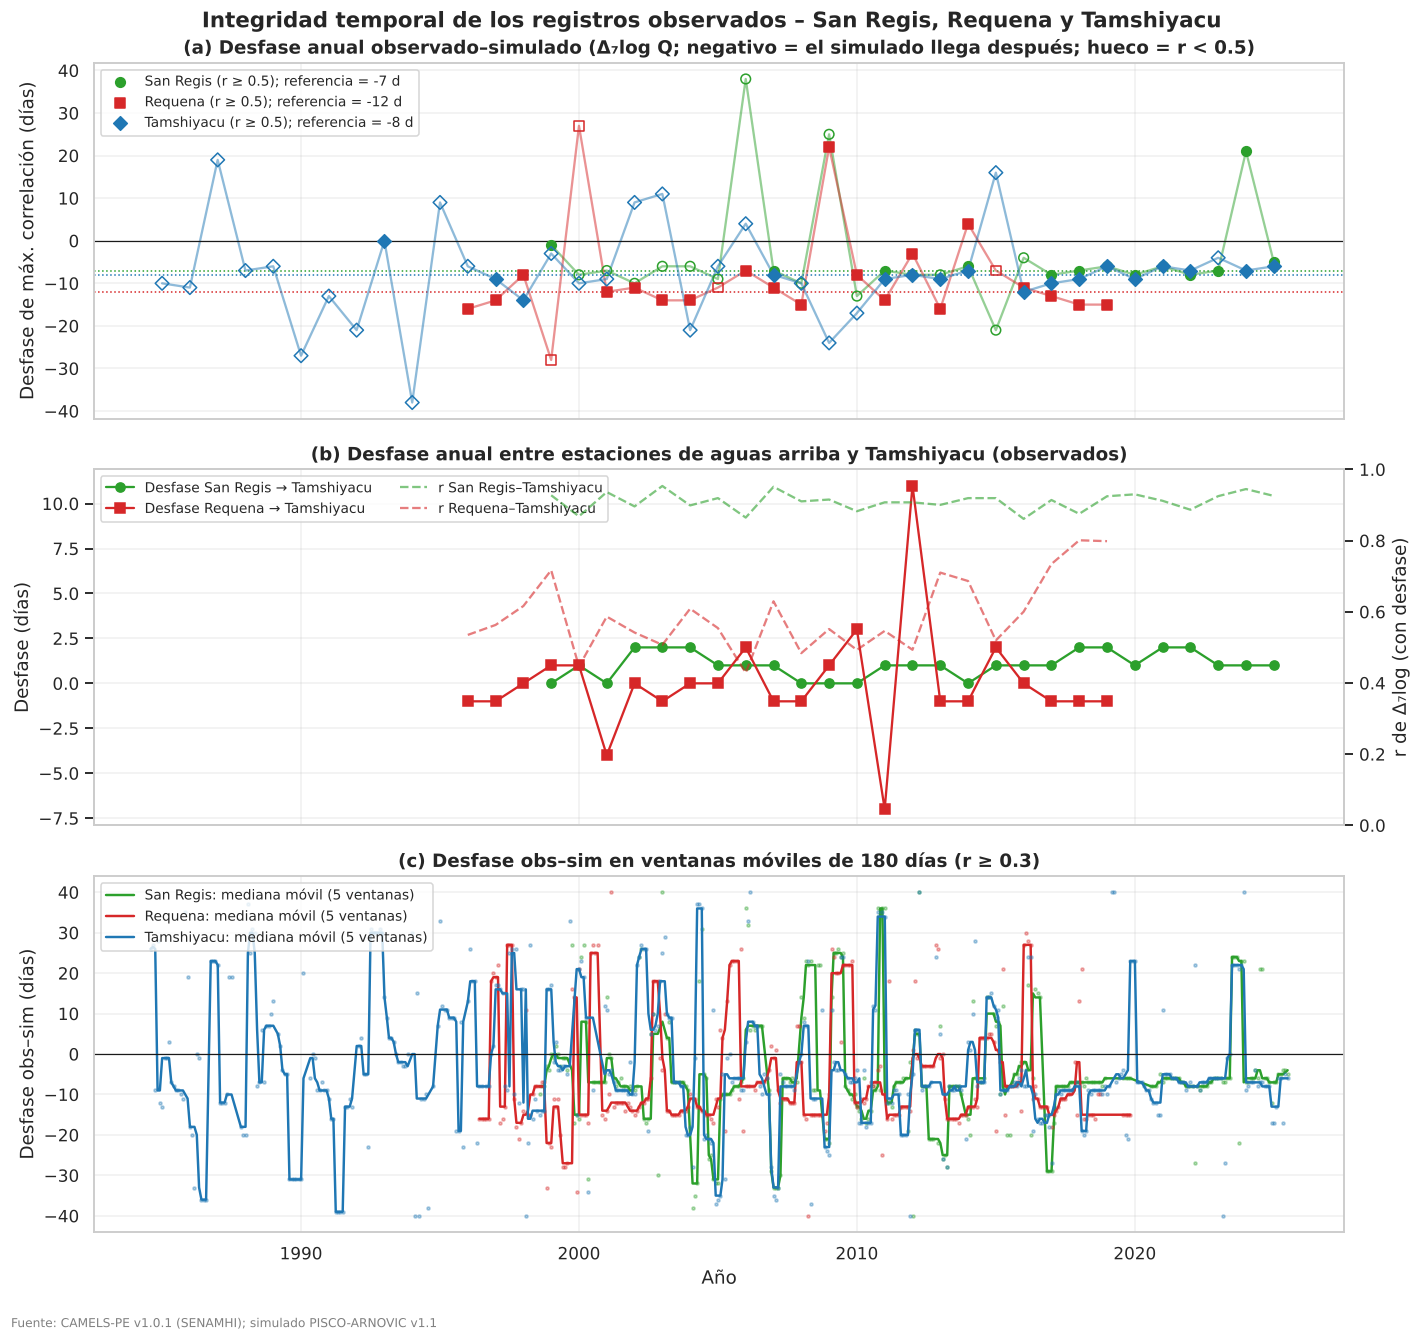

In [10]:
fig, ejes = plt.subplots(3, 1, figsize=(13, 12), sharex=True)
ti = tabla_integridad
ax = ejes[0]
for n, marcador in zip(ESTACIONES.values(), ['o', 's', 'D']):
    l, r = ti[f'desfase obs–sim {n} (d)'], ti[f'r obs–sim {n}']
    ax.plot(ti.index, l, '-', color=COLORES[n], alpha=0.5)
    ax.scatter(ti.index[r >= 0.5], l[r >= 0.5], marker=marcador, color=COLORES[n], s=40, zorder=4,
               label=f'{n} (r ≥ 0.5); referencia = {ref_lag[n]} d')
    ax.scatter(ti.index[r < 0.5], l[r < 0.5], marker=marcador, facecolors='none', edgecolors=COLORES[n], s=40, zorder=4)
    ax.axhline(ref_lag[n], color=COLORES[n], ls=':', lw=1)
ax.axhline(0, color='k', lw=0.8)
ax.set_ylabel('Desfase de máx. correlación (días)')
ax.set_title('(a) Desfase anual observado–simulado (Δ₇log Q; negativo = el simulado llega después; hueco = r < 0.5)', fontweight='bold')
ax.legend(fontsize=9, loc='upper left'); ax.grid(True, alpha=0.3)

ax = ejes[1]
ax2 = ax.twinx()
for u, marcador in zip(AGUAS_ARRIBA, ['o', 's']):
    ax.plot(ti.index, ti[f'desfase {u}–{SALIDA} (d)'], marker=marcador, color=COLORES[u], label=f'Desfase {u} → {SALIDA}')
    ax2.plot(ti.index, ti[f'r {u}–{SALIDA}'], ls='--', color=COLORES[u], alpha=0.6, label=f'r {u}–{SALIDA}')
ax.set_ylabel('Desfase (días)'); ax2.set_ylabel('r de Δ₇log (con desfase)'); ax2.set_ylim(0, 1); ax2.grid(False)
ax.set_title(f'(b) Desfase anual entre estaciones de aguas arriba y {SALIDA} (observados)', fontweight='bold')
h1, e1 = ax.get_legend_handles_labels(); h2, e2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, e1 + e2, fontsize=9, loc='upper left', ncol=2); ax.grid(True, alpha=0.3)

ax = ejes[2]
for n in ESTACIONES.values():
    v = ventanas[n]
    ax.plot(v.index.year + v.index.dayofyear / 365, v['desfase'], '.', color=COLORES[n], alpha=0.35, ms=4)
    ax.plot(v.index.year + v.index.dayofyear / 365, v['mediana_movil'], '-', color=COLORES[n], lw=1.6, label=f'{n}: mediana móvil (5 ventanas)')
ax.axhline(0, color='k', lw=0.8)
ax.set_ylabel('Desfase obs–sim (días)'); ax.set_xlabel('Año')
ax.set_title('(c) Desfase obs–sim en ventanas móviles de 180 días (r ≥ 0.3)', fontweight='bold')
ax.legend(fontsize=9, loc='upper left'); ax.grid(True, alpha=0.3)
fig.suptitle('Integridad temporal de los registros observados – San Regis, Requena y Tamshiyacu', fontsize=14, fontweight='bold')
nota_fuente(fig)
plt.tight_layout()
fig.savefig(RUTA_FIG / 'fig02_integridad_temporal.png', dpi=200, bbox_inches='tight')
plt.show()

**Interpretación:**
- **Panel (a):** los años con r ≥ 0.5 (marcadores rellenos) se agrupan casi todos entre −16 y −1 días, alrededor de las referencias (−7, −12 y −8 días).
  - Hay pocas excepciones: Requena 2009 (+22), San Regis 2024 (+21) y Requena 2014 (+4).
  - Los valores más extremos (+38, +27 y −38 días) son años de señal débil (marcadores huecos).
  - No hay ninguna rampa como la que produciría un error de fechas acumulado.
- **Panel (b):** el desfase San Regis → Tamshiyacu es estable (0–2 días, r ≈ 0.9). El de Requena oscila alrededor de −1 a 0 días, salvo 2001 (−4), 2011 (−7) y 2012 (+11), con r < 0.6.
- **Panel (c):** las ventanas de 180 días muestran el mismo retardo, de −5 a −15 días, en los tramos con señal clara. Los saltos a +20/+35 días corresponden a ventanas con r bajo.

**2.7 (continuación) — Escalones de nivel en los límites del calendario**
En cada estación, el cambio diario |Δlog Q| del **día 1 de cada mes** frente al de los demás días: (a) cuenta los días 1 cuyo cambio supera el **mayor** cambio observado en cualquier otro día del registro ("escalones"), con su mes, signo y tamaño; (b) prueba binomial (unilateral) de si el 1 ‰ de cambios diarios más grandes cae en días 1 más a menudo que lo esperado por azar (1 de cada ~30 días); (c) lo mismo para el simulado en las mismas fechas. Define los **años sin escalones** (sin escalón el 1 de enero, el 1 de setiembre ni el 1 de enero siguiente) para la sensibilidad de 5.2.
**Por qué:** un río de 3.5–7.2 × 10⁵ km² no puede cambiar su caudal en decenas de por ciento de un día a otro. Si los cambios más grandes del registro se concentran justo en el cambio de mes, no son hidrológicos: indican que el registro se armó por bloques con niveles distintos (por ejemplo, distintas curvas de descarga o fuentes por bloque). No es un error de fechas, por lo que no se detecta en 2.7, ni un punto aislado, por lo que no lo eliminan las reglas de 4.3.

In [11]:
filas_esc, escalones, anios_sin_escalon = [], {}, {}
for n, df in series.items():
    dl = np.log(df['qobs']).diff().dropna()
    dia1 = dl.index.day == 1
    umbral = dl[~dia1].abs().max()
    esc = dl[dia1 & (dl.abs() > umbral)]
    escalones[n] = esc
    k = max(1, int(round(0.001 * len(dl))))
    top = dl.abs().nlargest(k)
    en_dia1 = int((top.index.day == 1).sum())
    ds = np.log(df['qsim']).diff().where(df['qobs'].notna()).dropna()
    top_s = ds.abs().nlargest(k)
    anios = sorted(set(df['qobs'].dropna().index.year))
    fechas_esc = set(esc.index)
    anios_sin_escalon[n] = [a for a in anios if not ({pd.Timestamp(a, 1, 1), pd.Timestamp(a, 9, 1), pd.Timestamp(a + 1, 1, 1)} & fechas_esc)]
    filas_esc.append({'estación': n, 'máx |Δlog Q| en días ≠ 1': umbral,
                      'escalones (día 1 > ese máximo)': len(esc),
                      'en enero / setiembre / otros': f"{(esc.index.month == 1).sum()} / {(esc.index.month == 9).sum()} / {(~esc.index.month.isin([1, 9])).sum()}",
                      'subidas / bajadas': f"{(esc > 0).sum()} / {(esc < 0).sum()}",
                      'tamaño mediano (%)': 100 * (np.exp(esc.abs().median()) - 1) if len(esc) else np.nan,
                      'primer / último escalón': f"{esc.index.min():%Y-%m-%d} / {esc.index.max():%Y-%m-%d}" if len(esc) else '—',
                      f'top 1 ‰ obs en día 1': f"{en_dia1} de {k}",
                      'p binomial obs': stats.binomtest(en_dia1, k, p=dia1.mean(), alternative='greater').pvalue,
                      f'top 1 ‰ sim en día 1': f"{int((top_s.index.day == 1).sum())} de {k}",
                      'años sin escalones': len(anios_sin_escalon[n]), 'de años con dato': len(anios)})
tabla_escalones = pd.DataFrame(filas_esc).set_index('estación')
tabla_escalones.to_csv(RUTA_TAB / 'tabla_escalones_calendario.csv')
display(tabla_escalones.T)
for n, esc in escalones.items():
    if len(esc):
        print(f"{n}: " + ', '.join(f"{f:%Y-%m-%d} ({100 * (np.exp(v) - 1):+.0f} %)" for f, v in esc.items()))

estación,San Regis,Requena,Tamshiyacu
máx |Δlog Q| en días ≠ 1,0.202666,0.352492,0.160197
escalones (día 1 > ese máximo),17,1,41
en enero / setiembre / otros,10 / 6 / 1,0 / 1 / 0,21 / 20 / 0
subidas / bajadas,7 / 10,1 / 0,20 / 21
tamaño mediano (%),48.931384,89.045936,52.64468
primer / último escalón,1999-01-01 / 2024-11-01,2017-09-01 / 2017-09-01,1985-01-01 / 2014-01-01
top 1 ‰ obs en día 1,9 de 9,2 de 8,15 de 15
p binomial obs,0.0,0.026121,0.0
top 1 ‰ sim en día 1,8 de 9,5 de 8,12 de 15
años sin escalones,12,24,12


San Regis: 1999-01-01 (+53 %), 1999-09-01 (-40 %), 2000-01-01 (-31 %), 2001-01-01 (+68 %), 2004-01-01 (-23 %), 2005-09-01 (-38 %), 2006-09-01 (+49 %), 2008-01-01 (-43 %), 2008-09-01 (-51 %), 2009-01-01 (+100 %), 2010-01-01 (-33 %), 2010-09-01 (-20 %), 2011-01-01 (+53 %), 2011-09-01 (-31 %), 2013-01-01 (-29 %), 2014-01-01 (+36 %), 2024-11-01 (+26 %)
Requena: 2017-09-01 (+89 %)
Tamshiyacu: 1985-01-01 (-38 %), 1985-09-01 (-24 %), 1986-01-01 (+59 %), 1986-09-01 (+39 %), 1987-09-01 (+24 %), 1988-01-01 (-41 %), 1988-09-01 (-32 %), 1989-01-01 (-25 %), 1990-01-01 (+162 %), 1990-09-01 (+39 %), 1991-01-01 (-41 %), 1991-09-01 (-50 %), 1992-01-01 (+59 %), 1993-09-01 (+50 %), 1994-09-01 (+73 %), 1995-01-01 (-17 %), 1995-09-01 (-36 %), 1997-01-01 (+30 %), 1998-01-01 (-29 %), 1999-01-01 (+30 %), 1999-09-01 (-41 %), 2000-01-01 (-42 %), 2000-09-01 (+37 %), 2001-01-01 (+73 %), 2001-09-01 (-18 %), 2004-01-01 (-16 %), 2004-09-01 (+98 %), 2005-09-01 (-37 %), 2006-01-01 (+23 %), 2006-09-01 (+32 %), 2008-01-

**Interpretación — el observado de San Regis y Tamshiyacu está armado por bloques con niveles distintos.**
- **Tamshiyacu:** el mayor cambio diario en cualquier día que no es 1 de mes es |Δlog Q| = 0.160 (≈ 17 %).
  - Hay **41 días 1** que lo superan, **todos el 1 de enero (21) o el 1 de setiembre (20)**, entre 1985-01-01 y 2014-01-01.
  - Su tamaño mediano es del **53 %**, con 20 subidas y 21 bajadas. El mayor es 1990-01-01: **+162 %** (de 15 251 a 39 981 m³/s).
  - Los 15 cambios diarios más grandes del registro (el 1 ‰) caen todos en día 1 (binomial p < 10⁻¹⁵).
- **San Regis:** 17 escalones (10 en enero, 6 en setiembre, 1 en noviembre), de mediana 49 %, entre 1999-01-01 y 2024-11-01.
  - En 1999–2014, la mayoría coincide en fecha y signo con los de Tamshiyacu (por ejemplo, 2008-09-01: −51 % y −36 %; 2009-01-01: +100 % y +79 %).
  - Sus 9 cambios más grandes caen en día 1.
- **Requena:** un solo escalón, 2017-09-01 (+89 %). Es el fin del estiaje anómalo de 2017 (4.4), no un patrón de bloques.

**Lectura:**
- **No son crecidas:** el nivel nuevo persiste los días siguientes, no hay un cambio similar en el simulado y ocurren siempre en las mismas dos fechas del calendario.
- **Lo más probable** es que los bloques enero–agosto y setiembre–diciembre de cada año se hayan procesado por separado, con curvas de descarga, fuentes o niveles de referencia distintos. Es una inferencia que debe confirmarse con SENAMHI.
- **No se puede saber qué bloque es el correcto:** por eso no se corrige ni se elimina nada.
- **Tratamiento:**
  - se usa el registro completo;
  - en 5.2 se repiten las métricas solo con los **12 años sin escalones** de cada una de estas estaciones;
  - H4 usa solo pares de días dentro del mes, lo que excluye los escalones.
- **El simulado también** concentra en día 1 sus mayores cambios (8 de 9 y 12 de 15), por su corrección mensual (2.6).

**Figura de escalones:** (a)–(c) cambio diario |Δlog Q| del observado de cada estación a lo largo del registro, con los días 1 de enero y de setiembre resaltados y el máximo de los demás días como referencia; (d) ejemplo: el escalón más grande del registro de la salida, con el simulado en las mismas fechas.

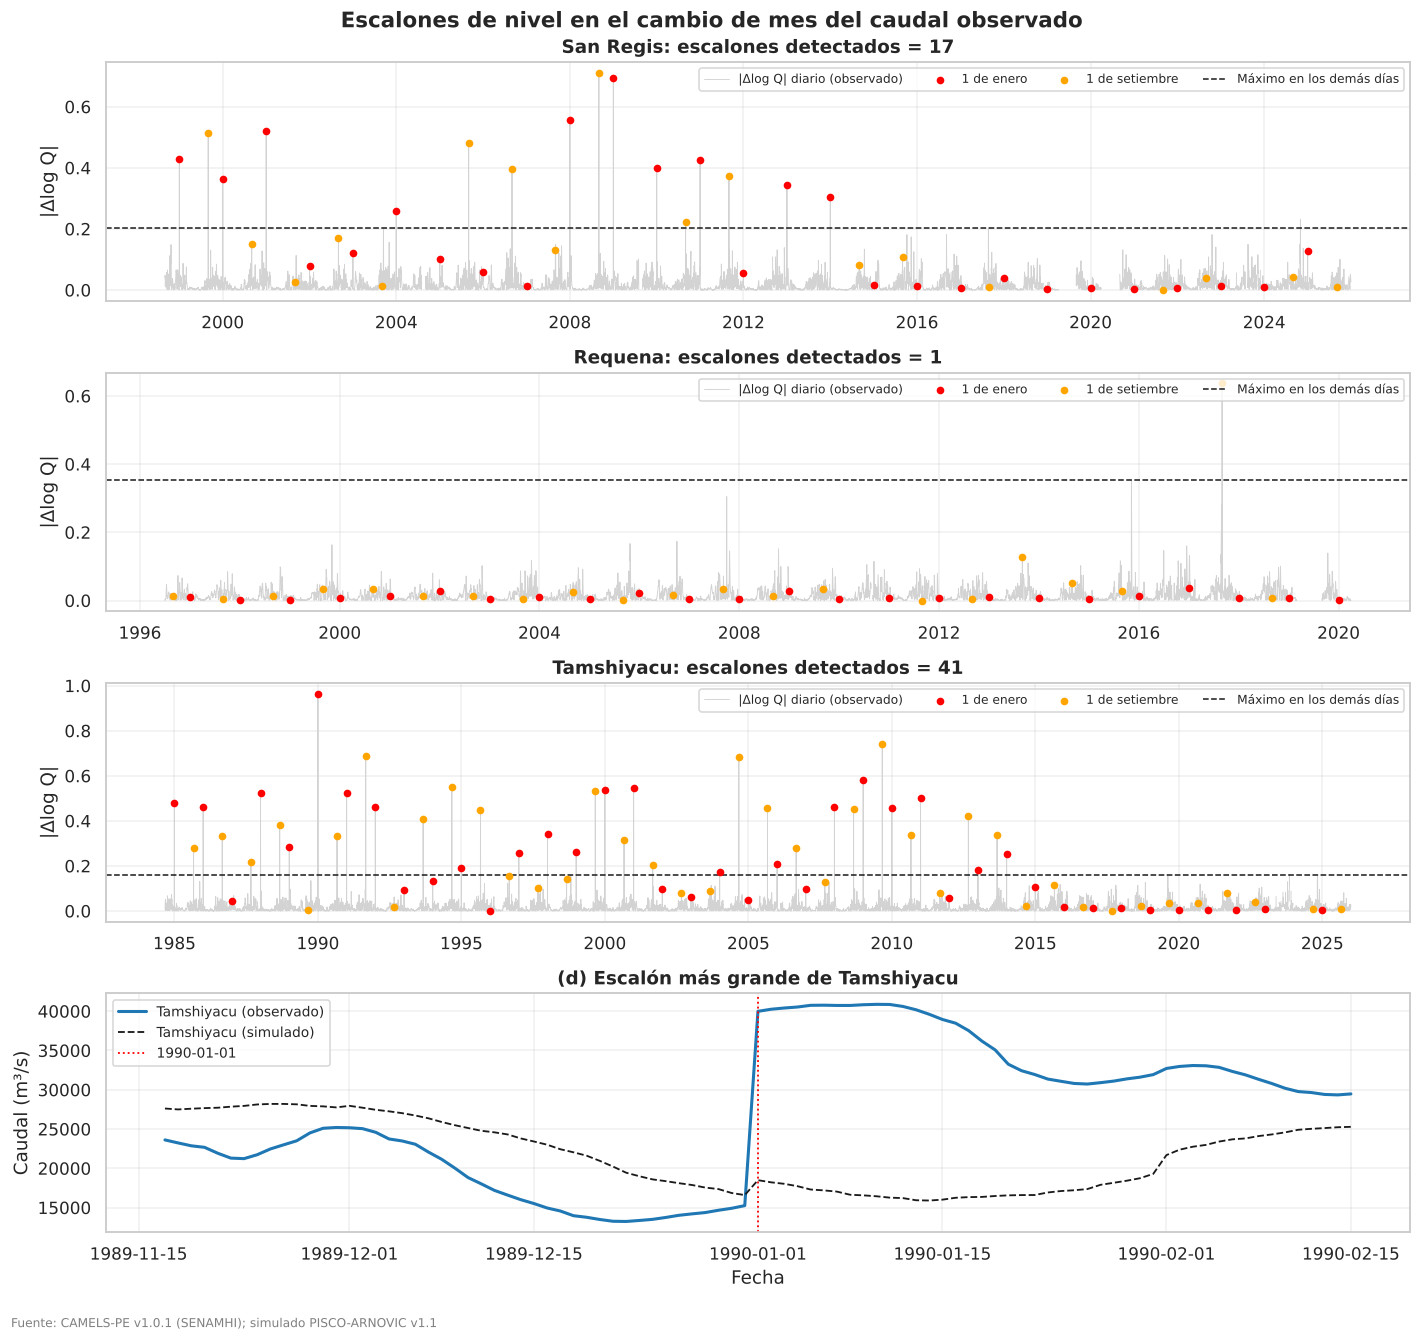

In [12]:
fig, ejes = plt.subplots(len(ESTACIONES) + 1, 1, figsize=(13, 3.0 * (len(ESTACIONES) + 1)))
for ax, (n, df) in zip(ejes, series.items()):
    dl = np.log(df['qobs']).diff().abs()
    ax.plot(dl.index, dl, color='lightgray', lw=0.6, label='|Δlog Q| diario (observado)')
    for mes, color, etiqueta in ((1, 'red', '1 de enero'), (9, 'orange', '1 de setiembre')):
        sel = (dl.index.day == 1) & (dl.index.month == mes)
        ax.scatter(dl.index[sel], dl[sel], color=color, s=16, zorder=4, label=etiqueta)
    ax.axhline(tabla_escalones.loc[n, 'máx |Δlog Q| en días ≠ 1'], color='k', ls='--', lw=1,
               label='Máximo en los demás días')
    ax.set_ylabel('|Δlog Q|'); ax.set_title(f"{n}: escalones detectados = {tabla_escalones.loc[n, 'escalones (día 1 > ese máximo)']}", fontweight='bold')
    ax.legend(fontsize=8, loc='upper right', ncol=4); ax.grid(True, alpha=0.3)
ax = ejes[-1]
f_ej = escalones[SALIDA].abs().idxmax() if len(escalones[SALIDA]) else series[SALIDA]['qobs'].first_valid_index()
x = slice(f_ej - pd.Timedelta(days=45), f_ej + pd.Timedelta(days=45))
ax.plot(series[SALIDA]['qobs'].loc[x], color=COLORES[SALIDA], lw=2, label=f'{SALIDA} (observado)')
ax.plot(series[SALIDA]['qsim'].loc[x], 'k--', lw=1.2, label=f'{SALIDA} (simulado)')
ax.axvline(f_ej, color='red', ls=':', lw=1.2, label=f'{f_ej:%Y-%m-%d}')
ax.set_ylabel('Caudal (m³/s)'); ax.set_xlabel('Fecha')
ax.set_title(f'(d) Escalón más grande de {SALIDA}', fontweight='bold'); ax.legend(fontsize=9); ax.grid(True, alpha=0.3)
fig.suptitle('Escalones de nivel en el cambio de mes del caudal observado', fontsize=14, fontweight='bold')
nota_fuente(fig)
plt.tight_layout()
fig.savefig(RUTA_FIG / 'fig02b_escalones_calendario.png', dpi=200, bbox_inches='tight')
plt.show()

**Interpretación:**
- **Paneles (a)–(c):** el patrón es inequívoco. En San Regis y Tamshiyacu, todos los puntos que sobresalen de la nube gris de cambios diarios son días 1 de enero (rojo) o de setiembre (naranja) y están por encima de la línea del máximo de los demás días.
  - Tamshiyacu tiene escalones casi todos los años hasta 2014. Desde 2015 no tiene ninguno.
  - San Regis no tiene escalones después de 2014, salvo uno menor en 2024-11-01.
  - Requena no muestra el patrón.
- **Panel (d):** el 1 de enero de 1990, el observado de Tamshiyacu salta de 15 251 a 39 981 m³/s y se queda en ese nivel, mientras el simulado sigue en ~17 000–18 000 m³/s. En diciembre de 1989 el observado estaba **por debajo** del simulado y en enero de 1990 queda **muy por encima**: al menos uno de los dos bloques está mal escalado.

### 2.8 Balance de caudales: Tamshiyacu vs San Regis + Requena (periodo con fechas confiables)
En los días en que las tres estaciones tienen dato **y** fechas confiables: la razón Q_Tamshiyacu / (Q_San Regis + Q_Requena) sin desfase (2.7 muestra que el tránsito entre ellas es de 0–2 días), su mediana por año y por mes, y la misma razón con el simulado.
**Por qué:** las dos estaciones de aguas arriba drenan el 98 % del área de Tamshiyacu. Sin pérdidas ni aportes externos, la razón debería estar cerca de la razón de áreas, algo mayor en época de lluvias si el área intermedia aporta más. Una razón claramente menor que 1 o muy variable indicaría error en alguna curva de descarga, desborde hacia la llanura de inundación o un error de fechas.

In [13]:
desde = max(inicio_confiable.values())
balance = pd.DataFrame({u: series[u]['qobs'] for u in AGUAS_ARRIBA} | {SALIDA: q_sal}).loc[desde:].dropna()
balance['arriba'] = balance[AGUAS_ARRIBA].sum(axis=1)
balance['razon'] = balance[SALIDA] / balance['arriba']
print(f"Periodo común con fechas confiables: {balance.index.min().date()} a {balance.index.max().date()} ({len(balance)} días)")
print(f"Razón Q_{SALIDA} / (Q_SR + Q_RQ): mediana = {balance['razon'].median():.3f}, P25–P75 = "
      f"{balance['razon'].quantile(.25):.3f}–{balance['razon'].quantile(.75):.3f}, P2.5–P97.5 = "
      f"{balance['razon'].quantile(.025):.3f}–{balance['razon'].quantile(.975):.3f} | razón de áreas = {area[SALIDA] / area_arriba:.3f}")
print(f"Razón de volúmenes en el periodo común (Σ{SALIDA} / Σaguas arriba) = {balance[SALIDA].sum() / balance['arriba'].sum():.3f}")
print('\nMediana por año:', balance.groupby(balance.index.year)['razon'].median().round(3).to_dict())
sim_arriba = sum(series[u]['qsim'] for u in AGUAS_ARRIBA)
mens = pd.DataFrame({'obs': balance.groupby(balance.index.month)['razon'].median(),
                     'sim (1981–2025)': (series[SALIDA]['qsim'] / sim_arriba).groupby(series[SALIDA].index.month).median()}).round(3)
print('\nMediana mensual de la razón Q_T / (Q_SR + Q_RQ):')
print(mens.T.to_string())

Periodo común con fechas confiables: 1998-09-01 a 2020-03-31 (7560 días)
Razón Q_Tamshiyacu / (Q_SR + Q_RQ): mediana = 1.022, P25–P75 = 0.970–1.090, P2.5–P97.5 = 0.861–1.256 | razón de áreas = 1.016
Razón de volúmenes en el periodo común (ΣTamshiyacu / Σaguas arriba) = 1.035

Mediana por año: {1998: 0.963, 1999: 0.97, 2000: 0.958, 2001: 0.98, 2002: 1.056, 2003: 0.998, 2004: 1.026, 2005: 1.018, 2006: 1.043, 2007: 0.99, 2008: 1.008, 2009: 0.963, 2010: 1.061, 2011: 1.092, 2012: 1.049, 2013: 1.034, 2014: 1.119, 2015: 0.977, 2016: 1.099, 2017: 1.172, 2018: 1.01, 2019: 1.023, 2020: 0.972}

Mediana mensual de la razón Q_T / (Q_SR + Q_RQ):
date                1      2      3      4      5      6      7      8      9      10     11     12
obs              1.001  0.999  1.004  1.031  1.078  1.095  1.105  1.086  1.029  0.991  0.998  0.998
sim (1981–2025)  1.014  1.022  1.038  1.056  1.091  1.140  1.146  1.153  1.123  1.087  1.045  1.025


**Interpretación:**
- **El balance cierra.** En 7 560 días comunes (1998-09-01 a 2020-03-31), la mediana de Q_T / (Q_SR + Q_RQ) es **1.022** (P25–P75: 0.970–1.090), frente a una razón de áreas de 1.016. La razón de volúmenes es 1.035. Que el balance cierre con tres estaciones independientes es una **verificación externa** del nivel de las tres series.
- **Ciclo estacional físicamente coherente:**
  - Enero–marzo: razón ≈ 1.00.
  - Mayo–agosto (descenso de aguas): 1.08–1.105. Tamshiyacu baja más lento que la suma de sus afluentes, como corresponde al vaciado de la llanura de inundación entre las estaciones.
  - El simulado reproduce el mismo patrón (1.09–1.15 en mayo–setiembre).
- **Variabilidad interanual:** la mediana por año va de 0.958 (2000) a 1.172 (2017). El año 2017 es anómalo (ver 4.4).

---
## 3. Valores faltantes

### 3.1 Diagnóstico: cantidad y estructura
Dentro del periodo de registro de cada estación, los vacíos se cuentan y agrupan en rachas aisladas (≤ 3 días), medias (4–30) y largas (> 30); también se revisan las demás variables. Si 2.7 recortó el periodo de alguna estación, se reporta además el periodo con fechas confiables.
**Por qué:** el tratamiento depende de la estructura (guía del equipo, 3.4, punto 2).

In [14]:
def rachas_vacios(s):
    """Longitudes de las rachas de NaN dentro del periodo de registro de una serie."""
    tramo = s.loc[s.first_valid_index():s.last_valid_index()]
    es_nan = tramo.isna().astype(int)
    grupo = (es_nan.diff() != 0).cumsum()
    rachas = es_nan.groupby(grupo).agg(['first', 'size'])
    rachas = rachas[rachas['first'] == 1]
    inicio = tramo.groupby(grupo).apply(lambda x: x.index.min())
    return pd.DataFrame({'inicio': inicio.loc[rachas.index].values, 'dias': rachas['size'].values})

recortadas = [n for n in ESTACIONES.values() if inicio_confiable[n] > series[n]['qobs'].first_valid_index()]
casos_vac = []
for n in ESTACIONES.values():
    if n in recortadas:
        casos_vac += [(f'{n} (registro completo)', n, series[n]['qobs']),
                      (n, n, series[n]['qobs'].loc[inicio_confiable[n]:])]
    else:
        casos_vac.append((n, n, series[n]['qobs']))

filas, detalle_largos = [], []
for etiqueta, nombre, s in casos_vac:
    r = rachas_vacios(s)
    tramo = s.loc[s.first_valid_index():s.last_valid_index()]
    filas.append({'serie': etiqueta, 'periodo': f"{tramo.index.min():%Y-%m-%d} a {tramo.index.max():%Y-%m-%d}",
                  'días en periodo': len(tramo), 'días vacíos': int(tramo.isna().sum()),
                  '% vacíos': round(100 * tramo.isna().mean(), 2), 'n rachas': len(r),
                  'aisladas (≤3 d)': int((r['dias'] <= 3).sum()), 'medias (4–30 d)': int(r['dias'].between(4, 30).sum()),
                  'largas (>30 d)': int((r['dias'] > 30).sum()), 'días en rachas largas': int(r.loc[r['dias'] > 30, 'dias'].sum()),
                  'racha máxima (d)': int(r['dias'].max()) if len(r) else 0})
    if etiqueta == nombre:
        for _, fila in r[r['dias'] > 30].iterrows():
            detalle_largos.append({'estación': nombre, 'inicio': fila['inicio'].date(), 'días': fila['dias']})

tabla_vacios_det = pd.DataFrame(filas).set_index('serie')
print(tabla_vacios_det.to_string())
tabla_vacios = tabla_vacios_det.loc[list(ESTACIONES.values())]
tabla_vacios.to_csv(RUTA_TAB / 'tabla_vacios.csv')
print('\nRachas largas (> 30 días):')
print(pd.DataFrame(detalle_largos).to_string(index=False) if detalle_largos else 'ninguna')
print(f'\nOtras variables ({SALIDA}; mismo patrón en las tres): vacíos y periodo con dato')
otras = series[SALIDA].drop(columns=['flow_obs', 'qobs', 'qsim'])
print(pd.DataFrame({'vacíos': otras.isna().sum(),
                    'primer dato': otras.apply(lambda c: c.first_valid_index().date()),
                    'último dato': otras.apply(lambda c: c.last_valid_index().date())}).to_string())

                            periodo  días en periodo  días vacíos  % vacíos  n rachas  aisladas (≤3 d)  medias (4–30 d)  largas (>30 d)  días en rachas largas  racha máxima (d)
serie                                                                                                                                                                           
San Regis   1998-09-01 a 2025-12-31             9984          456      4.57        44               32               10               2                    300               153
Requena     1996-07-01 a 2020-03-31             8675          223      2.57        18               14                3               1                    180               180
Tamshiyacu  1984-09-01 a 2025-12-31            15097           69      0.46        36               29                7               0                      0                 6

Rachas largas (> 30 días):
 estación     inicio  días
San Regis 2019-04-07   147
San Regis 2020-04-01   153
  Requ

**Interpretación:**
- **Tamshiyacu** es casi continua: 0.46 % de vacíos (69 días), en rachas de 6 días como máximo.
- **San Regis:** 4.57 % de vacíos. Casi dos tercios de ellos (300 de 456 días) están en dos rachas largas: 2019-04-07 (147 días) y 2020-04-01 (153 días).
- **Requena:** 2.57 % de vacíos. Su única racha larga es 2019-03-05 (180 días); después la serie se reanuda brevemente y termina en 2020-03-31.
- **Otras variables:** lluvia y radiación están completas en 1981–2025. La ETP termina en 2016-12-31 y la temperatura en 2020-12-31; esto limita los modelos que las usen.

### 3.2 Mapa de calor de disponibilidad
Fracción de días con dato observado por mes y estación (1981–2025) con `sns.heatmap` (Lab4_2).
**Por qué:** muestra el periodo común y los bloques vacíos.

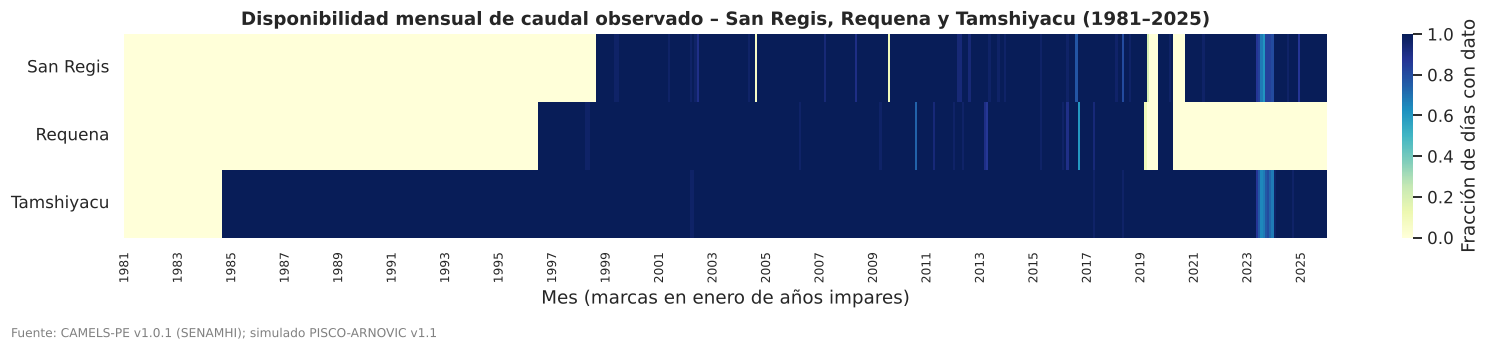

Días con dato en las tres estaciones: 7560 (1998-09-01 a 2020-03-31)


In [15]:
disp = pd.DataFrame({n: series[n]['flow_obs'].notna() for n in ESTACIONES.values()})
for n in recortadas:
    disp[f'{n} (fechas confiables)'] = disp[n] & (series[n].index >= inicio_confiable[n])
disp_mensual = disp.resample('MS').mean().T
fig, ax = plt.subplots(figsize=(15, 1.2 + 0.6 * len(disp_mensual)))
sns.heatmap(disp_mensual, cmap='YlGnBu', vmin=0, vmax=1, ax=ax, cbar_kws={'label': 'Fracción de días con dato'})
etiquetas = [f'{c.year}' if (c.month == 1 and c.year % 2 == 1) else '' for c in disp_mensual.columns]
ax.set_xticks(np.arange(len(etiquetas)) + 0.5)
ax.set_xticklabels(etiquetas, rotation=90, fontsize=8)
ax.set_xlabel('Mes (marcas en enero de años impares)'); ax.set_ylabel('')
ax.set_title('Disponibilidad mensual de caudal observado – San Regis, Requena y Tamshiyacu (1981–2025)', fontweight='bold')
nota_fuente(fig)
plt.tight_layout()
fig.savefig(RUTA_FIG / 'fig01_disponibilidad.png', dpi=200, bbox_inches='tight')
plt.show()
comun = disp[list(ESTACIONES.values())].all(axis=1)
print(f"Días con dato en las tres estaciones: {int(comun.sum())} "
      f"({comun[comun].index.min().date()} a {comun[comun].index.max().date()})")

**Interpretación:** el mapa de calor muestra el periodo común de las tres estaciones: **7 560 días** entre 1998-09-01 y 2020-03-31. Tamshiyacu es la única serie con dato antes de 1996 y la que cubre de forma continua 2021–2025. El hueco 2019–2020 de San Regis y Requena coincide en el tiempo, por lo que el periodo común real termina en la práctica en 2019-03.

### 3.3 Criterio de tratamiento (fijado antes de modelar)
| Uso | Tratamiento | Justificación |
|---|---|---|
| Métricas obs vs sim (secciones 5 y 7) | **Sin imputación**: solo fechas con observado y simulado válidos | Rellenar el observado introduciría información del modelo en la referencia. |
| Tramos con fechas no confiables (solo si 2.7 detecta deriva) | **Se excluyen del análisis diario** | No es un vacío sino un error de fechas; realinear exigiría suponer el desfase día a día. |
| Agregados mensuales | Mes válido solo si faltan ≤ 10 días y no hay ≥ 5 días seguidos faltantes | WMO-No. 1203 (2017), §4.4.1. |
| Autocorrelación y *flashiness* | Sin imputación; solo pares de días consecutivos válidos | `autocorr` y `diff` ignoran pares incompletos. |
| Descomposición (serie continua) | Interpolación lineal solo en vacíos ≤ 3 días; tramo continuo más largo | Guía del equipo (3.4, punto 2) y Ses6a. |
| Bloques > 30 días | No se imputan | Ningún relleno reproduce crecidas no observadas. |

La interpolación ≤ 3 días se aplica a una copia y se mide su efecto en la media, la desviación y el P90.

In [16]:
def interpolar_cortos(s, max_dias=3):
    """Interpola linealmente solo rachas de NaN de longitud ≤ max_dias."""
    es_nan = s.isna()
    grupo = (es_nan != es_nan.shift()).cumsum()
    largo = es_nan.groupby(grupo).transform('sum')
    candidata = s.interpolate(method='time', limit_area='inside')
    return s.where(~(es_nan & (largo <= max_dias)), candidata)

efecto = []
for nombre, df in series.items():
    s0 = df['qobs'].loc[inicio_confiable[nombre]:]
    s1 = interpolar_cortos(s0)
    efecto.append({'estación': nombre, 'días imputados': int(s1.notna().sum() - s0.notna().sum()),
                   'media antes': s0.mean(), 'media después': s1.mean(), 'desv. antes': s0.std(), 'desv. después': s1.std(),
                   'P90 antes': s0.quantile(.9), 'P90 después': s1.quantile(.9)})
tabla_efecto = pd.DataFrame(efecto).set_index('estación').round(1)
tabla_efecto['cambio media (%)'] = (100 * (tabla_efecto['media después'] / tabla_efecto['media antes'] - 1)).round(3)
tabla_efecto

,días imputados,media antes,media después,desv. antes,desv. después,P90 antes,P90 después,cambio media (%)
estación,,,,,,,,
San Regis,45,17669.2,17692.7,5736.7,5741.4,24978.2,25009.9,0.133
Requena,19,11541.0,11556.8,5663.4,5667.6,19056.5,19064.5,0.137
Tamshiyacu,33,30007.8,29997.3,11458.3,11461.8,45381.4,45378.9,-0.035


**Interpretación:** la interpolación de vacíos ≤ 3 días rellenaría 45 (San Regis), 19 (Requena) y 33 días (Tamshiyacu). Cambia la media en +0.133 %, +0.137 % y −0.035 % y el P90 en menos de 32 m³/s. El efecto es despreciable. Aun así, según el criterio de 3.3, las métricas usan solo días observados.

---
## 4. Outliers: errores de medición vs. crecidas reales

Principio: **una crecida no se elimina por ser extrema**; solo se elimina un dato con evidencia de error.
1. **Pruebas físicas:** negativos, ceros, líneas planas ≥ 7 días, saltos > 4σ.
2. **Criterios estadísticos** (solo señalan candidatos): IQR (1.5·RIC, Lab4_2) y z robusto MAD (|z| > 3.5; Iglewicz y Hoaglin, 1993) sobre **log(Q + ε)** y sobre su variación diaria Δlog (3·RIC).
3. **Corroboración física** (decide): (a) **caída aislada**: baja a menos de la mitad del promedio de sus vecinos y se recupera al día siguiente; (b) **pico aislado sin lluvia**: sube a más del doble y revierte, con lluvia de 3 días < P25; (c) **nivel bajo extremo**: valor marcado a la vez por IQR y MAD y por debajo de la mediana. En (a) y (b) se exige además que los dos vecinos estén dentro de un factor 2 entre sí (el día siguiente **vuelve al nivel previo**).

4. **Inconsistencia de balance atribuible** (4.4, posible solo porque hay tres estaciones anidadas): un mes con más de la mitad de sus días fuera del rango físico de Q_T / (Q_SR + Q_RQ) se atribuye a una estación solo si **esa** estación, y ninguna otra, tiene una razón mensual obs/sim anómala (|z robusto| > 3.5 respecto de su propia distribución de meses). Ese mes se excluye de esa estación. Son dos referencias independientes del observado de la estación (las otras dos estaciones y el simulado) que coinciden.

**Sobre la variación diaria en estos ríos:** con áreas de cientos de miles de km² y caudal de base alto (`baseflow_index` ≈ 0.84–0.88; ver 2.1), el caudal no puede duplicarse ni caer a la mitad en un día; un cambio de ese tamaño que revierte al día siguiente solo puede ser un error de lectura o de digitación. Por eso aquí las reglas (a) y (b) son especialmente discriminantes.

### 4.1 Pruebas físicas
Conteo de negativos, ceros, la racha más larga de valores idénticos (con la lista de las ≥ 7 días) y los saltos > 4σ, en el periodo con fechas confiables.

In [17]:
filas, planas = [], []
for nombre, df in series.items():
    q = df['qobs'].loc[inicio_confiable[nombre]:]
    v = q.dropna()
    grupo_igual = (v.diff() != 0).cumsum()
    tam = v.groupby(grupo_igual).transform('size')
    for g in grupo_igual[tam >= 7].unique():
        tramo = v[grupo_igual == g]
        planas.append({'estación': nombre, 'inicio': tramo.index[0].date(), 'días': len(tramo), 'Q (m³/s)': round(tramo.iloc[0], 1)})
    salto = q.diff().abs()
    filas.append({'estación': nombre, 'negativos': int((q < 0).sum()), 'ceros': int((q == 0).sum()),
                  'racha máx. de valores idénticos (d)': int(tam.max()),
                  'rachas planas ≥ 7 d': int(len(grupo_igual[tam >= 7].unique())),
                  'saltos > 4σ': int((salto > 4 * q.diff().std()).sum()), 'mín (m³/s)': round(q.min(), 1),
                  'máx |ΔQ| diario (m³/s)': round(salto.max(), 1), 'máx |ΔQ|/Q (%)': round(100 * (salto / q.shift()).max(), 1)})
display(pd.DataFrame(filas).set_index('estación'))
print('Rachas de valores idénticos ≥ 7 días:')
print(pd.DataFrame(planas).to_string(index=False) if planas else 'ninguna')

,negativos,ceros,racha máx. de valores idénticos (d),rachas planas ≥ 7 d,saltos > 4σ,mín (m³/s),máx |ΔQ| diario (m³/s),máx |ΔQ|/Q (%)
estación,,,,,,,,
San Regis,0,0,3,0,27,5084.0,11051.4,100.3
Requena,0,0,3,0,38,958.5,2029.7,89.0
Tamshiyacu,0,0,3,0,47,6130.5,24730.1,162.2


Rachas de valores idénticos ≥ 7 días:
ninguna


**Interpretación:**
- **Sin errores groseros:** no hay negativos ni ceros. La racha más larga de valores idénticos es de 3 días (no hay líneas planas ≥ 7 días).
- **Saltos > 4σ:** hay 27 (San Regis), 38 (Requena) y 47 (Tamshiyacu).
- **Cambios diarios imposibles:** el mayor cambio relativo de un día es de 100 % (San Regis), 89 % (Requena) y **162 %** (Tamshiyacu, +24 730 m³/s en un día). Un río de 7 × 10⁵ km² no puede duplicar su caudal en 24 horas.

Estos cambios no son crecidas. Como muestra 2.7 (escalones), son escalones de nivel en el cambio de mes que persisten en los días siguientes. Por eso no son puntos aislados y las reglas (a)–(b) de 4.3 no los eliminan.

### 4.2 Criterios estadísticos: IQR vs. z robusto (MAD)
Ambos criterios se aplican sobre log(Q + ε) (nivel) y sobre Δlog (cambio diario).

In [18]:
def marcas_iqr(x, k=1.5):
    """True donde x cae fuera de [Q1 − k·RIC, Q3 + k·RIC]."""
    q1, q3 = x.quantile([.25, .75])
    ric = q3 - q1
    return (x < q1 - k * ric) | (x > q3 + k * ric)

def z_robusto(x):
    """z modificado de Iglewicz y Hoaglin (1993): 0.6745·(x − mediana)/MAD."""
    mediana = x.median()
    mad = (x - mediana).abs().median()
    return 0.6745 * (x - mediana) / mad

candidatos, filas = {}, []
for nombre, df in series.items():
    q = df['qobs'].loc[inicio_confiable[nombre]:]
    lq = log_q(q)
    dl = lq.diff()
    marcas = pd.DataFrame({'iqr_nivel': marcas_iqr(lq), 'mad_nivel': z_robusto(lq).abs() > 3.5,
                           'iqr_cambio': marcas_iqr(dl, k=3.0), 'mad_cambio': z_robusto(dl).abs() > 3.5}
                          ).where(q.notna(), False).astype(bool)
    candidatos[nombre] = marcas
    filas.append({'estación': nombre, 'ε (m³/s)': round(q.mean() / 100, 1),
                  'IQR nivel': int(marcas['iqr_nivel'].sum()), 'MAD nivel': int(marcas['mad_nivel'].sum()),
                  'ambos nivel': int((marcas['iqr_nivel'] & marcas['mad_nivel']).sum()),
                  'nivel bajo (IQR)': int((marcas['iqr_nivel'] & (lq < lq.median())).sum()),
                  'IQR cambio (3·RIC)': int(marcas['iqr_cambio'].sum()), 'MAD cambio': int(marcas['mad_cambio'].sum()),
                  'ambos cambio': int((marcas['iqr_cambio'] & marcas['mad_cambio']).sum())})
pd.DataFrame(filas).set_index('estación')

,ε (m³/s),IQR nivel,MAD nivel,ambos nivel,nivel bajo (IQR),IQR cambio (3·RIC),MAD cambio,ambos cambio
estación,,,,,,,,
San Regis,176.7,35,0,0,35,249,572,249
Requena,115.4,11,15,11,11,227,461,227
Tamshiyacu,300.1,29,0,0,29,242,621,242


**Interpretación:**
- **Nivel:** con distribuciones casi simétricas, el IQR marca solo valores bajos: 35 en San Regis, 11 en Requena y 29 en Tamshiyacu. El MAD solo marca valores en Requena (15). Los **11 días marcados por ambos criterios** son los de Requena.
- **Cambio diario:** el MAD marca 461–621 días por estación y el IQR (3·RIC) 227–249, todos incluidos en los del MAD. La variación diaria normal es tan pequeña (MAD de Δlog muy bajo) que cualquier día de subida rápida queda marcado. Por eso estos criterios solo señalan candidatos y la decisión se toma con la corroboración física (4.3).

### 4.3 Corroboración y decisión
Con las reglas (a)–(c) se construye la bandera final de error, con la tabla de puntos eliminados y su motivo.

In [19]:
banderas, eliminados = {}, []
for nombre, df in series.items():
    q = df['qobs'].where(df.index >= inicio_confiable[nombre])
    lq = log_q(q)
    z_c = z_robusto(lq.diff())
    desvio = lq - (lq.shift(1) + lq.shift(-1)) / 2
    vecinos_similares = (lq.shift(-1) - lq.shift(1)).abs() < np.log(2)     # el día siguiente vuelve al nivel previo
    aislado = ((z_c.abs() > 3.5) & (z_c.shift(-1).abs() > 3.5) &
               (np.sign(z_c) != np.sign(z_c.shift(-1))) & (desvio.abs() > np.log(2)) & vecinos_similares)
    lluvia3 = df['prec'].rolling(3).sum()
    seco = lluvia3 < lluvia3.quantile(0.25)
    m = candidatos[nombre].reindex(df.index).fillna(False)
    reglas = pd.DataFrame({'caida_aislada': aislado & (desvio < 0),
                           'pico_aislado_sin_lluvia': aislado & (desvio > 0) & seco,
                           'nivel_bajo_extremo': m['iqr_nivel'] & m['mad_nivel'] & (lq < lq.median())}).fillna(False)
    error = reglas.any(axis=1)
    banderas[nombre] = error
    for fecha in error[error].index:
        eliminados.append({'estación': nombre, 'fecha': fecha.date(), 'Q obs (m³/s)': round(q.loc[fecha], 1),
                           'Q día anterior': round(q.shift(1).loc[fecha], 1), 'Q día siguiente': round(q.shift(-1).loc[fecha], 1),
                           'Q sim (m³/s)': round(df.loc[fecha, 'qsim'], 1), 'lluvia 3 d (mm)': round(lluvia3.loc[fecha], 1),
                           'motivo': ', '.join(reglas.columns[reglas.loc[fecha]])})
    # Candidatos aislados que se CONSERVAN (picos con lluvia): se listan para transparencia
    conservados = aislado & (desvio > 0) & ~seco
    print(f"{nombre}: picos aislados con lluvia conservados = {int(conservados.sum())}")

tabla_eliminados = pd.DataFrame(eliminados)
tabla_eliminados.to_csv(RUTA_TAB / 'tabla_outliers_eliminados.csv', index=False)
print('Puntos eliminados por estación:', tabla_eliminados.groupby('estación').size().to_dict() if len(tabla_eliminados) else {})
tabla_eliminados

San Regis: picos aislados con lluvia conservados = 0
Requena: picos aislados con lluvia conservados = 0
Tamshiyacu: picos aislados con lluvia conservados = 0
Puntos eliminados por estación: {'Requena': 11}


,estación,fecha,Q obs (m³/s),Q día anterior,Q día siguiente,Q sim (m³/s),lluvia 3 d (mm),motivo
0,Requena,2017-08-14,1200.1,1248.4,1171.9,4591.0,4.1,nivel_bajo_extremo
1,Requena,2017-08-15,1171.9,1200.1,1143.7,4522.5,3.9,nivel_bajo_extremo
2,Requena,2017-08-16,1143.7,1171.9,1107.5,4437.9,3.5,nivel_bajo_extremo
3,Requena,2017-08-17,1107.5,1143.7,1055.1,4385.6,11.5,nivel_bajo_extremo
4,Requena,2017-08-18,1055.1,1107.5,1014.8,4309.1,14.5,nivel_bajo_extremo
5,Requena,2017-08-19,1014.8,1055.1,970.5,4260.7,14.1,nivel_bajo_extremo
6,Requena,2017-08-20,970.5,1014.8,962.5,4220.5,12.8,nivel_bajo_extremo
7,Requena,2017-08-21,962.5,970.5,958.5,4172.1,13.7,nivel_bajo_extremo
8,Requena,2017-08-22,958.5,962.5,1035.0,4131.9,13.7,nivel_bajo_extremo
9,Requena,2017-08-23,1035.0,958.5,1184.0,4107.7,6.9,nivel_bajo_extremo


**Interpretación:**
- **Se eliminan 11 días, todos de Requena (2017-08-14 a 2017-08-24),** por la regla (c), nivel bajo extremo:
  - el observado baja a **958.5–1 200.1 m³/s**;
  - el simulado da 4 087.6–4 591.0 m³/s.
- **No hay puntos aislados:** ninguna caída ni pico aislado cumple las reglas (a)–(b), así que no se conservan picos con lluvia ni se elimina ninguno sin lluvia.
- **El error de Requena es mayor que esos 11 días:** forman parte de un descenso suave y continuo de varios meses. 4.4 muestra con el balance que el problema abarca todo el estiaje de 2017. San Regis y Tamshiyacu no tienen ningún punto eliminado.

### 4.4 Consistencia entre estaciones (diagnóstico)
Con el balance de 2.8 se marcan los días con Q_T / (Q_SR + Q_RQ) fuera de [0.8, 1.25] y se ubican en el tiempo junto a los tres hidrogramas.
**Por qué:** el área intermedia es menor al 2 % y el tránsito entre estaciones es corto, así que un día con la salida 20 % por debajo o 25 % por encima de la suma de sus afluentes es físicamente improbable. El balance por sí solo no indica cuál estación falla; por eso se aplica la regla de atribución (4) descrita arriba y se muestra, como verificación, el caudal de cada estación **implícito** por balance (Requena ≈ Tamshiyacu − San Regis, etc.).

Días fuera de [0.8, 1.25]: 263 de 7560 (3.48 %)
Por año-mes: {(2000, 1): 5, (2000, 8): 9, (2001, 1): 9, (2001, 2): 4, (2002, 6): 4, (2002, 7): 14, (2006, 5): 7, (2006, 6): 10, (2006, 8): 6, (2008, 5): 8, (2008, 6): 6, (2010, 5): 7, (2010, 6): 1, (2010, 7): 9, (2010, 8): 10, (2012, 8): 4, (2014, 6): 10, (2014, 7): 6, (2015, 1): 2, (2015, 2): 9, (2015, 7): 2, (2015, 8): 2, (2016, 7): 14, (2016, 8): 6, (2016, 11): 3, (2016, 12): 10, (2017, 1): 2, (2017, 5): 22, (2017, 6): 23, (2017, 7): 19, (2017, 8): 17, (2018, 6): 3}
            San Regis    Requena  Tamshiyacu  razon
date                                               
2000-01-01  13639.272  15564.950   20223.910  0.692
2000-01-02  14610.231  15363.592   21531.634  0.718
2000-01-03  15139.466  15174.316   22581.145  0.745
2000-01-04  15460.341  14985.039   23405.761  0.769
2000-01-05  15668.702  14791.736   24180.400  0.794
2000-08-19   9847.112   8561.729   14501.576  0.788
2000-08-20   9697.093   8525.485   13918.515  0.764
2000-08-21


Meses con > 15 días fuera de rango: 4


,días fuera de rango,razón mediana Q_T/(Q_SR+Q_RQ),z obs/sim San Regis,z obs/sim Requena,z obs/sim Tamshiyacu,San Regis: obs / implícito por balance,Requena: obs / implícito por balance,Tamshiyacu: obs / implícito por balance,estación responsable
mes,,,,,,,,,
2017-05,22,1.26,-0.36,-2.10,-0.00,0.72,0.57,1.26,—
2017-06,23,1.27,-0.56,-3.63,-0.56,0.72,0.48,1.28,Requena
2017-07,19,1.32,-1.11,-5.09,-1.10,0.75,0.40,1.28,Requena
2017-08,17,1.27,-1.46,-5.64,-1.51,0.81,0.40,1.21,Requena


Meses excluidos por inconsistencia de balance atribuible: {'Requena': ['2017-06', '2017-07', '2017-08']}


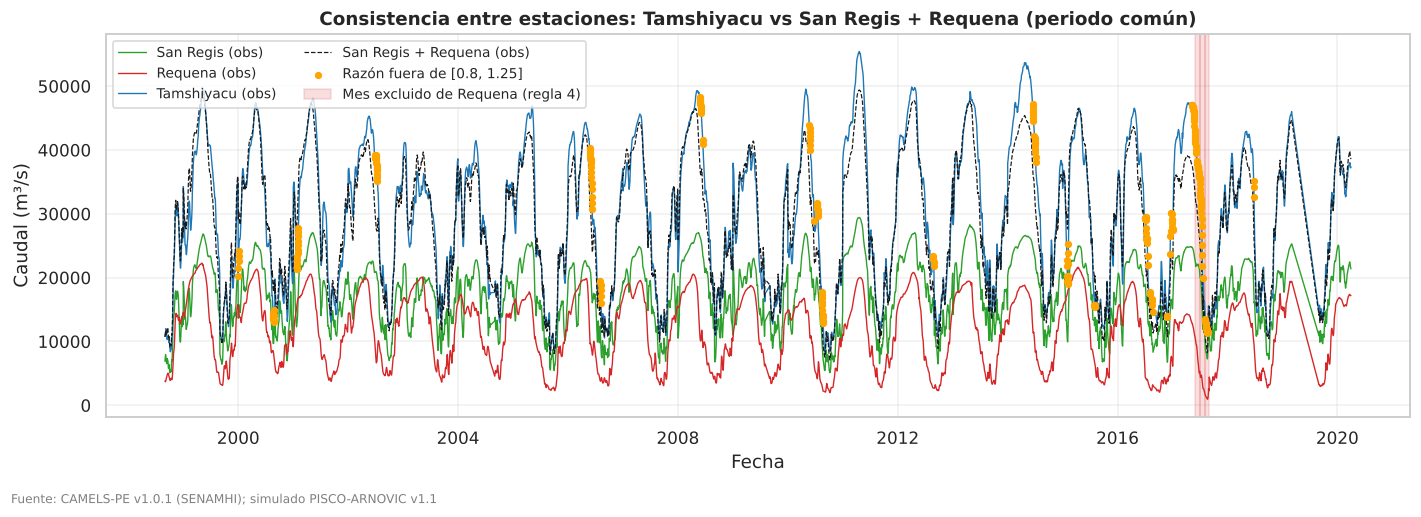

In [20]:
balance['fuera_rango'] = ~balance['razon'].between(0.8, 1.25)
print(f"Días fuera de [0.8, 1.25]: {balance['fuera_rango'].sum()} de {len(balance)} ({100 * balance['fuera_rango'].mean():.2f} %)")
fr = balance[balance['fuera_rango']]
print('Por año-mes:', fr.groupby([fr.index.year, fr.index.month]).size().to_dict())
if len(fr):
    print(fr[[*AGUAS_ARRIBA, SALIDA, 'razon']].round(3).to_string())

# Atribución: meses con > 15 días fuera de rango y una sola estación con razón obs/sim mensual anómala
mes_bal = balance.index.to_period('M')
dias_fuera = balance['fuera_rango'].groupby(mes_bal).sum()
meses_sostenidos = dias_fuera[dias_fuera > 15].index
z_mensual = {}
for n in ESTACIONES.values():
    q_o = series[n]['qobs'].mask(banderas[n].reindex(series[n].index).fillna(False))
    per = series[n].index.to_period('M')
    razon_m = q_o.groupby(per).mean() / series[n]['qsim'].where(q_o.notna()).groupby(per).mean()
    z_mensual[n] = z_robusto(np.log(razon_m.dropna()))
implicito = {SALIDA: balance[AGUAS_ARRIBA].sum(axis=1)}
for u in AGUAS_ARRIBA:
    implicito[u] = balance[SALIDA] - balance[[o for o in AGUAS_ARRIBA if o != u]].sum(axis=1)
filas, meses_excluidos = [], {n: [] for n in ESTACIONES.values()}
for m in meses_sostenidos:
    z = {n: z_mensual[n].get(m, np.nan) for n in ESTACIONES.values()}
    anomalas = [n for n, v in z.items() if abs(v) > 3.5]
    responsable = anomalas[0] if len(anomalas) == 1 else '—'
    if responsable != '—':
        meses_excluidos[responsable].append(m)
    sel = mes_bal == m
    filas.append({'mes': str(m), 'días fuera de rango': int(dias_fuera[m]), 'razón mediana Q_T/(Q_SR+Q_RQ)': balance.loc[sel, 'razon'].median(),
                  **{f'z obs/sim {n}': z[n] for n in ESTACIONES.values()},
                  **{f'{n}: obs / implícito por balance': balance.loc[sel, n].mean() / implicito[n][sel].mean() for n in ESTACIONES.values()},
                  'estación responsable': responsable})
tabla_atribucion = pd.DataFrame(filas).set_index('mes') if filas else pd.DataFrame()
tabla_atribucion.to_csv(RUTA_TAB / 'tabla_atribucion_balance.csv')
print(f'\nMeses con > 15 días fuera de rango: {len(meses_sostenidos)}')
display(tabla_atribucion.round(2))
print('Meses excluidos por inconsistencia de balance atribuible:', {n: [str(m) for m in v] for n, v in meses_excluidos.items() if v} or 'ninguno')

fig, ax = plt.subplots(figsize=(13, 4.5))
for n in ESTACIONES.values():
    ax.plot(balance.index, balance[n], color=COLORES[n], lw=0.9, label=f'{n} (obs)')
ax.plot(balance.index, balance['arriba'], color='k', lw=0.8, ls='--', label='San Regis + Requena (obs)')
ax.scatter(fr.index, fr[SALIDA], color='orange', s=14, zorder=5, label='Razón fuera de [0.8, 1.25]')
for n, meses in meses_excluidos.items():
    for i, m in enumerate(meses):
        ax.axvspan(m.start_time, m.end_time, color=COLORES[n], alpha=0.15, label=f'Mes excluido de {n} (regla 4)' if i == 0 else None)
ax.set_ylabel('Caudal (m³/s)'); ax.set_xlabel('Fecha')
ax.set_title(f'Consistencia entre estaciones: {SALIDA} vs San Regis + Requena (periodo común)', fontweight='bold')
ax.legend(loc='upper left', fontsize=9, ncol=2); ax.grid(True, alpha=0.3)
nota_fuente(fig)
plt.tight_layout()
fig.savefig(RUTA_FIG / 'fig03_consistencia_vecinas.png', dpi=200, bbox_inches='tight')
plt.show()

**Interpretación:**
- **Días fuera de rango:** 263 de 7 560 días (**3.48 %**) quedan fuera de [0.8, 1.25].
  - La mayoría (unos cuatro de cada cinco) están en el descenso de aguas (mayo–agosto), con razones de 1.25–1.38.
  - Algunos están al inicio de las crecidas: enero de 2000 y 2001, y agosto de 2000, con razones de 0.69–0.80.
- **Atribución:** solo cuatro meses tienen más de 15 días fuera de rango, de **2017-05 a 2017-08**. En ellos, la razón obs/sim mensual de **Requena** es anómala (z robusto de −2.10, −3.63, −5.09 y −5.64), mientras que la de San Regis y Tamshiyacu es normal (|z| ≤ 1.51).
  - Requena observado es solo el 40–57 % del caudal implícito por balance (Tamshiyacu − San Regis).
  - Por la regla 4 se excluyen de Requena **2017-06, 2017-07 y 2017-08** (|z| > 3.5).
  - 2017-05 queda dentro (z = −2.10). En la figura 8.2 se ve que el estiaje de 2017 de Requena ya es bajo desde antes. La exclusión es conservadora.
- **El resto de días fuera de rango no se atribuye a ninguna estación.** Son episodios cortos (≤ 14 días por mes) sin una estación anómala identificable. La mayoría ocurre en el descenso de aguas, cuando Tamshiyacu baja más lento que la suma de sus afluentes (2.8).

### 4.5 Serie depurada final
Los errores de 4.3 y los meses excluidos en 4.4 pasan a NaN y se crea el conjunto **pareado** (obs y sim válidos el mismo día) de cada estación, desde el inicio de fechas confiables (2.7). Si alguna estación fue recortada, se guarda también su pareado con el **registro completo sin corregir**, para la sensibilidad de 5.2.

In [21]:
pareados = {}
for nombre, df in series.items():
    df['qobs_dep'] = df['qobs'].mask(banderas[nombre].reindex(df.index).fillna(False))
    df.loc[df.index < inicio_confiable[nombre], 'qobs_dep'] = np.nan
    excl_bal = df.index.to_period('M').isin(meses_excluidos[nombre]) & df['qobs_dep'].notna()
    df.loc[excl_bal, 'qobs_dep'] = np.nan
    p = (df[['qobs_dep', 'qsim', 'prec']].dropna(subset=['qobs_dep', 'qsim'])
         .rename(columns={'qobs_dep': 'obs', 'qsim': 'sim'}))
    pareados[nombre] = p
    print(f"{nombre:10s}: {len(p):5d} días pareados ({p.index.min().date()} a {p.index.max().date()}); "
          f"eliminados por error: {int(banderas[nombre].sum())}; excluidos por balance: {int(excl_bal.sum())}")

pareados_completos = {n: (series[n][['qobs', 'qsim', 'prec']].dropna(subset=['qobs', 'qsim'])
                          .rename(columns={'qobs': 'obs', 'qsim': 'sim'})) for n in recortadas}
print('Estaciones recortadas por error de fechas:', recortadas if recortadas else 'ninguna')

San Regis :  9528 días pareados (1998-09-01 a 2025-12-31); eliminados por error: 0; excluidos por balance: 0
Requena   :  8360 días pareados (1996-07-01 a 2020-03-31); eliminados por error: 11; excluidos por balance: 81
Tamshiyacu: 15028 días pareados (1984-09-01 a 2025-12-31); eliminados por error: 0; excluidos por balance: 0
Estaciones recortadas por error de fechas: ninguna


**Interpretación:** los conjuntos pareados son:
- **Tamshiyacu:** 15 028 días (1984-09-01 a 2025-12-31).
- **San Regis:** 9 528 días (1998-09-01 a 2025-12-31).
- **Requena:** 8 360 días (1996-07-01 a 2020-03-31), tras eliminar 11 días por error (4.3) y excluir 81 días por inconsistencia de balance (4.4).

Ninguna estación fue recortada por error de fechas.

---
## 5. Observado vs. simulado

### 5.1 Métricas globales diarias y mensuales
Sobre fechas pareadas: NSE, KGE (r, α, β), PBIAS, RMSE, NSE-log, BE frente a la climatología mensual del observado, FHV y FMS; NSE/PBIAS mensuales con meses válidos según la regla OMM; IC 95 % del KGE y NSE diarios por bootstrap de bloques mensuales.
**Por qué cada métrica:** NSE es la métrica clásica y base de Moriasi et al. (2007); KGE descompone el error en correlación (r), variabilidad (α) y sesgo (β) (Gupta et al., 2009), y su referencia "sin habilidad" es −0.41, no 0 (Knoben et al., 2019); NSE-log pondera caudales bajos; BE responde si el modelo aporta más que el ciclo estacional (Schaefli y Gupta, 2007), lo que en ríos con un ciclo anual tan marcado es la prueba más exigente; FHV/FMS describen sesgos de la curva de duración (Yilmaz et al., 2008).

In [22]:
def climatologia_mensual(p):
    """Benchmark: media del observado de cada mes calendario, asignada a cada día."""
    return p.index.month.map(p['obs'].groupby(p.index.month).mean())

def serie_mensual_valida(s_diaria):
    """Media mensual solo para meses que cumplen la regla OMM (≤ 10 faltantes y < 5 consecutivos)."""
    meses = []
    for (anio, mes), g in s_diaria.groupby([s_diaria.index.year, s_diaria.index.month]):
        dias_mes = pd.Timestamp(anio, mes, 1).days_in_month
        g = g.reindex(pd.date_range(pd.Timestamp(anio, mes, 1), periods=dias_mes, freq='D'))
        nan = g.isna().astype(int)
        consec = nan.groupby((nan.diff() != 0).cumsum()).transform('sum').where(nan == 1, 0).max()
        if nan.sum() <= 10 and consec < 5:
            meses.append((pd.Timestamp(anio, mes, 1), g.mean()))
    return pd.Series(dict(meses), dtype=float)

def metricas(p):
    """Métricas diarias para un DataFrame pareado con columnas obs y sim."""
    k, r, a, b = kge(p['obs'], p['sim'])
    return {'n días': len(p), 'NSE': nse(p['obs'], p['sim']), 'KGE': k, 'r': r, 'α': a, 'β': b,
            'PBIAS (%)': pbias(p['obs'], p['sim']), 'RMSE (m³/s)': rmse(p['obs'], p['sim']),
            'NSE-log': nse_log(p['obs'], p['sim']),
            'BE (vs clim. mensual)': eficiencia_benchmark(p['obs'], p['sim'], climatologia_mensual(p)),
            'FHV (%)': fhv(p['obs'], p['sim']), 'FMS (%)': fms(p['obs'], p['sim'])}

filas, mensuales = [], {}
for nombre, p in pareados.items():
    fila = {'estación': nombre, **metricas(p)}
    obs_m = serie_mensual_valida(series[nombre]['qobs_dep'].loc[inicio_confiable[nombre]:])
    pm = pd.DataFrame({'obs': obs_m, 'sim': series[nombre]['qsim'].resample('MS').mean()}).dropna()
    mensuales[nombre] = pm
    fila.update({'n meses válidos': len(pm), 'NSE mensual': nse(pm['obs'], pm['sim']), 'PBIAS mensual (%)': pbias(pm['obs'], pm['sim'])})
    boot_kge = bootstrap_bloques_mensuales(p, lambda d: kge(d['obs'], d['sim'])[0])
    boot_nse = bootstrap_bloques_mensuales(p, lambda d: nse(d['obs'], d['sim']))
    fila['KGE IC95'] = f"[{np.percentile(boot_kge, 2.5):.2f}, {np.percentile(boot_kge, 97.5):.2f}]"
    fila['NSE IC95'] = f"[{np.percentile(boot_nse, 2.5):.2f}, {np.percentile(boot_nse, 97.5):.2f}]"
    filas.append(fila)
tabla_metricas = pd.DataFrame(filas).set_index('estación')
tabla_metricas.to_csv(RUTA_TAB / 'tabla_metricas_obs_sim.csv')
tabla_metricas.T.round(3)

estación,San Regis,Requena,Tamshiyacu
n días,9528,8360,15028
NSE,0.575856,0.833267,0.597514
KGE,0.789601,0.916804,0.799733
r,0.789777,0.917393,0.799802
α,1.008619,1.007912,1.00513
β,1.000158,0.99407,0.998845
PBIAS (%),0.015777,-0.592956,-0.115543
RMSE (m³/s),3735.887393,2300.663327,7269.11919
NSE-log,0.551321,0.79119,0.575383
BE (vs clim. mensual),-0.406659,-0.16214,-0.649857


**Interpretación:**

| Estación | NSE | KGE (IC 95 %) | r | BE | NSE mensual |
|---|---|---|---|---|---|
| San Regis | 0.58 | 0.79 [0.75, 0.82] | 0.79 | **−0.41** | 0.66 |
| Requena | 0.83 | 0.92 [0.89, 0.93] | 0.92 | **−0.16** | 0.86 |
| Tamshiyacu | 0.60 | 0.80 [0.77, 0.83] | 0.80 | **−0.65** | 0.64 |

- **Sesgos nulos por construcción:** α = 1.005–1.009, β = 0.994–1.000, PBIAS de −0.59 a +0.02 % y FHV < 1 %. Es el efecto del mapeo de cuantiles (2.6), no una virtud del modelo.
- **Todo el error está en la correlación:** el KGE se reduce a r.
- **BE negativo en las tres estaciones:** a escala diaria, el simulado es **peor que repetir la media mensual del observado**. El ciclo anual de estos ríos es tan regular que la climatología ya explica la mayor parte de la varianza, y el simulado agrega más error del que quita.
- **Requena** es la estación mejor simulada en todas las métricas.

### 5.2 Pruebas de sensibilidad
Las métricas se recalculan (a) de cada estación dentro (hasta 2020) y fuera (2021–2025) de la ventana de calibración de PISCO-ARNOVIC (1981–2020); (b) de las tres estaciones en el **mismo periodo común** (comparación justa entre estaciones); (c) sin el mes de mayor error cuadrático; (d) con el simulado **adelantado su desfase de referencia** (2.7); (e) si 2.7 recortó alguna estación, con su registro completo sin corregir; (f) si 4.4 excluyó meses, sin esa exclusión; (g) si 2.7 encontró escalones de nivel, solo con los años sin escalones.
**Por qué:** (a) si el desempeño cae fuera de la ventana de calibración, las métricas hasta 2020 estarían infladas; (b) los periodos de registro difieren (Requena termina en 2020-03); (c) indica si un solo evento domina las métricas; (d) separa el error de **tiempo** (retardo del tránsito en el modelo) del error de **magnitud**: si el KGE sube mucho al corregir el desfase, el problema del simulado es sobre todo de tiempo.

In [23]:
def sin_mes_mayor_error(p):
    """Quita el mes calendario con mayor suma de errores cuadráticos (sim − obs)²."""
    mes = ((p['sim'] - p['obs']) ** 2).groupby(p.index.to_period('M')).sum().idxmax()
    return p[p.index.to_period('M') != mes], str(mes)

ini_comun = max(p.index.min() for p in pareados.values())
fin_comun = min(p.index.max() for p in pareados.values())
casos = {}
for n, p in pareados.items():
    casos[f'{n} – completo ({p.index.min():%Y}–{p.index.max():%Y})'] = p
    if p.index.max() >= pd.Timestamp('2021-01-01'):
        casos[f'{n} – hasta 2020 (ventana calibración)'] = p.loc[:'2020-12-31']
        casos[f'{n} – 2021–2025 (fuera de ventana)'] = p.loc['2021-01-01':]
    pc = p.loc[ini_comun:fin_comun]
    casos[f'{n} – periodo común {ini_comun:%Y-%m} a {fin_comun:%Y-%m}'] = pc
    p_sm, mes_sm = sin_mes_mayor_error(p)
    casos[f'{n} – completo sin {mes_sm} (mes de mayor error)'] = p_sm
    sim_ad = series[n]['qsim'].shift(ref_lag[n]).reindex(p.index)
    casos[f'{n} – simulado adelantado {-ref_lag[n]} d (desfase de referencia)'] = p.assign(sim=sim_ad).dropna(subset=['sim'])
    if len(escalones[n]):
        casos[f'{n} – solo años sin escalones ({len(anios_sin_escalon[n])} años)'] = p[p.index.year.isin(anios_sin_escalon[n])]
    if n in recortadas:
        casos[f'{n} – registro completo sin corregir'] = pareados_completos[n]
    if meses_excluidos[n]:
        q_sin_bal = series[n]['qobs'].mask(banderas[n].reindex(series[n].index).fillna(False)).loc[inicio_confiable[n]:]
        casos[f'{n} – sin excluir los meses de 4.4'] = (pd.DataFrame({'obs': q_sin_bal, 'sim': series[n]['qsim']}).dropna())
tabla_sens = pd.DataFrame({k: metricas(v) for k, v in casos.items()}).T
tabla_sens.to_csv(RUTA_TAB / 'tabla_sensibilidad.csv')
tabla_sens[['n días', 'NSE', 'KGE', 'r', 'α', 'β', 'PBIAS (%)', 'NSE-log', 'BE (vs clim. mensual)']].round(3)

,n días,NSE,KGE,r,α,β,PBIAS (%),NSE-log,BE (vs clim. mensual)
San Regis – completo (1998–2025),9528.0,0.576,0.790,0.790,1.009,1.000,0.016,0.551,-0.407
San Regis – hasta 2020 (ventana calibración),7760.0,0.501,0.758,0.762,1.044,0.994,-0.597,0.481,-0.604
San Regis – 2021–2025 (fuera de ventana),1768.0,0.788,0.828,0.891,0.869,1.025,2.484,0.797,-0.002
San Regis – periodo común 1998-09 a 2020-03,7638.0,0.491,0.754,0.758,1.046,0.994,-0.644,0.471,-0.619
San Regis – completo sin 2017-01 (mes de mayor error),9497.0,0.585,0.794,0.794,1.008,1.002,0.195,0.560,-0.380
San Regis – simulado adelantado 7 d (desfase de referencia),9521.0,0.592,0.798,0.798,1.007,1.001,0.143,0.582,-0.353
San Regis – solo años sin escalones (12 años),4002.0,0.694,0.846,0.846,0.996,0.998,-0.179,0.664,-0.143
Requena – completo (1996–2020),8360.0,0.833,0.917,0.917,1.008,0.994,-0.593,0.791,-0.162
Requena – periodo común 1998-09 a 2020-03,7570.0,0.855,0.927,0.927,0.993,1.006,0.579,0.834,0.033
Requena – completo sin 1999-11 (mes de mayor error),8330.0,0.839,0.919,0.920,1.008,0.992,-0.808,0.796,-0.126


**Interpretación:**
- **(g) Escalones de nivel: es la sensibilidad que más cambia las métricas.**
  - Con solo los años sin escalones, el NSE sube de 0.576 a **0.694** en San Regis y de 0.598 a **0.715** en Tamshiyacu.
  - El KGE sube de 0.790 a 0.846 y de 0.800 a 0.849, y el BE mejora de −0.407 a −0.143 y de −0.650 a −0.420.
  - Parte del mal desempeño diario se debe a los escalones del observado, no al modelo. Aun así, **el BE sigue siendo negativo**: la conclusión de H1 no cambia.
  - En Tamshiyacu, esos años tienen PBIAS de +8.7 %, porque concentran el periodo reciente.
- **(a) Ventana de calibración:**
  - San Regis mejora fuera de ella (NSE 0.501 hasta 2020 frente a 0.788 en 2021–2025), algo coherente con que en 2021–2025 no tiene escalones (salvo 2024-11-01).
  - En Tamshiyacu, 2021–2025 tiene NSE 0.645 pero **PBIAS +19.3 %**: el simulado sobreestima en el periodo reciente (ver 5.3).
- **(b) Periodo común (1998-09 a 2020-03):** las métricas cambian poco en Requena (KGE 0.927). En Tamshiyacu mejoran (NSE 0.712), porque ese periodo deja fuera 1984–1998, con varios de los escalones más grandes (por ejemplo, +162 % en 1990).
- **(c) Sin el mes de mayor error:** las métricas cambian ≤ 0.01. Ningún evento aislado las domina.
- **(d) Simulado adelantado su desfase de referencia:** casi no cambia las métricas de San Regis y Tamshiyacu (KGE +0.008 y −0.003) y empeora las de Requena (0.917 → 0.894). El retardo de 2.7 describe la alineación de las **variaciones**, pero el error del simulado es sobre todo de forma, no de tiempo.
- **(f) Exclusión de 4.4 en Requena:** quitar los tres meses de 2017 sube el NSE de 0.826 a 0.833 y el NSE-log de 0.777 a 0.791. La exclusión importa sobre todo en caudales bajos.

### 5.3 Homogeneidad de Tamshiyacu (registro más largo)
Por año (≥ 330 días observados): razón media(obs)/media(sim) e índice RB del observado; tendencia monótona con la correlación de Spearman frente al año (Lab3_2; equivalente en espíritu a Mann-Kendall) y comparación de los años dentro de la ventana de calibración (hasta 2020) con 2021–2025 con Mann-Whitney.
**Por qué:** un cambio de curva de descarga, de sección o de método de lectura produciría un quiebre en el nivel del observado respecto del simulado, o en su variabilidad diaria. Se usan años para reducir la autocorrelación; Mann-Whitney porque n es pequeño y no se supone normalidad. Como Requena termina en 2020-03, después de esa fecha el balance solo puede aproximarse con Requena **simulado**: Q_T,obs / (Q_SR,obs + Q_RQ,sim); se reporta por año como indicio, no como prueba.

In [24]:
ta = series[SALIDA]
cuenta = ta['qobs_dep'].groupby(ta.index.year).count()
anios_ok = cuenta[cuenta >= 330].index
razon_anual = (ta['qobs_dep'].groupby(ta.index.year).mean() /
               ta['qsim'].where(ta['qobs_dep'].notna()).groupby(ta.index.year).mean()).loc[anios_ok]
rb_anual = pd.Series({a: richards_baker(ta['qobs_dep'].loc[str(a)]) for a in anios_ok})
print(f'{SALIDA}: razón anual media(obs)/media(sim) y RB anual del observado (años con ≥ 330 días):')
print(pd.DataFrame({'obs/sim': razon_anual, 'RB obs': rb_anual}).round(4).T.to_string())
for etiqueta, s in (('obs/sim', razon_anual), ('RB obs', rb_anual)):
    rho, p = stats.spearmanr(s.index, s.values)
    a, b = s.loc[:2020], s.loc[2021:]
    mw = stats.mannwhitneyu(a, b, alternative='two-sided') if len(b) >= 2 else None
    print(f"{etiqueta:8s}: Spearman(año) ρ = {rho:.3f}, p = {p:.4f} | hasta 2020 mediana = {a.median():.4f} (n = {len(a)}), "
          f"2021–2025 mediana = {b.median():.4f} (n = {len(b)})" + (f", Mann-Whitney p = {mw.pvalue:.4f}" if mw else ''))

aprox = (ta['qobs_dep'] / (series['San Regis']['qobs_dep'] + series['Requena']['qsim'])).dropna()
print(f"\nBalance aproximado Q_T,obs / (Q_SR,obs + Q_RQ,sim), mediana por año:")
print(aprox.groupby(aprox.index.year).median().round(3).to_dict())

Tamshiyacu: razón anual media(obs)/media(sim) y RB anual del observado (años con ≥ 330 días):
           1985    1986    1987    1988    1989    1990    1991    1992    1993    1994    1995    1996    1997    1998    1999    2000    2001    2002    2003    2004    2005    2006    2007    2008    2009    2010    2011    2012    2013    2014    2015    2016    2017    2018    2019    2020    2021    2022    2024    2025
obs/sim  1.1047  1.1762  1.0077  1.3769  0.9719  1.4847  1.0785  1.6362  1.2105  0.8885  1.1290  1.2000  1.1423  0.7977  0.7971  0.8197  0.9180  0.9731  1.0073  1.1339  1.1525  1.0798  1.0609  0.9890  0.7832  0.8959  1.0920  0.9153  0.9440  1.1179  0.8362  1.1147  0.9839  1.0243  1.0796  0.9024  0.8978  0.8734  0.7681  0.8900
RB obs   0.0139  0.0096  0.0125  0.0098  0.0144  0.0115  0.0171  0.0089  0.0087  0.0143  0.0125  0.0142  0.0123  0.0113  0.0125  0.0130  0.0121  0.0092  0.0135  0.0140  0.0134  0.0119  0.0116  0.0111  0.0149  0.0129  0.0102  0.0101  0.0119  0.0085  0

**Interpretación:**
- **Variabilidad diaria estable:** el RB anual del observado de Tamshiyacu no tiene tendencia (ρ = −0.029, p = 0.861) ni cambio después de 2020 (Mann-Whitney p = 0.845).
- **El nivel relativo al simulado sí cambia:**
  - la razón anual obs/sim tiene tendencia negativa (ρ = −0.467, p = 0.0024);
  - es menor en 2021–2025 (mediana 0.882, n = 4) que hasta 2020 (1.043, n = 36; Mann-Whitney p = 0.011).
- **Lectura de la razón anual:** oscila entre 0.77 y 1.64. Los valores más altos (1.38 en 1988, 1.48 en 1990 y 1.64 en 1992) son años con escalones de nivel el 1 de enero y el 1 de setiembre (2.7). Parte de la tendencia refleja esos bloques y no un cambio gradual.
- **Balance aproximado después de 2020:** Q_T,obs / (Q_SR,obs + Q_RQ,sim) baja a **0.844 (2023) y 0.830 (2024)**, frente a 0.94–1.12 en 1998–2022.
  - 2023 y 2024 fueron estiajes extremos. Puede que el simulado de Requena sobreestime en sequía o que el observado de Tamshiyacu esté bajo.
  - Sin Requena observado no se puede distinguir entre ambas causas. Queda como limitación.

### 5.4 Desempeño por régimen de caudal y por época
(a) Regímenes por percentiles del observado (< P30, P30–P90, > P90) con PBIAS, RMSE y error relativo mediano; (b) época húmeda = meses con caudal medio observado mayor que la media anual; KGE/NSE/PBIAS por época.
**Por qué:** NSE dentro de un régimen es engañoso (la varianza intrarrégimen es pequeña), por eso en regímenes se usan sesgos y errores. Los cortes P30/P90 siguen la segmentación de la curva de duración de Yilmaz et al. (2008).

In [25]:
filas_reg, filas_epo, meses_humedos = [], [], {}
for nombre, p in pareados.items():
    p30, p90 = p['obs'].quantile([0.30, 0.90])
    regimen = pd.cut(p['obs'], [-np.inf, p30, p90, np.inf], labels=['bajos (<P30)', 'medios (P30–P90)', 'altos (>P90)'])
    for reg, g in p.groupby(regimen, observed=True):
        gp = g[g['obs'] > 0]
        filas_reg.append({'estación': nombre, 'régimen': reg, 'n': len(g), 'umbral (m³/s)': f"{p30:.0f} / {p90:.0f}",
                          'PBIAS (%)': pbias(g['obs'], g['sim']), 'RMSE (m³/s)': rmse(g['obs'], g['sim']),
                          'error relativo mediano (%)': 100 * ((gp['sim'] - gp['obs']) / gp['obs']).median()})
    media_mes = series[nombre]['qobs_dep'].groupby(series[nombre].index.month).mean()
    humedos = sorted(media_mes[media_mes > media_mes.mean()].index.tolist())
    meses_humedos[nombre] = humedos
    epoca = np.where(p.index.month.isin(humedos), 'húmeda', 'seca')
    for ep, g in p.groupby(epoca):
        k, r, a, b = kge(g['obs'], g['sim'])
        filas_epo.append({'estación': nombre, 'época': ep, 'meses': humedos if ep == 'húmeda' else 'resto', 'n': len(g),
                          'KGE': k, 'r': r, 'α': a, 'β': b, 'NSE': nse(g['obs'], g['sim']), 'PBIAS (%)': pbias(g['obs'], g['sim'])})
tabla_regimen = pd.DataFrame(filas_reg).set_index(['estación', 'régimen']).round(2)
tabla_epoca = pd.DataFrame(filas_epo).set_index(['estación', 'época']).round(3)
tabla_regimen.to_csv(RUTA_TAB / 'tabla_desempeno_regimen.csv')
tabla_epoca.to_csv(RUTA_TAB / 'tabla_desempeno_epoca.csv')
print('Meses de época húmeda (media mensual obs > media anual):', meses_humedos)
display(tabla_regimen)
display(tabla_epoca)

Meses de época húmeda (media mensual obs > media anual): {'San Regis': [1, 2, 3, 4, 5, 6], 'Requena': [1, 2, 3, 4, 5, 12], 'Tamshiyacu': [1, 2, 3, 4, 5, 6]}


n  umbral (m³/s)  PBIAS (%)  RMSE (m³/s)  \
estación   régimen                                                         
San Regis  bajos (<P30)      2864  13918 / 24978      12.70      3751.70   
           medios (P30–P90)  5712  13918 / 24978      -1.72      3747.19   
           altos (>P90)       952  13918 / 24978      -7.59      3618.45   
Requena    bajos (<P30)      2509   7209 / 19077       9.19      1879.99   
           medios (P30–P90)  5017   7209 / 19077      -1.15      2550.57   
           altos (>P90)       834   7209 / 19077      -5.13      1814.06   
Tamshiyacu bajos (<P30)      4513  22173 / 45381      13.37      6321.77   
           medios (P30–P90)  9012  22173 / 45381      -1.16      7593.20   
           altos (>P90)      1503  22173 / 45381      -9.26      7913.28   

                             error relativo mediano (%)  
estación   régimen                                       
San Regis  bajos (<P30)                            8.42  
           medios (P30–P90)                       -1.07  
           altos (>P90)                           -7.84  
Requena    bajos (<P30)                           10.49  
           medios (P30–P90)                       -1.48  
           altos (>P90)                           -4.25  
Tamshiyacu bajos (<P30)                           11.26  
           medios (P30–P90)                       -0.82  
           altos (>P90)                           -9.14

meses     n    KGE      r      α      β  \
estación   época                                                           
San Regis  húmeda   [1, 2, 3, 4, 5, 6]  4679  0.528  0.529  1.035  0.991   
           seca                  resto  4849  0.652  0.665  1.092  1.014   
Requena    húmeda  [1, 2, 3, 4, 5, 12]  4202  0.735  0.738  1.039  0.995   
           seca                  resto  4158  0.764  0.765  1.021  0.992   
Tamshiyacu húmeda   [1, 2, 3, 4, 5, 6]  7415  0.475  0.477  1.044  0.992   
           seca                  resto  7613  0.629  0.634  1.058  1.011   

                     NSE  PBIAS (%)  
estación   época                     
San Regis  húmeda  0.022     -0.909  
           seca    0.257      1.442  
Requena    húmeda  0.452     -0.500  
           seca    0.519     -0.812  
Tamshiyacu húmeda -0.096     -0.792  
           seca    0.220      1.074

**Interpretación:**
- **Error que depende del caudal:**
  - el simulado **sobreestima los caudales bajos** (< P30): PBIAS de +12.7 % (San Regis), +9.2 % (Requena) y +13.4 % (Tamshiyacu);
  - **subestima los altos** (> P90): −7.6 %, −5.1 % y −9.3 %;
  - es casi insesgado en los medios (−1.2 a −1.7 %).

  El error suma cero en el total, pero no en cada régimen. Comprime la amplitud diaria del hidrograma alrededor de la media.
- **Épocas:** la húmeda es enero–junio (San Regis, Tamshiyacu) o diciembre–mayo (Requena).
  - El KGE es menor en la húmeda: 0.528 frente a 0.652 (San Regis), 0.735 frente a 0.764 (Requena) y 0.475 frente a 0.629 (Tamshiyacu).
  - El NSE dentro de cada época es bajo, de −0.10 a 0.52, porque la varianza intraépoca es pequeña.

### 5.5 Curvas de duración, régimen mensual y dispersión 1:1
Tres paneles por estación (Lab4_1, Lab4_2): curva de duración (eje log), régimen mensual sobre fechas pareadas y dispersión obs–sim con línea 1:1.

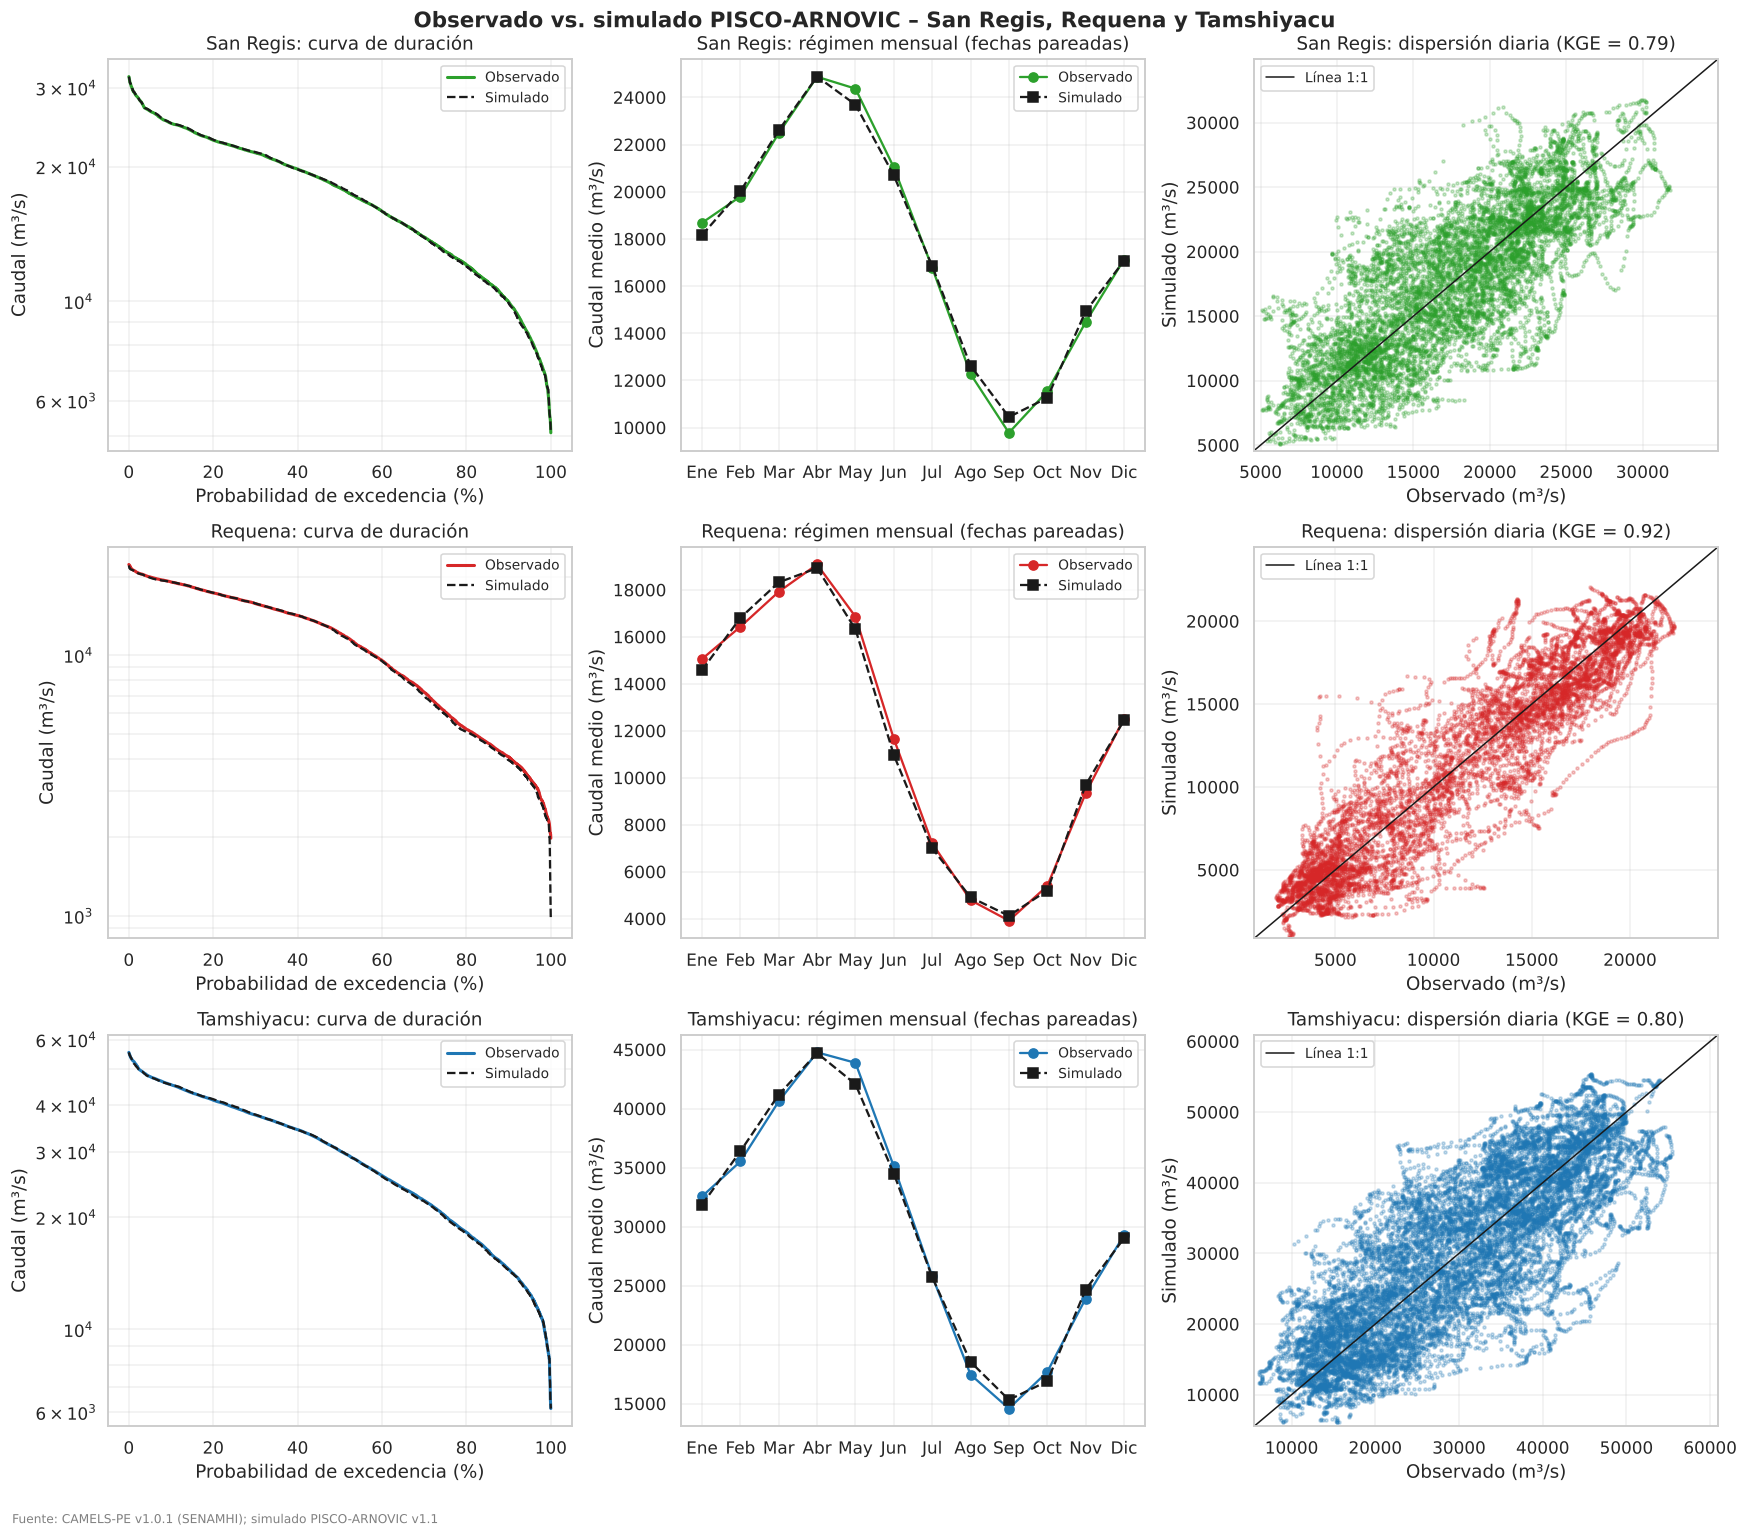

In [26]:
meses_es = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']
n_est = len(pareados)
fig, ejes = plt.subplots(n_est, 3, figsize=(16, 4.6 * n_est))
for i, (nombre, p) in enumerate(pareados.items()):
    c = COLORES[nombre]
    po, qo = curva_duracion(p['obs']); ps, qs = curva_duracion(p['sim'])
    ax = ejes[i, 0]
    ax.plot(100 * po, qo, color=c, lw=2, label='Observado'); ax.plot(100 * ps, qs, color='k', lw=1.5, ls='--', label='Simulado')
    ax.set_yscale('log'); ax.set_xlabel('Probabilidad de excedencia (%)'); ax.set_ylabel('Caudal (m³/s)')
    ax.set_title(f'{nombre}: curva de duración'); ax.legend(fontsize=9); ax.grid(True, which='both', alpha=0.3)
    ax = ejes[i, 1]
    reg = p.groupby(p.index.month)[['obs', 'sim']].mean()
    ax.plot(reg.index, reg['obs'], 'o-', color=c, label='Observado'); ax.plot(reg.index, reg['sim'], 's--', color='k', label='Simulado')
    ax.set_xticks(range(1, 13)); ax.set_xticklabels(meses_es); ax.set_ylabel('Caudal medio (m³/s)')
    ax.set_title(f'{nombre}: régimen mensual (fechas pareadas)'); ax.legend(fontsize=9); ax.grid(True, alpha=0.3)
    ax = ejes[i, 2]
    ax.scatter(p['obs'], p['sim'], s=4, alpha=0.25, color=c)
    lim = [min(p['obs'].min(), p['sim'].min()) * 0.9, max(p['obs'].max(), p['sim'].max()) * 1.1]
    ax.plot(lim, lim, 'k-', lw=1, label='Línea 1:1')
    ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_xlabel('Observado (m³/s)'); ax.set_ylabel('Simulado (m³/s)')
    ax.set_title(f"{nombre}: dispersión diaria (KGE = {tabla_metricas.loc[nombre, 'KGE']:.2f})")
    ax.legend(fontsize=9, loc='upper left'); ax.grid(True, alpha=0.3)
fig.suptitle('Observado vs. simulado PISCO-ARNOVIC – San Regis, Requena y Tamshiyacu', fontsize=14, fontweight='bold')
nota_fuente(fig)
plt.tight_layout()
fig.savefig(RUTA_FIG / 'fig04_fdc_regimen_dispersion.png', dpi=200, bbox_inches='tight')
plt.show()

**Interpretación:**
- **Curvas de duración prácticamente superpuestas** en las tres estaciones. Es lo esperado tras un mapeo de cuantiles.
  - En Requena, la cola baja del simulado llega a ~1 000 m³/s, heredada del mínimo erróneo de 2017 (2.6).
  - El observado depurado no baja de ~2 000 m³/s.
- **Régimen mensual:** también coincide, con máximo en abril y mínimo en setiembre. Las únicas diferencias son de 3–6 % (mayo en San Regis y Tamshiyacu; setiembre en San Regis).
- **Dispersión diaria:** muestra lo que las curvas ocultan. La nube es ancha (±5 000–10 000 m³/s en San Regis y Tamshiyacu) y forma "lazos" típicos de un desfase temporal.

El simulado tiene la distribución correcta, pero no el valor correcto el día correcto.

### 5.6 Hidrogramas superpuestos y desfase temporal
Observado y simulado del **año hidrológico** más reciente con ≥ 95 % de días observados en las tres estaciones (el año hidrológico empieza en el mes de menor caudal medio de Tamshiyacu) y correlación cruzada obs–sim para desfases de −15 a +15 días sobre las series depuradas.

Mes de inicio del año hidrológico (mínimo caudal medio de Tamshiyacu): Sep | año elegido: 2017-09-01 a 2018-08-31


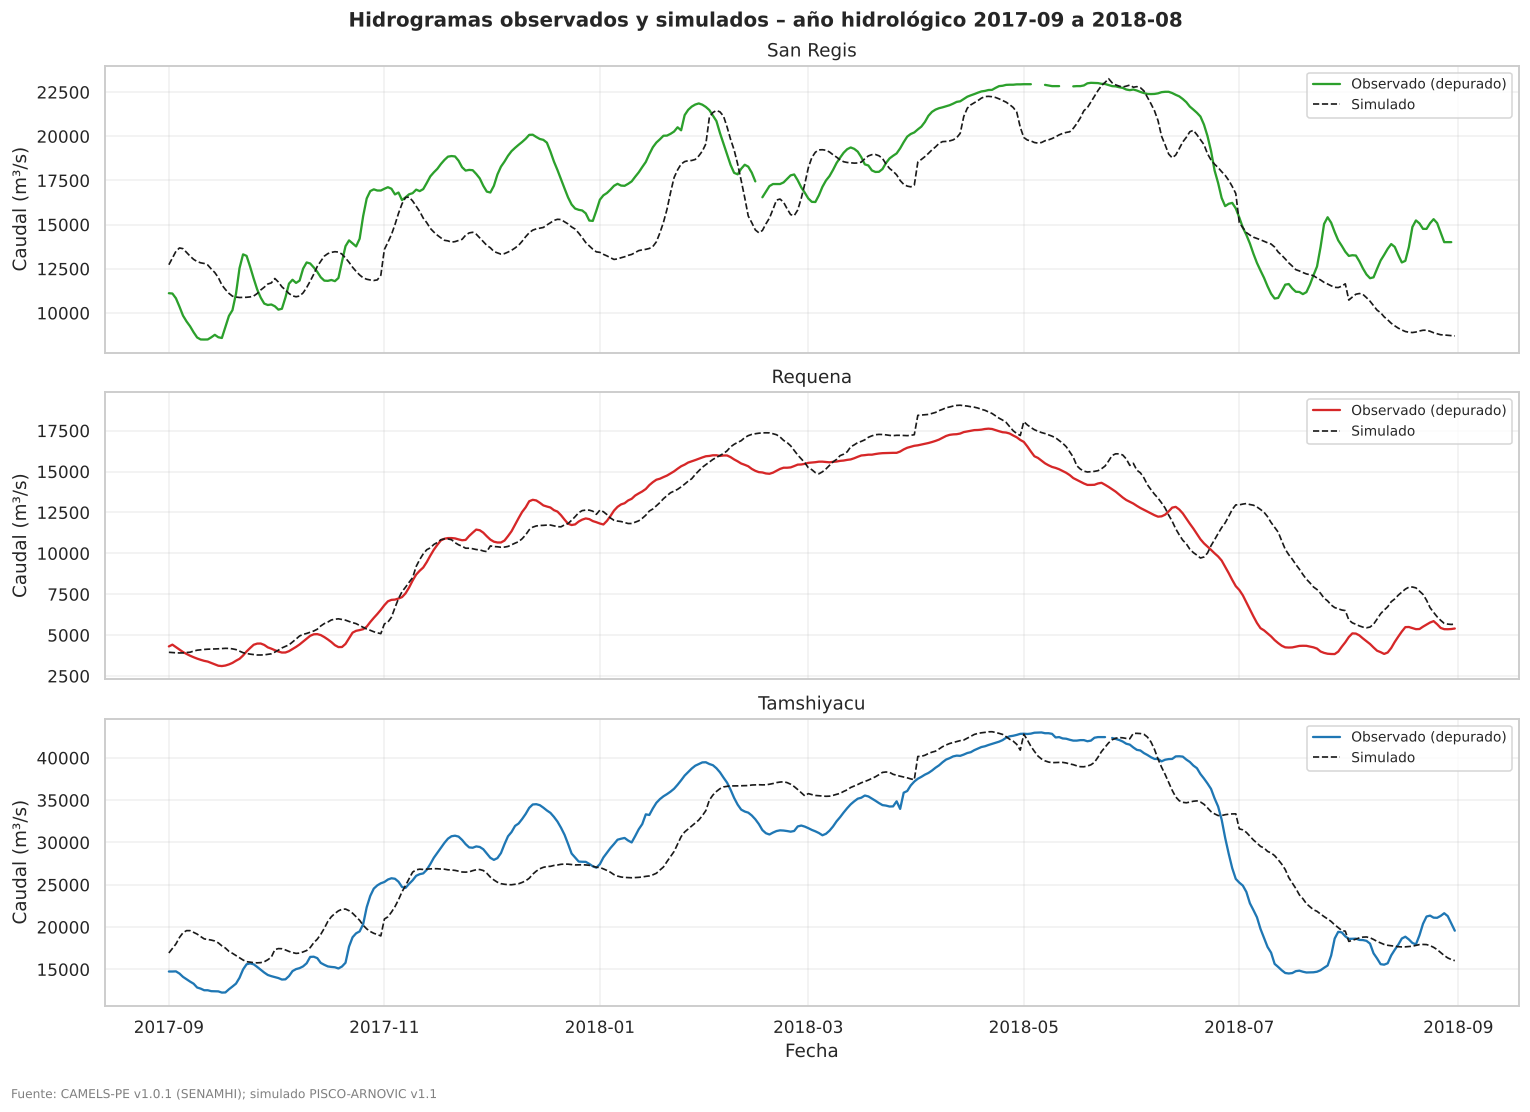

Desfase positivo = el simulado se adelanta (sim en t−lag se alinea con obs en t); negativo = el simulado llega después.


,r (desfase 0),desfase de máx. r (días),r máx.
estación,,,
San Regis,0.7898,-5,0.7988
Requena,0.9174,0,0.9174
Tamshiyacu,0.7998,-3,0.8013


In [27]:
media_mes_sal = series[SALIDA]['qobs_dep'].groupby(series[SALIDA].index.month).mean()
mes_ini = int(media_mes_sal.idxmin())
anio_hidro = None
for a in range(2024, 1980, -1):
    ini, fin = pd.Timestamp(a, mes_ini, 1), pd.Timestamp(a + 1, mes_ini, 1) - pd.Timedelta(days=1)
    if all(series[n]['qobs_dep'].loc[ini:fin].notna().mean() >= 0.95 for n in ESTACIONES.values()):
        anio_hidro = (ini, fin)
        break
print(f"Mes de inicio del año hidrológico (mínimo caudal medio de {SALIDA}): {meses_es[mes_ini - 1]} | "
      f"año elegido: {anio_hidro[0].date()} a {anio_hidro[1].date()}")

fig, ejes = plt.subplots(len(ESTACIONES), 1, figsize=(14, 3.3 * len(ESTACIONES)), sharex=True)
for ax, (nombre, df) in zip(ejes, series.items()):
    tramo = df.loc[anio_hidro[0]:anio_hidro[1]]
    ax.plot(tramo.index, tramo['qobs_dep'], color=COLORES[nombre], lw=1.5, label='Observado (depurado)')
    ax.plot(tramo.index, tramo['qsim'], color='k', lw=1.1, ls='--', label='Simulado')
    ax.set_ylabel('Caudal (m³/s)'); ax.set_title(nombre); ax.legend(loc='upper right', fontsize=9); ax.grid(True, alpha=0.3)
ejes[-1].set_xlabel('Fecha')
fig.suptitle(f'Hidrogramas observados y simulados – año hidrológico {anio_hidro[0]:%Y-%m} a {anio_hidro[1]:%Y-%m}',
             fontsize=13, fontweight='bold')
nota_fuente(fig)
plt.tight_layout()
fig.savefig(RUTA_FIG / 'fig05_hidrogramas.png', dpi=200, bbox_inches='tight')
plt.show()

filas = []
for nombre, df in series.items():
    corr = {lag: df['qobs_dep'].corr(df['qsim'].shift(lag)) for lag in range(-15, 16)}
    mejor = max(corr, key=corr.get)
    filas.append({'estación': nombre, 'r (desfase 0)': corr[0], 'desfase de máx. r (días)': mejor, 'r máx.': corr[mejor]})
print('Desfase positivo = el simulado se adelanta (sim en t−lag se alinea con obs en t); negativo = el simulado llega después.')
pd.DataFrame(filas).set_index('estación').round(4)

**Interpretación:** el año hidrológico más reciente con ≥ 95 % de datos en las tres estaciones es **2017-09 a 2018-08** (empieza en setiembre, el mes de menor caudal medio de Tamshiyacu).
- **Forma general:** el simulado sigue el ciclo anual, pero suaviza o desplaza las ondas intraestacionales. Ejemplos: la subida de noviembre–diciembre de 2017 en San Regis y Tamshiyacu, y el descenso de julio de 2018, que el simulado retrasa ~2–3 semanas.
- **Saltos el día 1 de cada mes:** el simulado tiene escalones visibles el 1 de abril de 2018 en Requena y Tamshiyacu, que el río no tiene (2.6).
- **Correlación cruzada:** el máximo está en −5 días (San Regis), 0 (Requena) y −3 días (Tamshiyacu), con ganancias de r ≤ 0.009. Sobre el caudal (no sobre sus variaciones), el retardo pesa poco: el error dominante es de forma, no de tiempo.

---
## 6. Correlaciones

### 6.1 Variables hidroclimáticas frente al caudal observado
Matriz de Spearman (Lab3_2) entre caudal observado, simulado, lluvia diaria y acumulada (3, 7 y 30 días), ETP, temperatura media, radiación y presión de vapor, en los días con observado depurado; Pearson sobre log(Q + ε) como complemento. Se añade la lluvia de 30 días porque en estos ríos la respuesta es de semanas.
**Advertencia:** con series autocorrelacionadas los p-valores serían engañosos (Ses6a); la correlación se usa como medida de asociación.

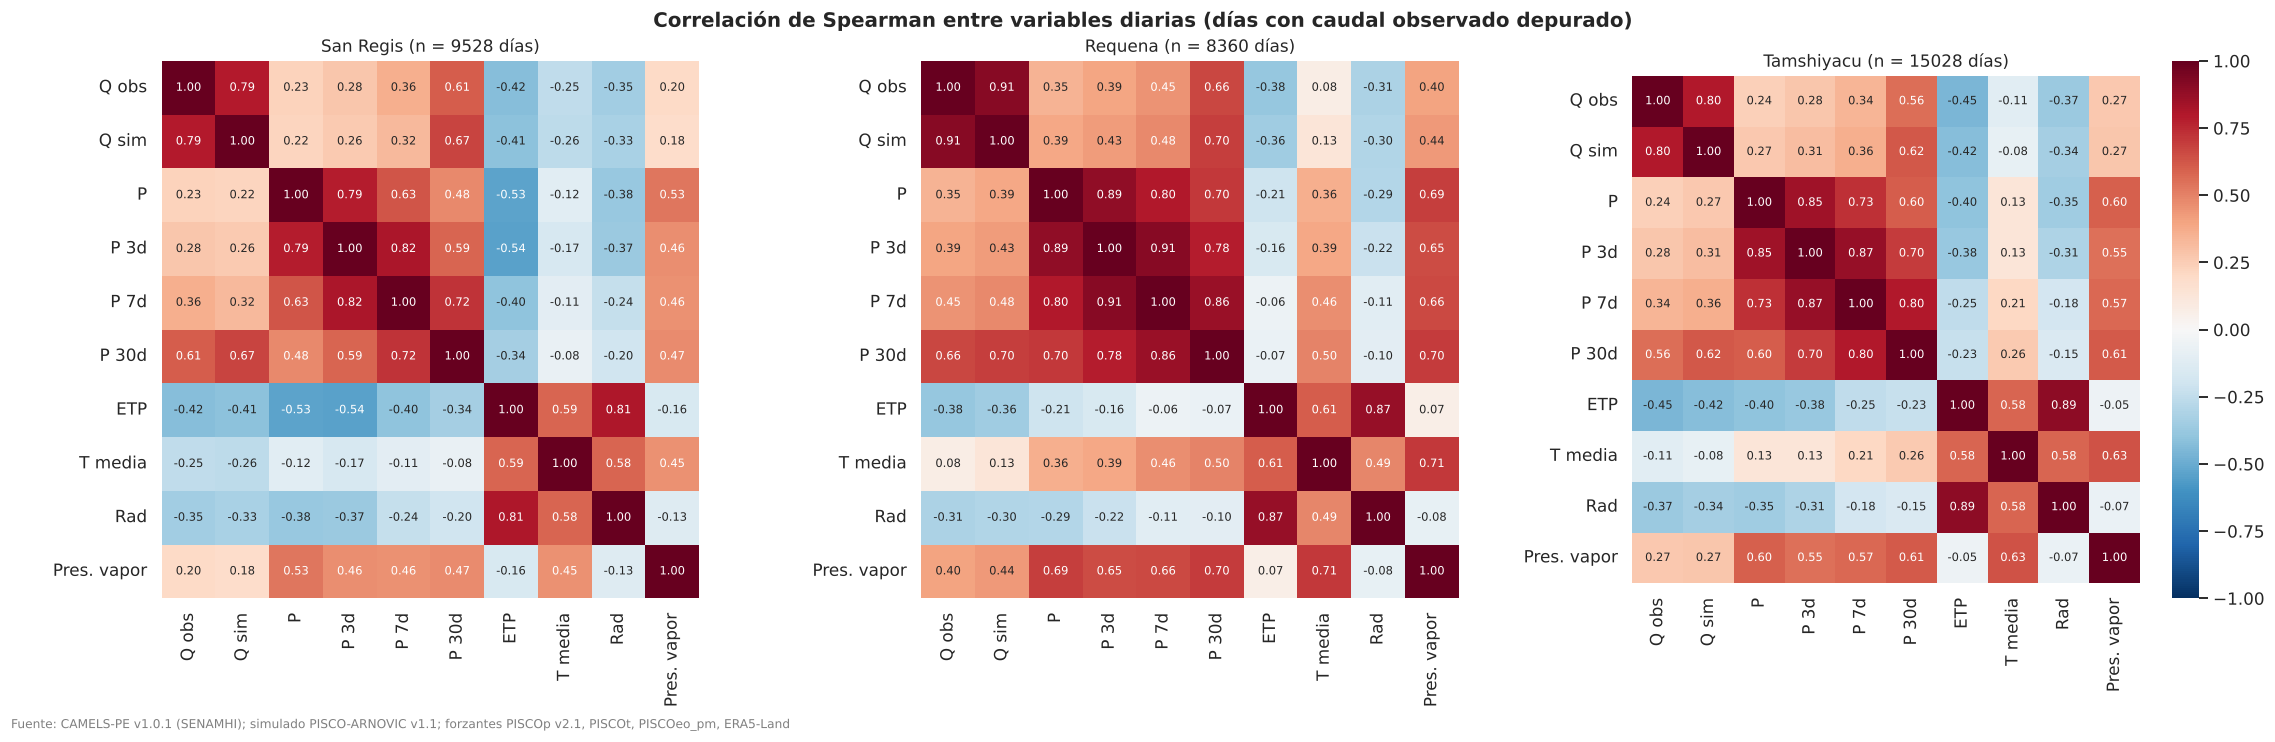

,"Spearman(Qobs, Qsim)","Pearson(log Qobs, log Qsim)","Spearman(Qobs, P 7d)","Spearman(Qobs, P 30d)"
estación,,,,
San Regis,0.793,0.778,0.361,0.609
Requena,0.910,0.899,0.446,0.664
Tamshiyacu,0.802,0.789,0.336,0.555


In [28]:
fig, ejes = plt.subplots(1, len(ESTACIONES), figsize=(7 * len(ESTACIONES), 6.5))
for ax, (nombre, df) in zip(ejes, series.items()):
    d = pd.DataFrame({'Q obs': df['qobs_dep'], 'Q sim': df['qsim'], 'P': df['prec'], 'P 3d': df['prec'].rolling(3).sum(),
                      'P 7d': df['prec'].rolling(7).sum(), 'P 30d': df['prec'].rolling(30).sum(), 'ETP': df['pet'],
                      'T media': df['tmean'], 'Rad': df['srad'], 'Pres. vapor': df['vprp']})
    d = d[d['Q obs'].notna()]
    sns.heatmap(d.corr(method='spearman'), annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, ax=ax,
                cbar=ax is ejes[-1], annot_kws={'size': 7.5}, square=True)
    ax.set_title(f'{nombre} (n = {len(d)} días)', fontsize=11)
fig.suptitle('Correlación de Spearman entre variables diarias (días con caudal observado depurado)', fontsize=13, fontweight='bold')
nota_fuente(fig, FUENTE + '; forzantes PISCOp v2.1, PISCOt, PISCOeo_pm, ERA5-Land')
plt.tight_layout()
fig.savefig(RUTA_FIG / 'fig06_correlaciones.png', dpi=200, bbox_inches='tight')
plt.show()

filas = []
for nombre, df in series.items():
    d = pd.DataFrame({'q': df['qobs_dep'], 's': df['qsim'], 'p7': df['prec'].rolling(7).sum(),
                      'p30': df['prec'].rolling(30).sum()}).dropna()
    eps = d['q'].mean() / 100
    filas.append({'estación': nombre, 'Spearman(Qobs, Qsim)': stats.spearmanr(d['q'], d['s'])[0],
                  'Pearson(log Qobs, log Qsim)': stats.pearsonr(np.log(d['q'] + eps), np.log(d['s'] + eps))[0],
                  'Spearman(Qobs, P 7d)': stats.spearmanr(d['q'], d['p7'])[0],
                  'Spearman(Qobs, P 30d)': stats.spearmanr(d['q'], d['p30'])[0]})
pd.DataFrame(filas).set_index('estación').round(3)

**Interpretación:**
- **Simulado frente a observado:** la correlación de Spearman es 0.79 (San Regis), 0.91 (Requena) y 0.80 (Tamshiyacu).
- **Lluvia:** la asociación con la lluvia acumulada de 30 días (ρ = 0.56–0.66) es mucho mayor que con la de 7 días (0.34–0.45) o la diaria. En estos ríos el caudal integra semanas a meses de lluvia de toda la cuenca.
- **Temperatura y radiación:** sus correlaciones reflejan sobre todo el ciclo estacional compartido.

### 6.2 Tiempo de respuesta lluvia → caudal
Correlación de Spearman entre la lluvia del día *t − k* y el caudal observado del día *t*, *k* = 0–60, sobre **anomalías** (se resta la media de cada mes calendario; Lab5_2), en fechas confiables; lo mismo con el caudal simulado.
**Por qué:** sin quitar el ciclo estacional la correlación estaría dominada por la estacionalidad compartida. Comparar el rezago de máxima correlación del observado con el del simulado es además una **verificación independiente** de 2.7: si el simulado responde a la lluvia más tarde que el río, su retardo es del modelo y no de las fechas del observado.

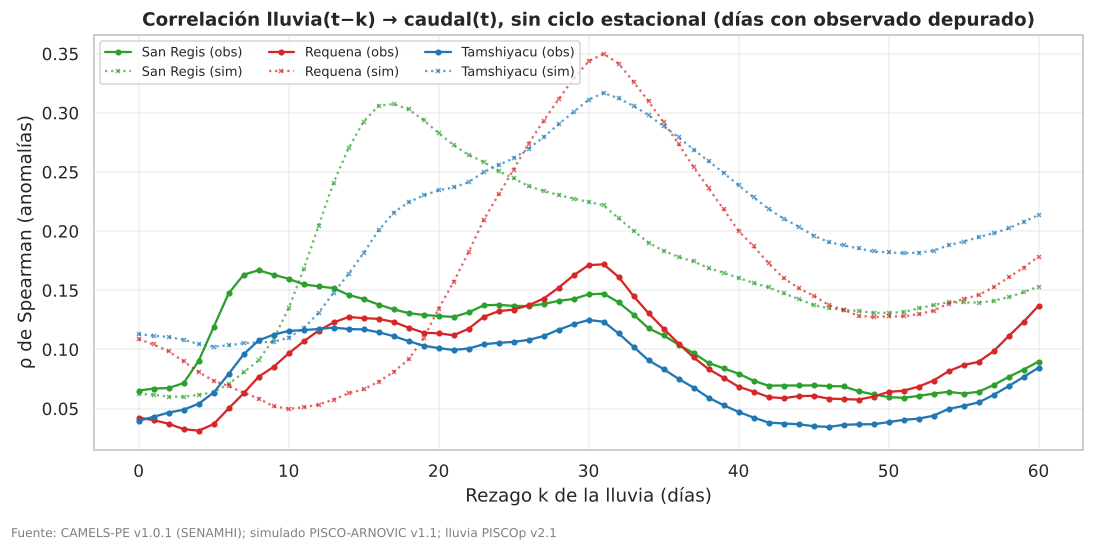

,rezago de máx. ρ (días),ρ máx.
serie,,
San Regis (obs),8,0.167
San Regis (sim),17,0.308
Requena (obs),31,0.172
Requena (sim),31,0.350
Tamshiyacu (obs),30,0.125
Tamshiyacu (sim),31,0.317


In [29]:
K_MAX = 60
filas = []
fig, ax = plt.subplots(figsize=(10, 4.8))
for nombre, df in series.items():
    anom_p = df['prec'] - df['prec'].groupby(df.index.month).transform('mean')
    for col, estilo, etiqueta in (('qobs_dep', 'o-', 'obs'), ('qsim', 'x:', 'sim')):
        q = df[col].where(df['qobs_dep'].notna())
        lq = log_q(q, df['qobs_dep'].mean() / 100)
        anom_q = lq - lq.groupby(df.index.month).transform('mean')
        corr = [pd.concat([anom_q, anom_p.shift(k)], axis=1).dropna().corr(method='spearman').iloc[0, 1] for k in range(K_MAX + 1)]
        ax.plot(range(K_MAX + 1), corr, estilo, color=COLORES[nombre], ms=3, alpha=1 if etiqueta == 'obs' else 0.7,
                label=f'{nombre} ({etiqueta})')
        filas.append({'serie': f'{nombre} ({etiqueta})', 'rezago de máx. ρ (días)': int(np.argmax(corr)), 'ρ máx.': max(corr)})
ax.set_xlabel('Rezago k de la lluvia (días)'); ax.set_ylabel('ρ de Spearman (anomalías)')
ax.set_title('Correlación lluvia(t−k) → caudal(t), sin ciclo estacional (días con observado depurado)', fontweight='bold')
ax.legend(fontsize=8.5, ncol=3); ax.grid(True, alpha=0.3)
nota_fuente(fig, FUENTE + '; lluvia PISCOp v2.1')
plt.tight_layout()
fig.savefig(RUTA_FIG / 'fig07_respuesta_lluvia.png', dpi=200, bbox_inches='tight')
plt.show()
tabla_respuesta = pd.DataFrame(filas).set_index('serie').round(3)
tabla_respuesta

**Interpretación:** sin ciclo estacional, las correlaciones son débiles (ρ ≤ 0.17 en el observado), como corresponde a ríos que integran lluvia de cientos de miles de km².
- **San Regis observado:** tiene un máximo claro a **8 días**.
- **Requena y Tamshiyacu:** su máximo está a 30–31 días.
- **Cuidado con los picos a ~30 días:** coinciden con la duración del mes y aparecen también en el simulado, por lo que pueden deberse en parte a los saltos en el cambio de mes (2.6–2.7). No deben leerse como un tiempo de respuesta.
- **Verificación independiente del retardo del simulado:** en San Regis, el simulado responde a la lluvia a **17 días**, 9 días después que el río (8 días). Coincide con el retardo obs–sim de 2.7 (−7 días) sin usar el simulado como referencia del observado. El retraso es del modelo, no de las fechas del observado.

### 6.3 Correlación entre estaciones y con desfase
Correlación de Spearman entre las anomalías de log(Q + ε) de las tres estaciones en el periodo común confiable, y entre cada estación de aguas arriba en *t − k* y Tamshiyacu en *t* (*k* = 0–10).
**Por qué:** mide cuánta información comparten y si las estaciones de aguas arriba anticipan a Tamshiyacu (análisis "aguas arriba" del proyecto).

In [30]:
anom = pd.DataFrame({n: log_q(df['qobs_dep']) - log_q(df['qobs_dep']).groupby(df.index.month).transform('mean')
                     for n, df in series.items()}).loc[desde:]
print(f"Spearman entre estaciones (anomalías, desde {desde.date()}):")
print(anom.dropna().corr(method='spearman').round(3).to_string())
filas = []
for k in range(11):
    fila = {'rezago k (días)': k}
    for u in AGUAS_ARRIBA:
        d = pd.concat([anom[SALIDA], anom[u].shift(k)], axis=1).dropna()
        fila[f'ρ {u}(t−k) con {SALIDA}(t)'] = d.corr(method='spearman').iloc[0, 1]
        fila[f'n {u}'] = len(d)
    filas.append(fila)
pd.DataFrame(filas).set_index('rezago k (días)').round(4)

Spearman entre estaciones (anomalías, desde 1998-09-01):
            San Regis  Requena  Tamshiyacu
San Regis       1.000    0.403       0.913
Requena         0.403    1.000       0.490
Tamshiyacu      0.913    0.490       1.000


,ρ San Regis(t−k) con Tamshiyacu(t),n San Regis,ρ Requena(t−k) con Tamshiyacu(t),n Requena
rezago k (días),,,,
0,0.8650,9501,0.4863,7566
1,0.8584,9493,0.4624,7566
2,0.8417,9486,0.4353,7566
3,0.8161,9476,0.4061,7566
4,0.7847,9469,0.3764,7566
5,0.7508,9464,0.3472,7566
6,0.7167,9462,0.3191,7566
7,0.6834,9464,0.2931,7566
8,0.6512,9460,0.2699,7566


**Interpretación:**
- **Tamshiyacu sigue sobre todo a San Regis:** sus anomalías se asocian con las de San Regis (ρ = 0.913) mucho más que con las de Requena (0.490). Requena y San Regis se asocian poco entre sí (0.403).
- **Sin anticipación diaria:** con desfase, la asociación es máxima en *k* = 0 para ambas estaciones y decrece de forma monótona (San Regis: 0.865 → 0.591 a 10 días; Requena: 0.486 → 0.233). El tránsito entre estaciones es de 0–2 días (2.7) y la memoria de cada río es de semanas, así que el estado actual de Tamshiyacu ya contiene lo que traen sus afluentes.
- **Para el proyecto:** San Regis y Requena aportan como **estado del sistema**, no como alerta anticipada. El horizonte útil en Tamshiyacu dependerá de la persistencia del propio río, no del tránsito.

### 6.4 Atributos de cuenca y desempeño del simulado
Atributos principales y métricas del simulado.
**Por qué no se calcula una correlación:** con **n = 3** cuencas anidadas (Tamshiyacu contiene a las otras dos) no existe ningún estadístico de asociación con sentido; la tabla es solo descriptiva.

In [31]:
tabla_atr_des = pd.concat([
    atrib.set_index('estacion')[['area', 'elev_mean', 'p_mean', 'aridity', 'agricul_perc', 'forest_perc',
                                 'baseflow_index', 'runoff_ratio', 'reservoir_n']],
    tabla_metricas[['KGE', 'NSE', 'PBIAS (%)', 'NSE-log', 'BE (vs clim. mensual)']]], axis=1)
tabla_atr_des.round(3)

,area,elev_mean,p_mean,aridity,agricul_perc,forest_perc,baseflow_index,runoff_ratio,reservoir_n,KGE,NSE,PBIAS (%),NSE-log,BE (vs clim. mensual)
San Regis,360046.764,1228.397,7.789,0.463,14.201,71.762,0.879,0.506,58,0.790,0.576,0.016,0.551,-0.407
Requena,347946.091,1794.518,5.966,0.571,12.156,59.221,0.842,0.465,282,0.917,0.833,-0.593,0.791,-0.162
Tamshiyacu,719664.668,1485.988,6.918,0.507,13.130,65.934,0.882,0.515,340,0.800,0.598,-0.116,0.575,-0.650


**Interpretación:** la estación mejor simulada (Requena: KGE 0.917, NSE-log 0.791, BE −0.162) es la de menor flujo base (0.842), menor bosque (59 %) y mayor aridez (0.571). Con n = 3 cuencas anidadas, esto es solo una descripción: no permite inferir qué atributo controla el desempeño.

---
## 7. Validación de hipótesis del diagnóstico

Para cada hipótesis: enunciado → variables → prueba (con supuestos) → resultado (estadístico, p-valor o IC, tamaño de efecto) → conclusión y limitaciones. α = 0.05. Todas las pruebas usan **solo el periodo con fechas confiables** (2.7).

**Supuesto transversal — independencia:** se cuantifica abajo la autocorrelación de rezago 1 (Lab5_1); ninguna prueba trata días individuales como independientes.

In [32]:
filas = []
for nombre, p in pareados.items():
    filas.append({'estación': nombre, 'n días': len(p), 'r1 obs': p['obs'].autocorr(1), 'r1 sim': p['sim'].autocorr(1),
                  'r1 error (sim−obs)': (p['sim'] - p['obs']).autocorr(1),
                  'p ADF obs (diario)': adfuller(p['obs'].values, maxlag=30)[1]})
pd.DataFrame(filas).set_index('estación').round(4)

,n días,r1 obs,r1 sim,r1 error (sim−obs),p ADF obs (diario)
estación,,,,,
San Regis,9528,0.9962,0.9978,0.9888,0.0
Requena,8360,0.9989,0.9986,0.9944,0.0
Tamshiyacu,15028,0.9980,0.9992,0.9938,0.0


**Interpretación:**
- **Memoria extrema:** la autocorrelación de rezago 1 es de 0.996–0.999 en el observado, en el simulado y **en el error**. Días consecutivos son casi la misma información. Por eso ninguna prueba trata días como independientes: se usan bootstrap por meses y picos desagrupados.
- **ADF:** rechaza raíz unitaria (p < 0.001). Las series son estacionarias alrededor de su ciclo anual.

### 7.1 H1 — Sustitución
> **H1.** "En cada estación, el caudal simulado (i) supera al benchmark climatológico mensual a escala diaria (BE > 0) y (ii) alcanza desempeño mensual satisfactorio (NSE > 0.50 y |PBIAS| ≤ 25 %)."

- **Prueba:** se exige que el límite inferior del IC 95 % (bootstrap de bloques mensuales) supere el umbral: BE_inf > 0 y NSE mensual_inf > 0.50; |PBIAS| se evalúa con su IC.

In [33]:
filas = []
for nombre, p in pareados.items():
    p = p.copy()
    p['bench'] = climatologia_mensual(p)
    be = bootstrap_bloques_mensuales(p, lambda d: eficiencia_benchmark(d['obs'], d['sim'], d['bench']))
    pm = mensuales[nombre]
    nse_m = bootstrap_bloques_mensuales(pm, lambda d: nse(d['obs'], d['sim']))
    pb_m = bootstrap_bloques_mensuales(pm, lambda d: pbias(d['obs'], d['sim']))
    cumple = (np.percentile(be, 2.5) > 0) and (np.percentile(nse_m, 2.5) > NSE_MENSUAL_MIN) and \
             (max(abs(np.percentile(pb_m, 2.5)), abs(np.percentile(pb_m, 97.5))) <= PBIAS_MAX)
    filas.append({'estación': nombre, 'BE diario': eficiencia_benchmark(p['obs'], p['sim'], p['bench']),
                  'BE IC95': f"[{np.percentile(be, 2.5):.2f}, {np.percentile(be, 97.5):.2f}]",
                  'NSE mensual': nse(pm['obs'], pm['sim']),
                  'NSE mensual IC95': f"[{np.percentile(nse_m, 2.5):.2f}, {np.percentile(nse_m, 97.5):.2f}]",
                  'PBIAS mensual (%)': pbias(pm['obs'], pm['sim']),
                  'PBIAS IC95': f"[{np.percentile(pb_m, 2.5):.1f}, {np.percentile(pb_m, 97.5):.1f}]",
                  'n meses': len(pm), 'H1 se cumple': cumple})
tabla_h1 = pd.DataFrame(filas).set_index('estación').round(3)
tabla_h1

,BE diario,BE IC95,NSE mensual,NSE mensual IC95,PBIAS mensual (%),PBIAS IC95,n meses,H1 se cumple
estación,,,,,,,,
San Regis,-0.407,"[-0.61, -0.22]",0.657,"[0.57, 0.72]",-0.430,"[-2.5, 1.5]",308,False
Requena,-0.162,"[-0.40, 0.05]",0.861,"[0.82, 0.89]",-0.580,"[-2.6, 1.6]",274,False
Tamshiyacu,-0.650,"[-0.88, -0.44]",0.639,"[0.58, 0.69]",-0.502,"[-2.4, 1.4]",489,False


**Interpretación — H1 se rechaza en las tres estaciones.**
- **Lo que sí cumple:** el desempeño mensual es "satisfactorio" con holgura.
  - NSE mensual: 0.657 [0.57, 0.72] en San Regis, 0.861 [0.82, 0.89] en Requena y 0.639 [0.58, 0.69] en Tamshiyacu.
  - |PBIAS| ≤ 0.6 %, con IC dentro de ±2.6 %.
- **Lo que falla:** el BE diario frente a la climatología mensual.
  - San Regis: −0.407 [−0.61, −0.22];
  - Tamshiyacu: −0.650 [−0.88, −0.44];
  - Requena: −0.162 [−0.40, 0.05]. El límite superior roza 0, pero el criterio exige que el **inferior** sea > 0.

**Conclusión:** a escala diaria, el simulado no aporta más que el ciclo estacional promedio.

**Limitación:** el sesgo casi nulo es consecuencia del mapeo de cuantiles (2.6). Por eso la parte (ii) de H1 es poco informativa en estas estaciones y el BE es la prueba decisiva.

### 7.2 H2 — Subestimación de crecidas
> **H2.** "El simulado subestima los picos de crecida observados (mediana del error relativo en picos independientes < 0)."

- **Variables:** picos del observado sobre su P90, desagrupados con θ = 5 + ln(A[mi²]) días (USWRC, en Lang et al., 1999); para cada pico, el máximo simulado en ±2 días.
- **Prueba:** Wilcoxon de rangos con signo unilateral (extensión pareada de Mann-Whitney, Lab3_2); Shapiro-Wilk para decidir entre Wilcoxon y t pareada; tamaño de efecto: correlación biserial de rangos.
- **Control de sesgo de selección:** se repite eligiendo los picos sobre el simulado; se reporta FHV.
- **Sensibilidad propia de esta cuenca:** como el simulado llega con retardo (2.7), se repite buscando el máximo simulado en una ventana que incluye ese retardo ([t − 2, t + |desfase de referencia| + 2]); así se separa el error de magnitud del de tiempo.

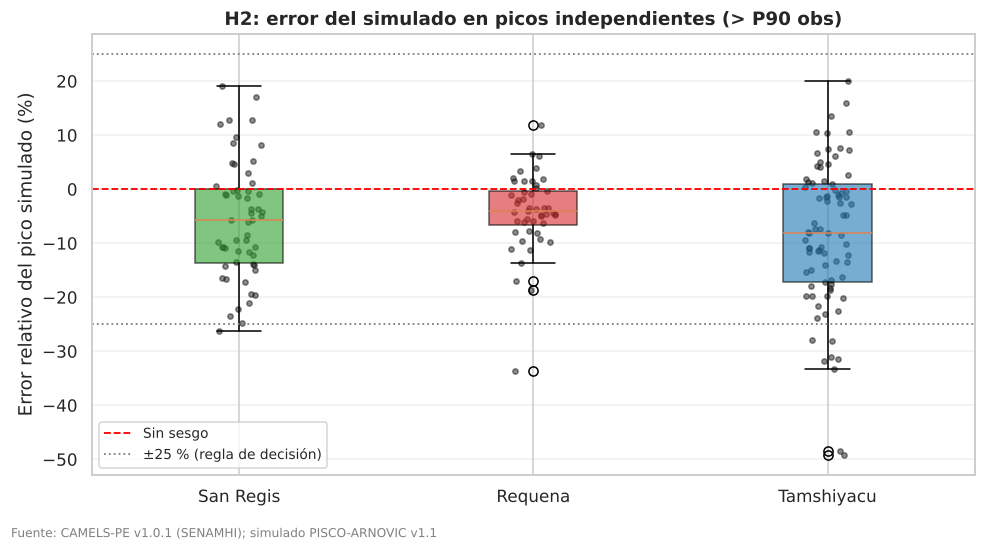

,θ (días),n picos,mediana error rel. (%),P25–P75 (%),picos subestimados (%),Shapiro p,Wilcoxon W,p (unilateral),r biserial,FHV (%),"mediana error, ventana con retardo (%)",picos elegidos en sim: mediana (obs−sim)/sim (%)
estación,,,,,,,,,,,,
San Regis,17,56,-5.6426,-13.6 a 0.0,75.0000,0.6636,359.0,0.0002,-0.5501,0.0898,-5.0391,-10.2
Requena,17,48,-4.0819,-6.6 a -0.3,75.0000,0.0011,200.0,0.0000,-0.6599,-0.8849,-3.1670,-3.2
Tamshiyacu,18,81,-8.0304,-17.1 a 1.0,72.8395,0.1175,606.0,0.0000,-0.6350,-0.5610,-7.4204,-8.0


In [34]:
def picos_independientes(q, umbral, separacion):
    """Picos sobre 'umbral' separados al menos 'separacion' días (se conserva el mayor de cada grupo)."""
    picos = []
    for fecha, valor in q[q > umbral].dropna().sort_values(ascending=False).items():
        if all(abs((fecha - f).days) >= separacion for f, _ in picos):
            picos.append((fecha, valor))
    return pd.Series(dict(picos)).sort_index()

filas, errores_picos = [], {}
for nombre, df in series.items():
    q = df['qobs_dep']
    theta = int(np.ceil(5 + np.log(area[nombre] / 2.58999)))
    picos = picos_independientes(q, q.quantile(0.90), theta)
    sim_max = [df['qsim'].loc[f - pd.Timedelta(days=2): f + pd.Timedelta(days=2)].max() for f in picos.index]
    err = pd.Series((np.array(sim_max) - picos.values) / picos.values, index=picos.index)
    errores_picos[nombre] = err
    w = stats.wilcoxon(err, alternative='less')
    rangos = stats.rankdata(np.abs(err))
    w_mas, w_menos = rangos[err > 0].sum(), rangos[err < 0].sum()
    sim_max_lag = [df['qsim'].loc[f - pd.Timedelta(days=2): f + pd.Timedelta(days=abs(ref_lag[nombre]) + 2)].max() for f in picos.index]
    err_lag = (np.array(sim_max_lag) - picos.values) / picos.values
    filas.append({'estación': nombre, 'θ (días)': theta, 'n picos': len(err), 'mediana error rel. (%)': 100 * err.median(),
                  'P25–P75 (%)': f"{100 * err.quantile(.25):.1f} a {100 * err.quantile(.75):.1f}",
                  'picos subestimados (%)': 100 * (err < 0).mean(), 'Shapiro p': stats.shapiro(err).pvalue,
                  'Wilcoxon W': w.statistic, 'p (unilateral)': w.pvalue, 'r biserial': (w_mas - w_menos) / (w_mas + w_menos),
                  'FHV (%)': tabla_metricas.loc[nombre, 'FHV (%)'],
                  'mediana error, ventana con retardo (%)': 100 * np.median(err_lag)})
tabla_h2 = pd.DataFrame(filas).set_index('estación').round(4)

simetria = {}
for nombre, df in series.items():
    s_sim = df['qsim'].where(df['qobs_dep'].notna())
    picos_s = picos_independientes(s_sim, s_sim.quantile(0.90), tabla_h2.loc[nombre, 'θ (días)'])
    obs_max = [df['qobs_dep'].loc[f - pd.Timedelta(days=2): f + pd.Timedelta(days=2)].max() for f in picos_s.index]
    simetria[nombre] = 100 * np.nanmedian((np.array(obs_max) - picos_s.values) / picos_s.values)
tabla_h2['picos elegidos en sim: mediana (obs−sim)/sim (%)'] = pd.Series(simetria).round(1)

fig, ax = plt.subplots(figsize=(9, 4.8))
nombres = list(ESTACIONES.values())
bp = ax.boxplot([100 * errores_picos[n] for n in nombres], tick_labels=nombres, patch_artist=True)
for caja, n in zip(bp['boxes'], nombres):
    caja.set_facecolor(COLORES[n]); caja.set_alpha(0.6)
for i, n in enumerate(nombres, start=1):
    ax.scatter(np.full(len(errores_picos[n]), i) + rng.uniform(-0.08, 0.08, len(errores_picos[n])),
               100 * errores_picos[n], s=12, color='k', alpha=0.5)
ax.axhline(0, color='red', ls='--', lw=1.2, label='Sin sesgo')
ax.axhline(-SESGO_PICOS_MAX, color='gray', ls=':', lw=1.2, label=f'±{SESGO_PICOS_MAX:.0f} % (regla de decisión)')
ax.axhline(SESGO_PICOS_MAX, color='gray', ls=':', lw=1.2)
ax.set_ylabel('Error relativo del pico simulado (%)')
ax.set_title('H2: error del simulado en picos independientes (> P90 obs)', fontweight='bold')
ax.legend(fontsize=9); ax.grid(True, axis='y', alpha=0.3)
nota_fuente(fig)
plt.tight_layout()
fig.savefig(RUTA_FIG / 'fig08_h2_picos.png', dpi=200, bbox_inches='tight')
plt.show()
tabla_h2

**Interpretación — H2 se acepta: el simulado subestima los picos en las tres estaciones,** pero poco.

| | San Regis | Requena | Tamshiyacu |
|---|---|---|---|
| Picos independientes (θ) | 56 (17 d) | 48 (17 d) | 81 (18 d) |
| Mediana del error | **−5.6 %** | **−4.1 %** | **−8.0 %** |
| Picos subestimados | 75 % | 75 % | 73 % |
| Wilcoxon p (unilateral) | 0.0002 | < 0.0001 | < 0.0001 |
| r biserial | −0.55 | −0.66 | −0.64 |

- **Prueba:** Shapiro-Wilk rechaza la normalidad en Requena (p = 0.001), por eso se usa Wilcoxon en todas.
- **Robustez:**
  - El resultado no se debe a cómo se eligen los picos: eligiéndolos en el simulado, el observado sigue siendo mayor (−10.2 %, −3.2 % y −8.0 %).
  - Tampoco al retardo: con una ventana que incluye el desfase típico, la mediana es −5.0 %, −3.2 % y −7.4 %.
- **Lectura:** el FHV, en cambio, es casi 0 (< 1 %): los caudales altos existen en el simulado, pero no siempre el día del pico observado.

La subestimación está muy dentro del ±25 % de la regla de decisión.

### 7.3 H3 — Diferencia de desempeño entre épocas
> **H3.** "El KGE del simulado difiere entre la época húmeda y la seca."

- **Prueba:** ΔKGE = KGE_húmeda − KGE_seca con IC 95 % por bootstrap estratificado de bloques mensuales; bilateral.

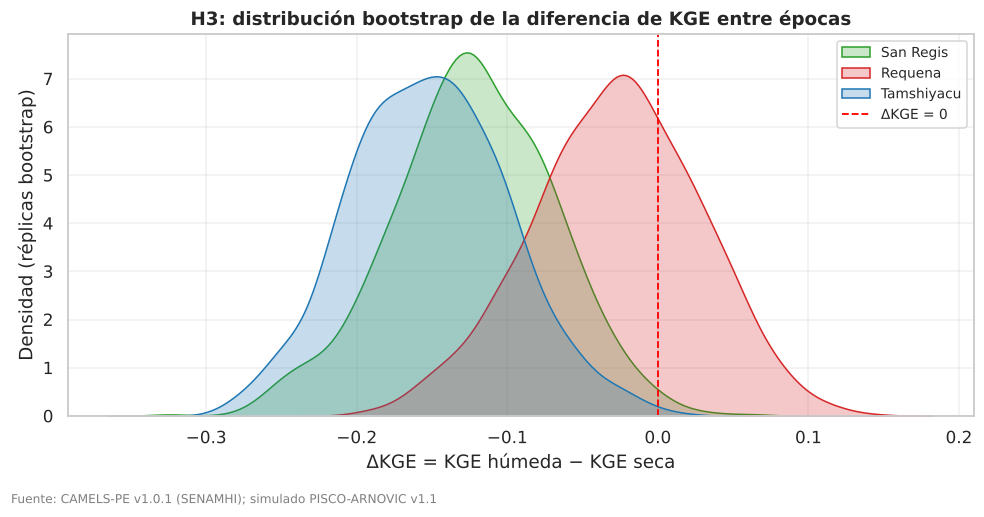

,KGE húmeda,KGE seca,ΔKGE,IC95 ΔKGE,p bootstrap (bilateral),se rechaza H0
estación,,,,,,
San Regis,0.528,0.652,-0.124,"[-0.24, -0.02]",0.016,True
Requena,0.735,0.764,-0.029,"[-0.14, 0.08]",0.624,False
Tamshiyacu,0.475,0.629,-0.154,"[-0.25, -0.05]",0.002,True


In [35]:
filas, deltas = [], {}
for nombre, p in pareados.items():
    hum = p[p.index.month.isin(meses_humedos[nombre])]
    sec = p[~p.index.month.isin(meses_humedos[nombre])]
    b_h = bootstrap_bloques_mensuales(hum, lambda d: kge(d['obs'], d['sim'])[0], semilla=SEMILLA)
    b_s = bootstrap_bloques_mensuales(sec, lambda d: kge(d['obs'], d['sim'])[0], semilla=SEMILLA + 1)
    delta = b_h - b_s
    deltas[nombre] = delta
    ic = np.percentile(delta, [2.5, 97.5])
    k_h, k_s = kge(hum['obs'], hum['sim'])[0], kge(sec['obs'], sec['sim'])[0]
    filas.append({'estación': nombre, 'KGE húmeda': k_h, 'KGE seca': k_s, 'ΔKGE': k_h - k_s,
                  'IC95 ΔKGE': f"[{ic[0]:.2f}, {ic[1]:.2f}]", 'p bootstrap (bilateral)': 2 * min((delta <= 0).mean(), (delta >= 0).mean()),
                  'se rechaza H0': not (ic[0] <= 0 <= ic[1])})
tabla_h3 = pd.DataFrame(filas).set_index('estación').round(3)

fig, ax = plt.subplots(figsize=(9, 4.5))
for n, d in deltas.items():
    sns.kdeplot(d, ax=ax, color=COLORES[n], fill=True, alpha=0.25, label=n)
ax.axvline(0, color='red', ls='--', lw=1.2, label='ΔKGE = 0')
ax.set_xlabel('ΔKGE = KGE húmeda − KGE seca'); ax.set_ylabel('Densidad (réplicas bootstrap)')
ax.set_title('H3: distribución bootstrap de la diferencia de KGE entre épocas', fontweight='bold')
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)
nota_fuente(fig)
plt.tight_layout()
fig.savefig(RUTA_FIG / 'fig09_h3_epocas.png', dpi=200, bbox_inches='tight')
plt.show()
tabla_h3

**Interpretación — H3 se acepta en San Regis y Tamshiyacu y se rechaza en Requena.**
- **San Regis:** el KGE es **menor en la época húmeda**, ΔKGE = −0.124 (IC 95 % [−0.24, −0.02]; p = 0.016).
- **Tamshiyacu:** ΔKGE = −0.154 ([−0.25, −0.05]; p = 0.002).
- **Requena:** no hay diferencia, ΔKGE = −0.029 ([−0.14, 0.08]; p = 0.624).

**Lectura:** en San Regis y Tamshiyacu, el simulado es menos confiable justo en la época de crecidas, que es la relevante para alertas.

### 7.4 H4 — Dinámica de corto plazo
> **H4.** "El simulado reproduce la variabilidad día a día del observado." H0: RB_sim = RB_obs.

- **Prueba:** razón RB_sim/RB_obs con IC 95 % por bootstrap de bloques mensuales (Σ|ΔQ| y ΣQ dentro de cada mes). El estimador puntual se calcula con los **mismos pares de días dentro de cada mes** que el bootstrap, para que el IC corresponda a él; se reporta aparte el RB con todos los pares, que incluye el salto del cambio de mes del simulado (2.6) y los escalones del observado (2.7). Usar solo pares dentro del mes deja fuera ambos artefactos. Complemento: autocorrelación de rezago 1 y tiempo de decorrelación de las anomalías de log(Q + ε), buscado hasta 180 días por la memoria larga de estos ríos.

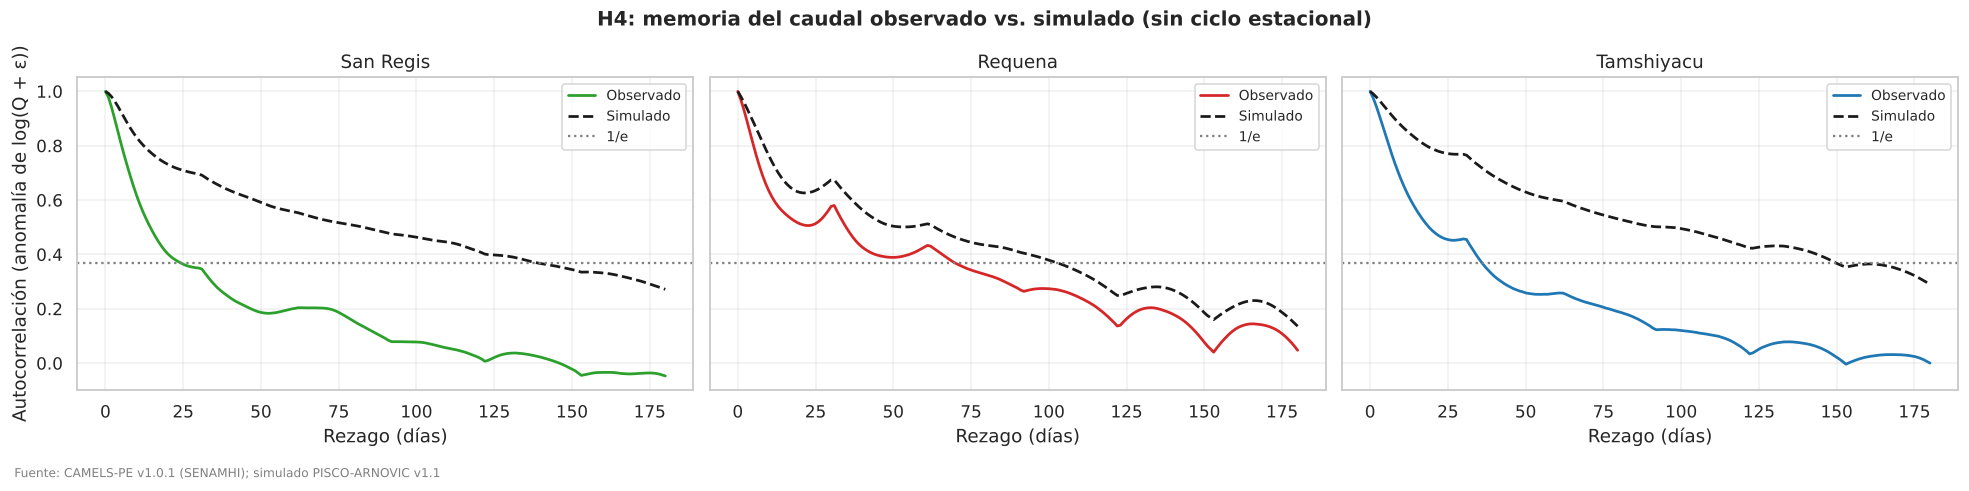

,RB obs,RB sim,razón RB sim/obs,IC95 razón,se rechaza H0,razón con todos los pares (incluye cambio de mes),r1 obs,r1 sim,T_dec anomalía obs (d),T_dec anomalía sim (d)
estación,,,,,,,,,,
San Regis,0.01457,0.01170,0.80343,"[0.742, 0.868]",True,0.83818,0.99615,0.99780,25,140
Requena,0.01149,0.01057,0.91968,"[0.862, 0.985]",True,1.00063,0.99886,0.99864,70,104
Tamshiyacu,0.01181,0.00847,0.71731,"[0.679, 0.757]",True,0.75764,0.99797,0.99923,37,150


In [36]:
MAX_LAG_DEC = 180

def sumas_rb_mensuales(p):
    """Para cada mes: Σ|ΔQ| y ΣQ de obs y sim con pares de días consecutivos válidos en ambas series."""
    filas = []
    for _, g in p.groupby([p.index.year, p.index.month]):
        g = g.asfreq('D')
        dq_o, dq_s = g['obs'].diff().abs(), g['sim'].diff().abs()
        val = dq_o.notna() & dq_s.notna()
        filas.append([dq_o[val].sum(), dq_s[val].sum(), g['obs'][val].sum(), g['sim'][val].sum()])
    return np.array(filas)

def tiempo_decorrelacion(s, max_lag=MAX_LAG_DEC):
    """Rezago (días) en que la autocorrelación de s cae bajo 1/e."""
    for k in range(1, max_lag + 1):
        if s.autocorr(k) < np.exp(-1):
            return k
    return np.nan

def anomalia_log(s, eps):
    """Anomalía de log(Q + ε) respecto a la media de cada mes calendario."""
    l = np.log(s + eps)
    return l - l.groupby(l.index.month).transform('mean')

filas = []
for nombre, p in pareados.items():
    pd_d = p.asfreq('D')
    eps = p['obs'].mean() / 100
    rb_o = richards_baker(pd_d['obs'].where(pd_d['sim'].notna()))
    rb_s = richards_baker(pd_d['sim'].where(pd_d['obs'].notna()))
    sumas = sumas_rb_mensuales(p)
    tot = sumas.sum(axis=0)
    rb_o_mes, rb_s_mes = tot[0] / tot[2], tot[1] / tot[3]
    gen = np.random.default_rng(SEMILLA)
    boot = np.empty(N_BOOT)
    for b in range(N_BOOT):
        m = sumas[gen.integers(0, len(sumas), len(sumas))].sum(axis=0)
        boot[b] = (m[1] / m[3]) / (m[0] / m[2])
    ic = np.percentile(boot, [2.5, 97.5])
    filas.append({'estación': nombre, 'RB obs': rb_o_mes, 'RB sim': rb_s_mes, 'razón RB sim/obs': rb_s_mes / rb_o_mes,
                  'IC95 razón': f"[{ic[0]:.3f}, {ic[1]:.3f}]", 'se rechaza H0': not (ic[0] <= 1 <= ic[1]),
                  'razón con todos los pares (incluye cambio de mes)': rb_s / rb_o,
                  'r1 obs': p['obs'].autocorr(1), 'r1 sim': p['sim'].autocorr(1),
                  'T_dec anomalía obs (d)': tiempo_decorrelacion(anomalia_log(pd_d['obs'], eps)),
                  'T_dec anomalía sim (d)': tiempo_decorrelacion(anomalia_log(pd_d['sim'], eps))})
tabla_h4 = pd.DataFrame(filas).set_index('estación').round(5)
for col in ['T_dec anomalía obs (d)', 'T_dec anomalía sim (d)']:      # NaN = no cae bajo 1/e en MAX_LAG_DEC días
    tabla_h4[col] = tabla_h4[col].apply(lambda v: f'> {MAX_LAG_DEC}' if pd.isna(v) else str(int(v)))

fig, ejes = plt.subplots(1, len(pareados), figsize=(6 * len(pareados), 4.2), sharey=True)
for ax, (nombre, p) in zip(ejes, pareados.items()):
    pd_d = p.asfreq('D')
    eps = p['obs'].mean() / 100
    for col, estilo, etiqueta in [('obs', '-', 'Observado'), ('sim', '--', 'Simulado')]:
        a = anomalia_log(pd_d[col], eps)
        ax.plot(range(MAX_LAG_DEC + 1), [a.autocorr(k) for k in range(MAX_LAG_DEC + 1)], estilo,
                color=COLORES[nombre] if col == 'obs' else 'k', lw=1.8, label=etiqueta)
    ax.axhline(np.exp(-1), color='gray', ls=':', label='1/e')
    ax.set_xlabel('Rezago (días)'); ax.set_title(nombre); ax.grid(True, alpha=0.3); ax.legend(fontsize=9)
ejes[0].set_ylabel('Autocorrelación (anomalía de log(Q + ε))')
fig.suptitle('H4: memoria del caudal observado vs. simulado (sin ciclo estacional)', fontsize=13, fontweight='bold')
nota_fuente(fig)
plt.tight_layout()
fig.savefig(RUTA_FIG / 'fig10_h4_memoria.png', dpi=200, bbox_inches='tight')
plt.show()
tabla_h4

**Interpretación — H4 se rechaza en las tres estaciones: el simulado es más suave que el río.**

| | San Regis | Requena | Tamshiyacu |
|---|---|---|---|
| RB_sim / RB_obs (pares dentro del mes) | 0.803 [0.742, 0.868] | 0.920 [0.862, 0.985] | 0.717 [0.679, 0.757] |
| Con todos los pares | 0.838 | 1.001 | 0.758 |
| Tiempo de decorrelación obs / sim | 25 / 140 d | 70 / 104 d | 37 / 150 d |

- **Variabilidad día a día:** el simulado tiene un 8–28 % menos que el observado.
- **Por qué importa excluir el cambio de mes:** con todos los pares, Requena parecería reproducir la dinámica (razón 1.001), pero solo porque los saltos del simulado en el cambio de mes compensan su suavidad.
- **Memoria:** las anomalías del simulado tardan **4–6 veces más** en perder la correlación que las del río en San Regis y Tamshiyacu (1.5 veces en Requena).
- **Figura:** se ven "codos" en las curvas de autocorrelación cada ~30 días (31, 61, 92, 122, 153), en obs y sim. Son el efecto de los saltos de cambio de mes y de quitar la media de cada mes, no una periodicidad hidrológica.

**Consecuencia para HP1:** un modelo entrenado con el simulado aprendería una persistencia mucho mayor que la real y **sobreestimaría el horizonte útil** de pronóstico.

### 7.5 Decisión: ¿se puede trabajar solo con el caudal simulado?
Se aplica la regla fijada en 0.4.

In [37]:
decision = pd.DataFrame({
    'H1 cumple': tabla_h1['H1 se cumple'],
    '|mediana error picos| ≤ 25 %': tabla_h2['mediana error rel. (%)'].abs() <= SESGO_PICOS_MAX,
    'H4: IC incluye igualdad': ~tabla_h4['se rechaza H0'],
})
decision['simulado sustituye al observado'] = decision.all(axis=1)
decision.to_csv(RUTA_TAB / 'tabla_decision_simulado.csv')
decision

,H1 cumple,|mediana error picos| ≤ 25 %,H4: IC incluye igualdad,simulado sustituye al observado
estación,,,,
San Regis,False,True,False,False
Requena,False,True,False,False
Tamshiyacu,False,True,False,False


**Interpretación — el simulado no puede sustituir al observado en ninguna de las tres estaciones.**
- **Lo que cumple:** el sesgo en picos es pequeño (−4 a −8 %).
- **Lo que falla:**
  - H1, porque el simulado no supera a la climatología mensual a escala diaria (BE < 0);
  - H4, porque es más suave y tiene mucha más memoria que el río.

**Uso aceptable del simulado:** solo como dato mensual o de régimen (NSE mensual 0.64–0.86). Para pronóstico diario y umbrales hay que usar el observado.

---
## 8. Visualización y mapas

### 8.1 Distribuciones
Histogramas de log₁₀(Q) (Lab4_2, `sns.histplot` con KDE) y diagramas de caja por mes (Ses2, Lab4_2), en fechas confiables.

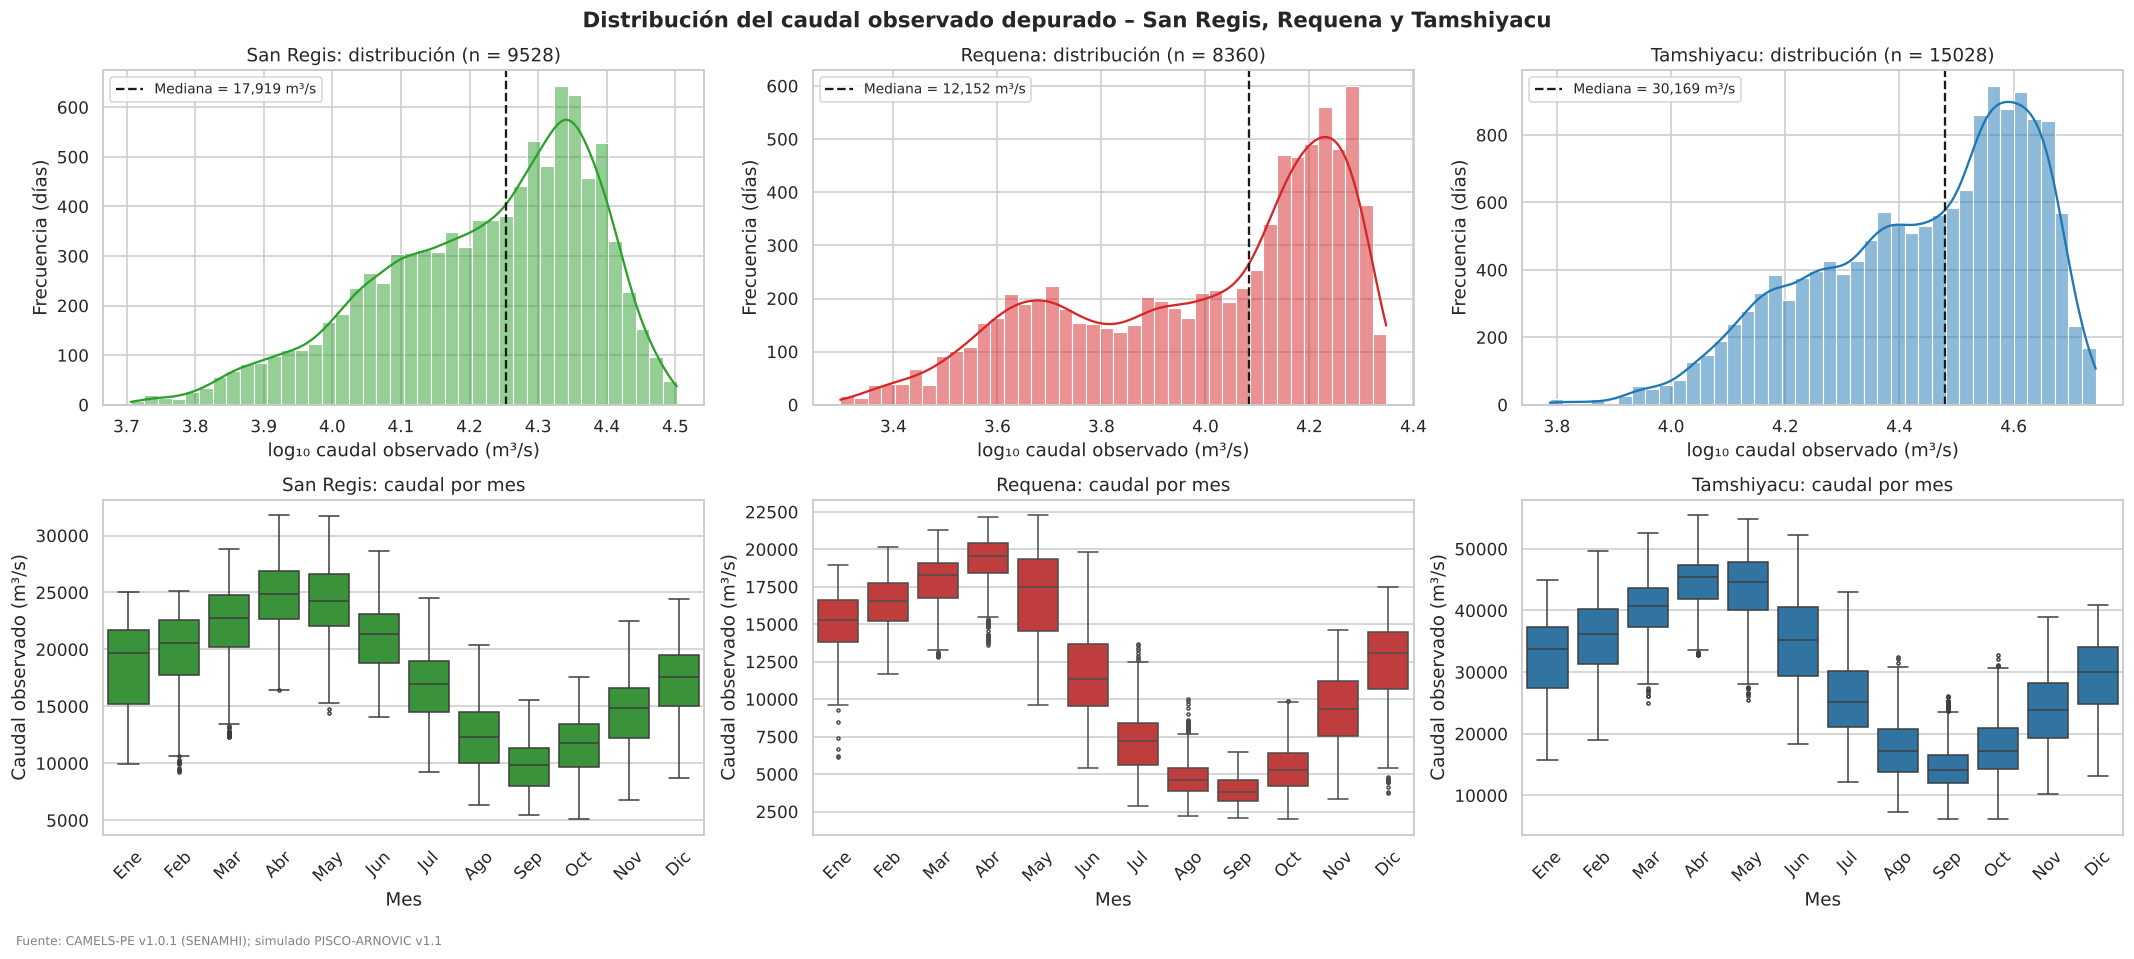

In [38]:
fig, ejes = plt.subplots(2, len(ESTACIONES), figsize=(6.5 * len(ESTACIONES), 8.5))
for j, (nombre, df) in enumerate(series.items()):
    q = df['qobs_dep'].dropna()
    ax = ejes[0, j]
    sns.histplot(np.log10(q), bins=40, kde=True, color=COLORES[nombre], ax=ax)
    ax.axvline(np.log10(q.median()), color='k', ls='--', label=f'Mediana = {q.median():,.0f} m³/s')
    ax.set_xlabel('log₁₀ caudal observado (m³/s)'); ax.set_ylabel('Frecuencia (días)')
    ax.set_title(f'{nombre}: distribución (n = {len(q)})'); ax.legend(fontsize=9)
    ax = ejes[1, j]
    d = pd.DataFrame({'q': q, 'mes': q.index.month})
    sns.boxplot(data=d, x='mes', y='q', color=COLORES[nombre], ax=ax, fliersize=2)
    ax.set_xticks(range(12)); ax.set_xticklabels(meses_es, rotation=45)
    ax.set_xlabel('Mes'); ax.set_ylabel('Caudal observado (m³/s)'); ax.set_title(f'{nombre}: caudal por mes')
fig.suptitle('Distribución del caudal observado depurado – San Regis, Requena y Tamshiyacu', fontsize=14, fontweight='bold')
nota_fuente(fig)
plt.tight_layout()
fig.savefig(RUTA_FIG / 'fig11_distribuciones.png', dpi=200, bbox_inches='tight')
plt.show()

**Interpretación:**
- **Distribuciones de log₁₀ Q:**
  - San Regis y Tamshiyacu: asimétricas a la izquierda, con una cola de estiajes larga.
  - Requena: **bimodal**, con un modo de estiaje (~4 000–5 000 m³/s) y otro de crecida (~17 000 m³/s), porque el Ucayali pasa rápido de un estado al otro.
  - Medianas: 17 919 (San Regis), 12 152 (Requena) y 30 169 m³/s (Tamshiyacu).
- **Ciclo mensual muy regular:**
  - las cajas suben de octubre a abril y bajan de mayo a setiembre;
  - la variabilidad interanual de cada mes (altura de la caja) es pequeña frente a la amplitud del ciclo. Las excepciones son enero–marzo en San Regis y mayo–junio en Requena (meses de transición).

Esa regularidad es la que hace que la climatología mensual sea un benchmark tan exigente (H1).

### 8.2 Series de tiempo completas y medias móviles
Serie diaria observada (depurada) y simulada 1981–2025 con media móvil de 30 días (Lab5_1, `rolling`); se marcan los puntos eliminados en 4.3 y los meses excluidos en 4.4 y, si 2.7 recortó alguna estación, se sombrea el periodo excluido.

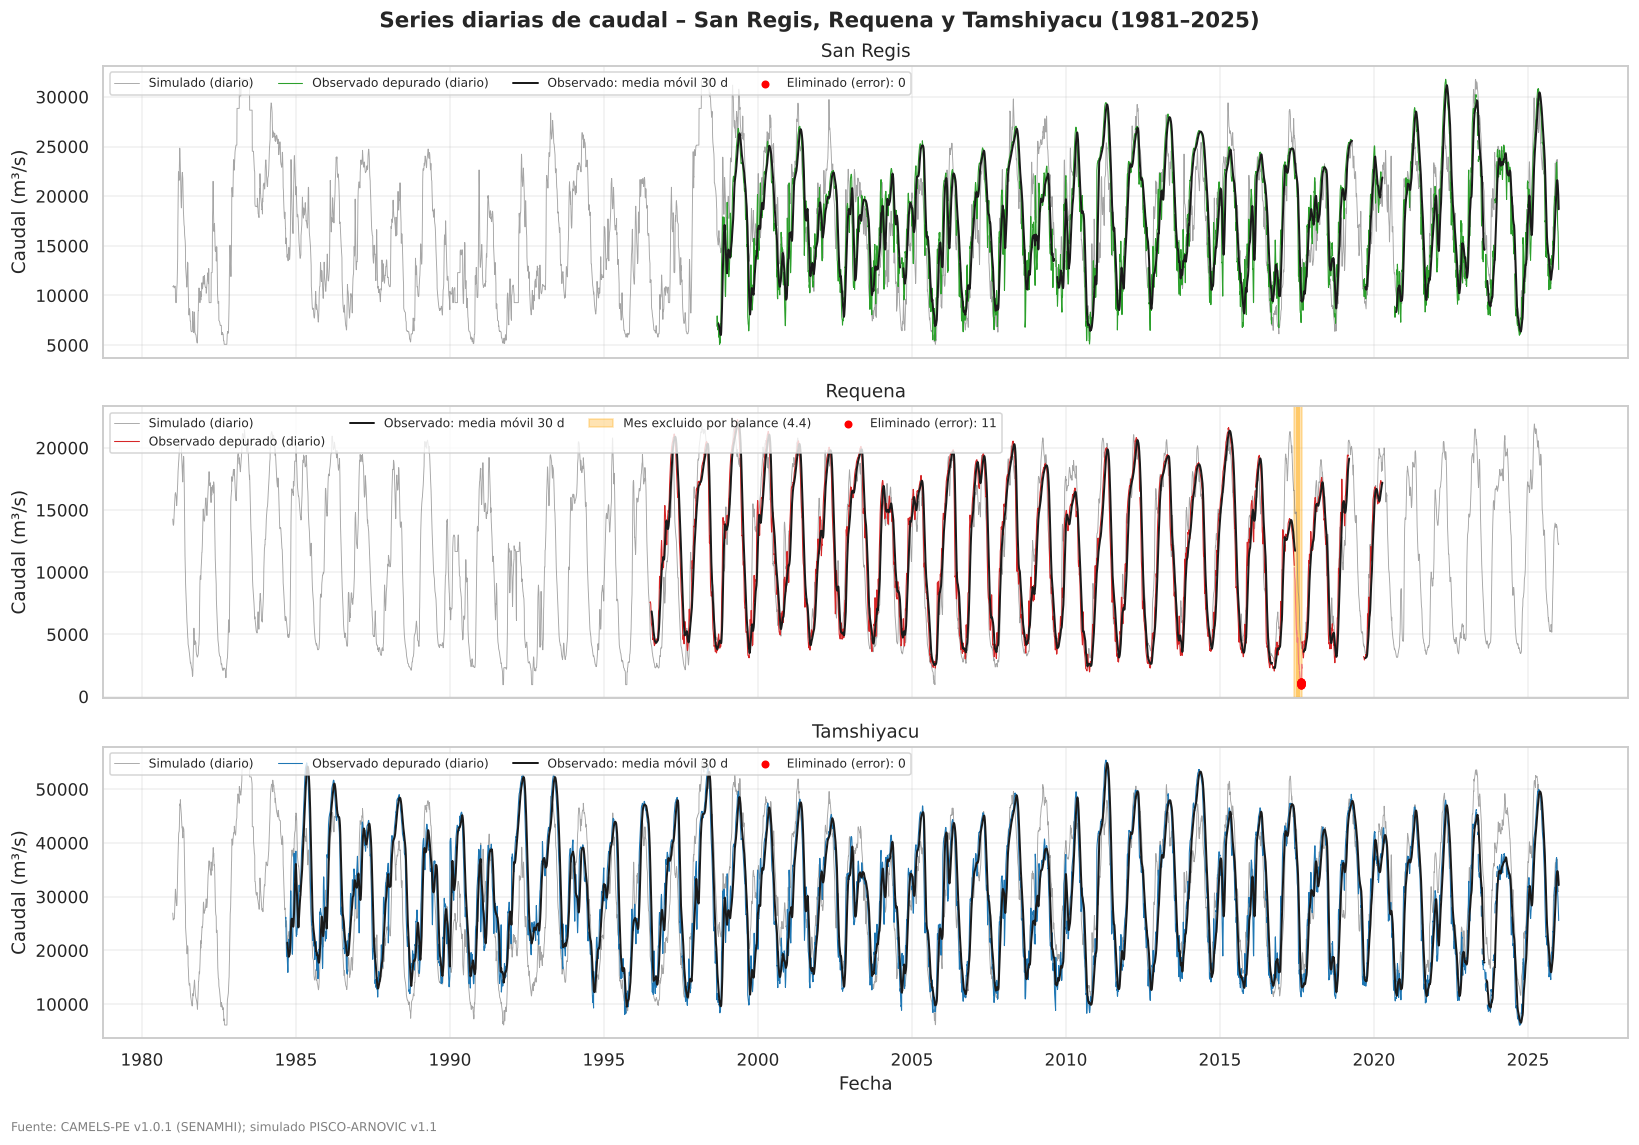

In [39]:
fig, ejes = plt.subplots(len(ESTACIONES), 1, figsize=(15, 3.4 * len(ESTACIONES)), sharex=True)
for ax, (nombre, df) in zip(ejes, series.items()):
    ax.plot(df.index, df['qsim'], color='gray', lw=0.6, alpha=0.7, label='Simulado (diario)')
    if nombre in recortadas:
        ax.plot(df.index, df['qobs'].where(df.index < inicio_confiable[nombre]), color='lightcoral', lw=0.6,
                label='Observado del archivo (fechas no confiables)')
        ax.axvspan(df['qobs'].first_valid_index(), inicio_confiable[nombre], color='orange', alpha=0.12,
                   label='Excluido: error de fechas (2.7)')
    ax.plot(df.index, df['qobs_dep'], color=COLORES[nombre], lw=0.7, label='Observado depurado (diario)')
    ax.plot(df.index, df['qobs_dep'].rolling(30, min_periods=20).mean(), color='k', lw=1.3, label='Observado: media móvil 30 d')
    for i, m in enumerate(meses_excluidos[nombre]):
        ax.axvspan(m.start_time, m.end_time, color='orange', alpha=0.3, label='Mes excluido por balance (4.4)' if i == 0 else None)
        ax.plot(df['qobs'].loc[m.start_time:m.end_time], color='lightcoral', lw=0.8)
    err = df.index[banderas[nombre].reindex(df.index).fillna(False).values]
    ax.scatter(err, df.loc[err, 'qobs'], color='red', s=18, zorder=5, label=f'Eliminado (error): {len(err)}')
    ax.set_ylabel('Caudal (m³/s)'); ax.set_title(nombre); ax.legend(loc='upper left', fontsize=8, ncol=4); ax.grid(True, alpha=0.3)
ejes[-1].set_xlabel('Fecha')
fig.suptitle('Series diarias de caudal – San Regis, Requena y Tamshiyacu (1981–2025)', fontsize=14, fontweight='bold')
nota_fuente(fig)
plt.tight_layout()
fig.savefig(RUTA_FIG / 'fig12_series_completas.png', dpi=200, bbox_inches='tight')
plt.show()

**Interpretación:**
- **San Regis y Tamshiyacu:** el observado sigue al simulado en el ciclo anual, con más variabilidad de corto plazo.
- **Requena:** el estiaje de 2017 es claramente anómalo.
  - El pico de 2017 es el menor del registro (~14 000 m³/s).
  - El caudal baja hasta 958 m³/s en agosto, mientras el simulado y el balance indican ~4 000 m³/s.
  - En la figura se ven sombreados los meses excluidos (4.4) y en rojo los 11 días eliminados (4.3).
- **Lo que la escala de la figura no deja ver:** los escalones de nivel en el cambio de mes (2.7) solo son visibles en el detalle de la figura 2b.
- **Fuera del periodo observado:** en 1983 el simulado de Tamshiyacu llega a 55 424 m³/s, el máximo observado (2011), y se queda ahí varios días. El simulado de Requena toca el mínimo erróneo de 958.5 m³/s en 1991 (2.6).

### 8.3 Descomposición de la serie mensual de la estación con el registro confiable más largo
Se elige automáticamente la estación con más meses válidos (OMM) en fechas confiables y su tramo continuo más largo de medias mensuales válidas (interpolando meses aislados, ≤ 1), y se aplica `seasonal_decompose` (Lab5_1) **aditivo sobre log(Q)** con período 12, junto al simulado; ADF (Lab5_1) sobre el residuo.

Estación: Tamshiyacu | tramo continuo usado: 1984-09 a 2023-06 (466 meses; meses interpolados: 1); mínimo mensual = 9,539 m³/s


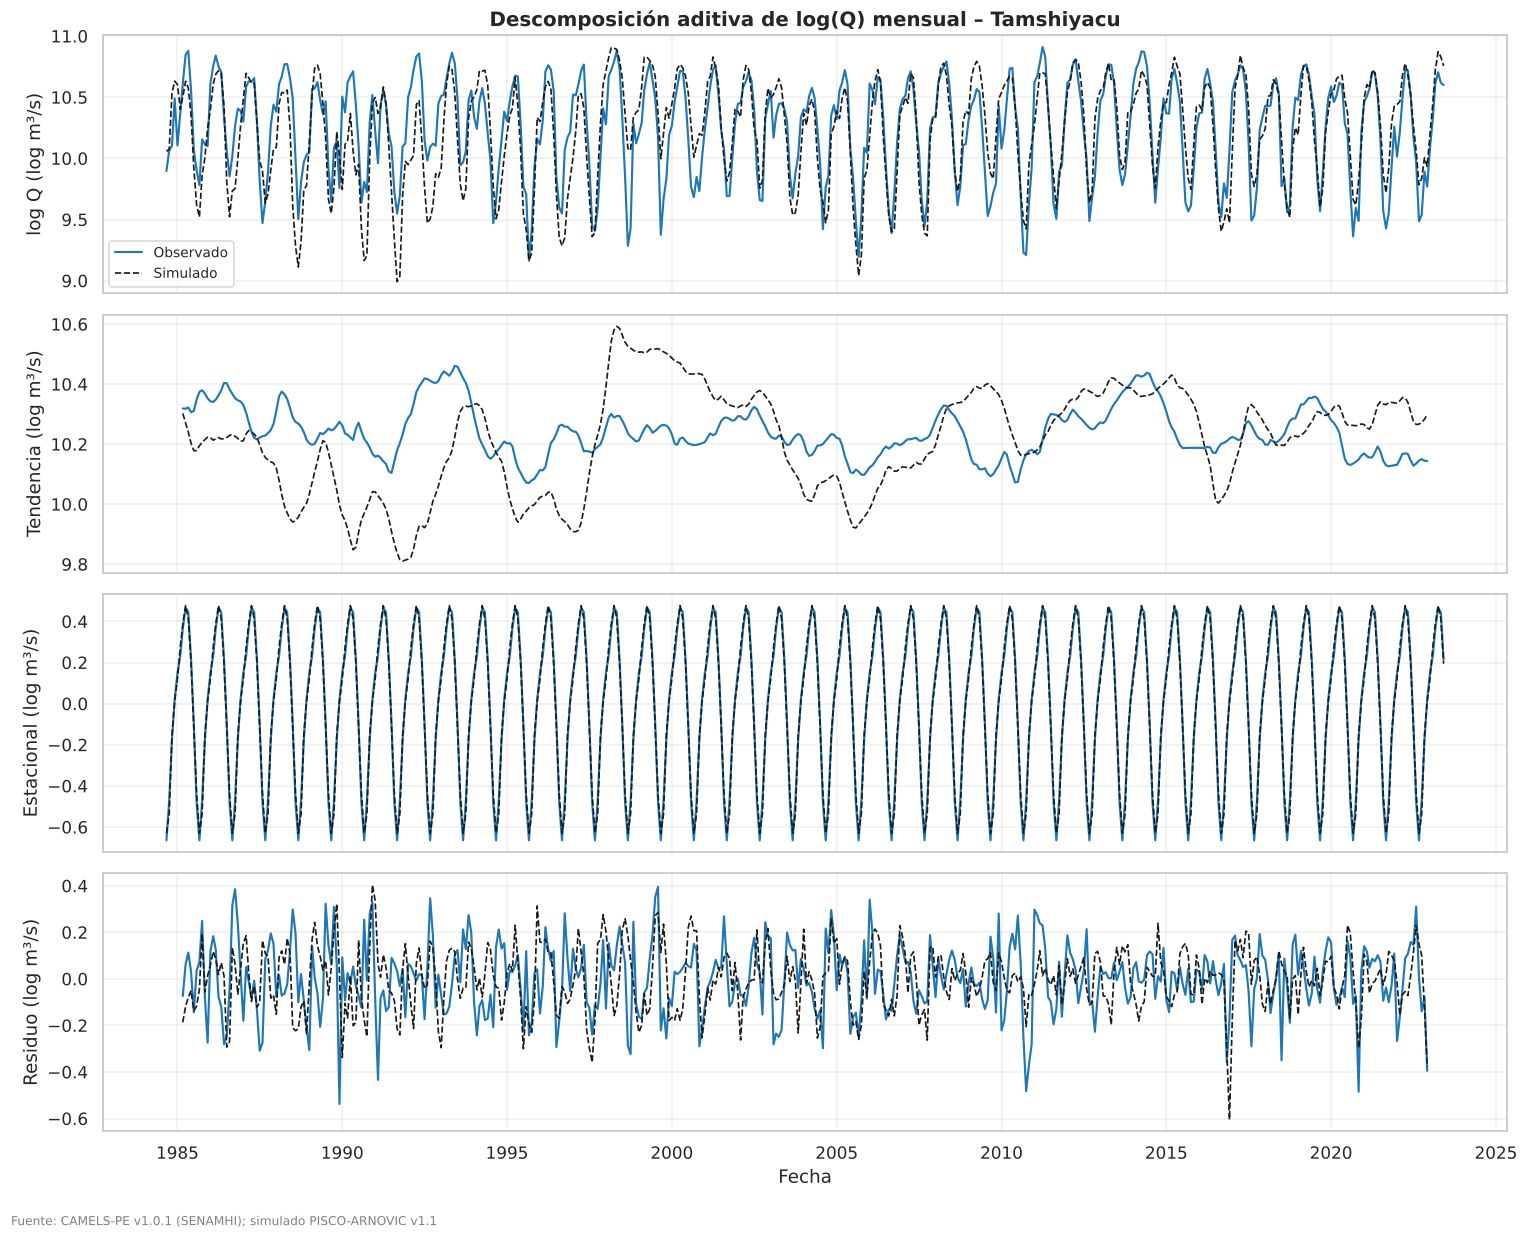

Amplitud estacional (log): obs = 1.131 (factor ×3.10); sim = 1.107 (factor ×3.03)
Mes del máximo estacional: obs = Abr, sim = Abr
Pendiente de la tendencia obs (log/año): -0.0017
ADF residuo obs: p = 0.0000


In [40]:
mensual_valida = {n: serie_mensual_valida(series[n]['qobs_dep']).asfreq('MS') for n in ESTACIONES.values()}
est_desc = max(mensual_valida, key=lambda n: mensual_valida[n].notna().sum())
qm = mensual_valida[est_desc]
qm_int = qm.interpolate(limit=1, limit_area='inside')
v2 = qm_int.notna()
g2 = (v2 != v2.shift()).cumsum()
largo = v2.groupby(g2).transform('sum').where(v2)
tramo = qm_int[g2 == g2[largo == largo.max()].iloc[0]]
print(f"Estación: {est_desc} | tramo continuo usado: {tramo.index.min():%Y-%m} a {tramo.index.max():%Y-%m} ({len(tramo)} meses; "
      f"meses interpolados: {int(qm.loc[tramo.index].isna().sum())}); mínimo mensual = {tramo.min():,.0f} m³/s")
sim_tramo = series[est_desc]['qsim'].resample('MS').mean().loc[tramo.index]
desc_o = seasonal_decompose(np.log(tramo), model='additive', period=12)
desc_s = seasonal_decompose(np.log(sim_tramo), model='additive', period=12)
fig, ejes = plt.subplots(4, 1, figsize=(14, 11), sharex=True)
for ax, comp, et_ in zip(ejes, ['observed', 'trend', 'seasonal', 'resid'], ['log Q', 'Tendencia', 'Estacional', 'Residuo']):
    ax.plot(getattr(desc_o, comp), color=COLORES[est_desc], lw=1.4, label='Observado')
    ax.plot(getattr(desc_s, comp), color='k', ls='--', lw=1.1, label='Simulado')
    ax.set_ylabel(et_ + ' (log m³/s)'); ax.grid(True, alpha=0.3)
ejes[0].legend(fontsize=9); ejes[-1].set_xlabel('Fecha')
ejes[0].set_title(f'Descomposición aditiva de log(Q) mensual – {est_desc}', fontsize=13, fontweight='bold')
nota_fuente(fig)
plt.tight_layout()
fig.savefig(RUTA_FIG / f'fig13_descomposicion_{est_desc}.png', dpi=200, bbox_inches='tight')
plt.show()
amp_o = desc_o.seasonal.max() - desc_o.seasonal.min()
amp_s = desc_s.seasonal.max() - desc_s.seasonal.min()
print(f"Amplitud estacional (log): obs = {amp_o:.3f} (factor ×{np.exp(amp_o):.2f}); sim = {amp_s:.3f} (factor ×{np.exp(amp_s):.2f})")
print(f"Mes del máximo estacional: obs = {meses_es[desc_o.seasonal.groupby(desc_o.seasonal.index.month).mean().idxmax() - 1]}, "
      f"sim = {meses_es[desc_s.seasonal.groupby(desc_s.seasonal.index.month).mean().idxmax() - 1]}")
print(f"Pendiente de la tendencia obs (log/año): "
      f"{stats.linregress(np.arange(desc_o.trend.dropna().size) / 12, desc_o.trend.dropna()).slope:.4f}")
print(f"ADF residuo obs: p = {adfuller(desc_o.resid.dropna())[1]:.4f}")

**Interpretación:** se descompone Tamshiyacu, la estación con más meses válidos. Usa el tramo continuo de 1984-09 a 2023-06 (466 meses, 1 interpolado).
- **Componente estacional:** domina, con una amplitud de ×3.10 en el observado frente a ×3.03 en el simulado, y máximo en abril en ambos.
- **Tendencia:** prácticamente nula (−0.0017 log/año, ≈ −0.2 %/año).
- **Residuo:** estacionario (ADF p < 0.001).

El simulado reproduce bien la escala mensual, coherente con su NSE mensual de 0.64. Las diferencias diarias (H1, H4) no son visibles a esta escala.

### 8.4 Mapa de la cuenca y las estaciones
(a) Contexto: las 136 cuencas de CAMELS-PE con la cuenca hasta Tamshiyacu resaltada; (b) acercamiento: subcuencas de San Regis y Requena dentro de la de Tamshiyacu, estaciones coloreadas por KGE y con tamaño según % de vacíos, y las estaciones conectadas directamente (2.1) como referencia; (c) mapa interactivo Folium (Ses2).

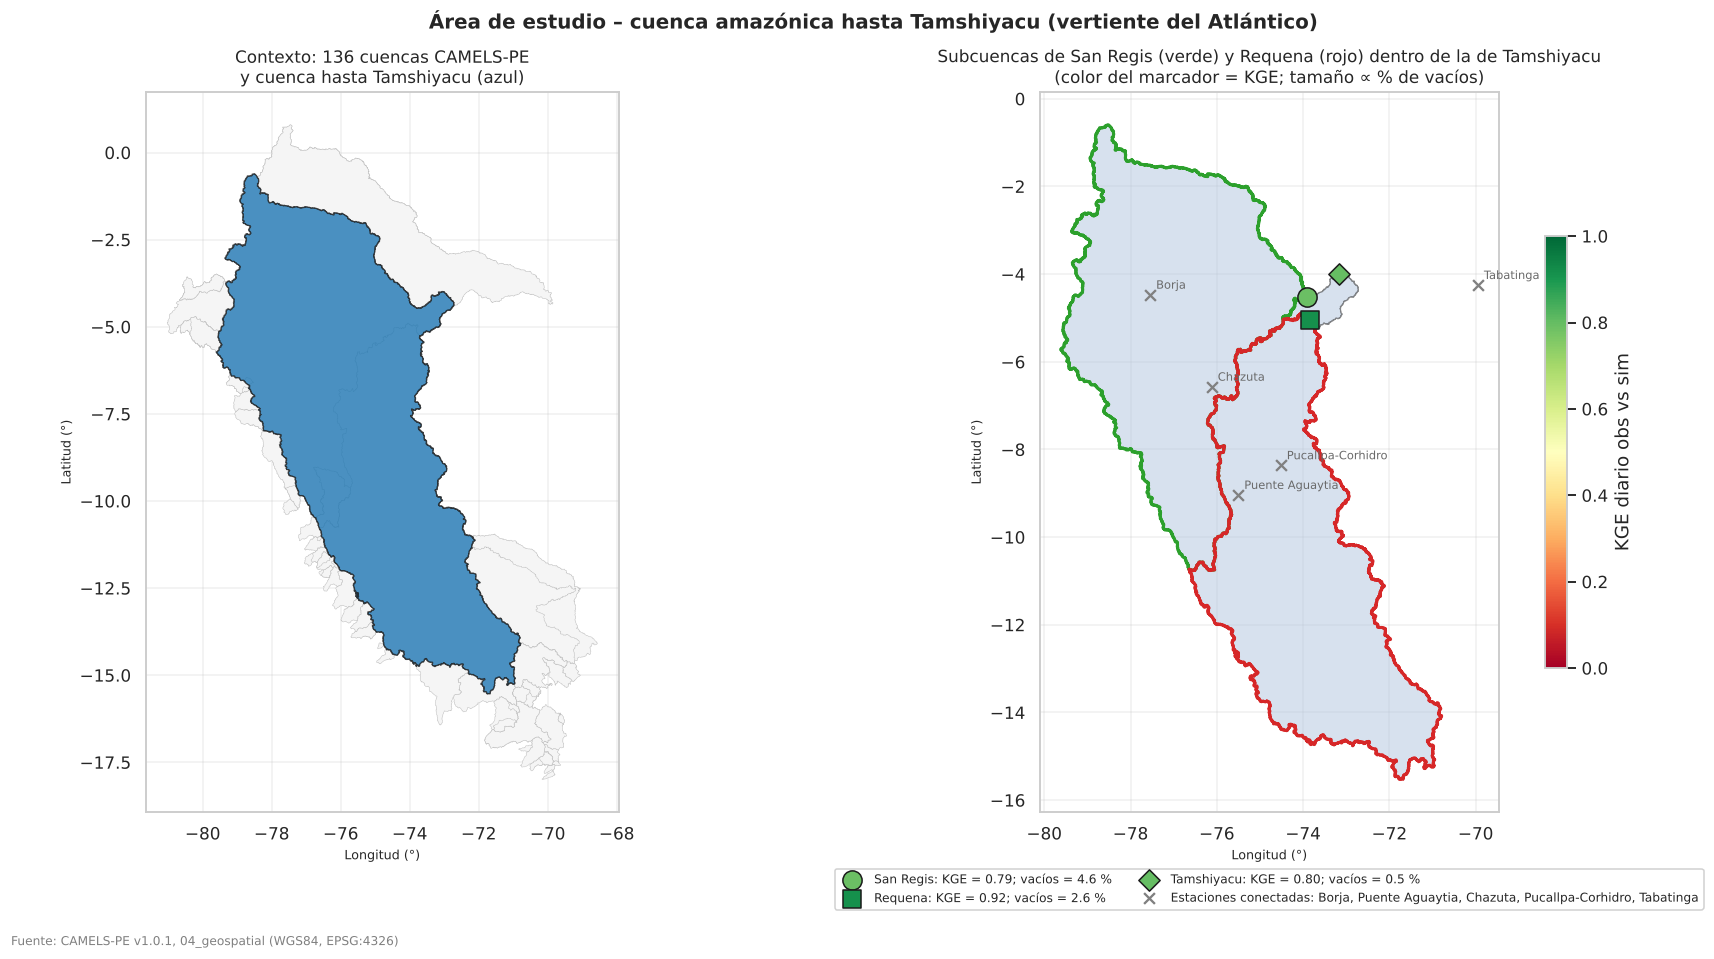

Mapa interactivo guardado en salidas/mapa_estaciones_amazonas.html


In [41]:
pol = cuencas_gpkg.set_index('gauge_id')
subcuencas = pol.loc[list(ESTACIONES)].copy()
subcuencas['estacion'] = subcuencas.index.map(ESTACIONES)
gid_sal = [g for g, n in ESTACIONES.items() if n == SALIDA][0]
pts_todos = puntos_gpkg.set_index('gauge_id')
pts = pts_todos.loc[list(ESTACIONES)].copy()
pts['estacion'] = pts.index.map(ESTACIONES)
pts['KGE'] = pts['estacion'].map(tabla_metricas['KGE'])
pts['vacios'] = pts['estacion'].map(tabla_vacios['% vacíos'])
otras_est = pts_todos.loc[[g for g in conectadas.index if g not in ESTACIONES and g in pts_todos.index]]

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(16, 8.5), gridspec_kw={'width_ratios': [0.8, 1.3]})
cuencas_gpkg.plot(ax=ax0, color='whitesmoke', edgecolor='silver', lw=0.3)
subcuencas.loc[[gid_sal]].plot(ax=ax0, color=COLORES[SALIDA], edgecolor='k', lw=0.8, alpha=0.8)
ax0.set_title(f'Contexto: 136 cuencas CAMELS-PE\ny cuenca hasta {SALIDA} (azul)', fontsize=11)
ax0.set_xlabel('Longitud (°)'); ax0.set_ylabel('Latitud (°)'); ax0.grid(True, alpha=0.3)

subcuencas.loc[[gid_sal]].plot(ax=ax1, color='lightsteelblue', edgecolor='k', lw=0.8, alpha=0.5)
for u in AGUAS_ARRIBA:
    gid_u = [g for g, n in ESTACIONES.items() if n == u][0]
    subcuencas.loc[[gid_u]].plot(ax=ax1, facecolor='none', edgecolor=COLORES[u], lw=2)
norma = plt.Normalize(0, 1)
for marcador, (gid, r) in zip(['o', 's', 'D'], pts.iterrows()):
    ax1.scatter(r.geometry.x, r.geometry.y, c=[plt.cm.RdYlGn(norma(r['KGE']))], s=90 + 15 * r['vacios'], marker=marcador,
                edgecolors='k', zorder=5, label=f"{r['estacion']}: KGE = {r['KGE']:.2f}; vacíos = {r['vacios']:.1f} %")
ax1.scatter(otras_est.geometry.x, otras_est.geometry.y, marker='x', color='gray', s=50, zorder=4,
            label='Estaciones conectadas: ' + ', '.join(conectadas.loc[otras_est.index, 'gauge_name']))
for gid, r in otras_est.iterrows():
    ax1.annotate(conectadas.loc[gid, 'gauge_name'], (r.geometry.x, r.geometry.y), fontsize=7.5, color='dimgray',
                 xytext=(4, 4), textcoords='offset points')
plt.colorbar(plt.cm.ScalarMappable(cmap='RdYlGn', norm=norma), ax=ax1, shrink=0.6, label='KGE diario obs vs sim')
ax1.legend(loc='upper center', bbox_to_anchor=(0.5, -0.07), fontsize=8, framealpha=0.9, ncol=2)
ax1.set_title(f'Subcuencas de San Regis (verde) y Requena (rojo) dentro de la de {SALIDA}\n'
              '(color del marcador = KGE; tamaño ∝ % de vacíos)', fontsize=11)
ax1.set_xlabel('Longitud (°)'); ax1.set_ylabel('Latitud (°)'); ax1.grid(True, alpha=0.3)
fig.suptitle('Área de estudio – cuenca amazónica hasta Tamshiyacu (vertiente del Atlántico)', fontsize=13, fontweight='bold')
nota_fuente(fig, 'Fuente: CAMELS-PE v1.0.1, 04_geospatial (WGS84, EPSG:4326)')
plt.tight_layout()
fig.savefig(RUTA_FIG / 'fig14_mapa_estaciones.png', dpi=200, bbox_inches='tight')
plt.show()

centro = subcuencas.loc[[gid_sal]].to_crs(epsg=6933).centroid.to_crs(epsg=4326).iloc[0]
mapa = folium.Map(location=[centro.y, centro.x], zoom_start=5, tiles='OpenStreetMap')
for gid, fila in subcuencas.iterrows():
    folium.GeoJson(subcuencas.loc[[gid]].__geo_interface__, name=fila['estacion'],
                   style_function=lambda f, c=COLORES[fila['estacion']]: {'color': c, 'weight': 2, 'fillOpacity': 0.08}).add_to(mapa)
for gid, fila in pts.iterrows():
    folium.CircleMarker(location=[fila.geometry.y, fila.geometry.x], radius=9, color='white', weight=2, fill=True,
                        fill_color=COLORES[fila['estacion']], fill_opacity=0.9,
                        popup=folium.Popup(f"<b>{fila['estacion']}</b> ({gid})<br>Área: {area[fila['estacion']]:,.0f} km²<br>"
                                           f"KGE: {fila['KGE']:.2f}<br>Vacíos: {fila['vacios']:.1f} %", max_width=220),
                        tooltip=fila['estacion']).add_to(mapa)
folium.LayerControl().add_to(mapa)
mapa.save(str(RUTA_SALIDAS / 'mapa_estaciones_amazonas.html'))
print('Mapa interactivo guardado en', RUTA_SALIDAS / 'mapa_estaciones_amazonas.html')
mapa

**Interpretación:**
- **Panel (a):** la cuenca hasta Tamshiyacu ocupa la mayor parte de la Amazonía peruana dentro de CAMELS-PE, desde la frontera con Ecuador (~1° S) hasta los Andes del sur (~15.5° S).
- **Panel (b):**
  - San Regis drena el noroeste (Marañón) y Requena el centro y sur (Ucayali). Ambas confluyen justo aguas arriba de Tamshiyacu, lo que explica el área intermedia del 1.62 %.
  - Las tres estaciones tienen KGE alto (0.79–0.92) y pocos vacíos (0.46–4.57 %). Esos indicadores no reflejan los problemas de BE, de dinámica (H4), de los escalones (2.7) ni del estiaje de 2017 en Requena (4.4).

El mapa interactivo (`salidas/mapa_estaciones_amazonas.html`) permite consultar área, KGE y vacíos de cada estación.

---
## 9. Síntesis del diagnóstico

### 9.1 Calidad de datos por estación
Cada estación se clasifica con criterios fijados de antemano (guía del equipo, 1.6): **apta** = ≥ 15 años y < 10 % de vacíos sin inconsistencias; **apta con reservas** = cumple uno de los dos o tiene inconsistencias documentadas; **no apta** = no cumple ninguno y < 1 año pareado. Los años se cuentan en el periodo utilizable (fechas confiables, 2.7); se consideran inconsistencias documentadas un error de fechas (2.7), escalones de nivel en el cambio de mes (2.7) o meses excluidos por inconsistencia de balance atribuible (4.4).

In [42]:
filas = []
for nombre in ESTACIONES.values():
    anios = pareados[nombre].shape[0] / 365.25
    vac = tabla_vacios.loc[nombre, '% vacíos']
    crit_largo, crit_vacios = anios >= 15, vac < 10
    inconsist = (nombre in recortadas) or bool(meses_excluidos[nombre]) or len(escalones[nombre]) > 0
    if crit_largo and crit_vacios and not inconsist:
        clase = 'apta'
    elif (crit_largo or crit_vacios) and anios >= 1:
        clase = 'apta con reservas'
    else:
        clase = 'no apta'
    filas.append({'estación': nombre, 'periodo utilizable': f"{pareados[nombre].index.min():%Y-%m} a {pareados[nombre].index.max():%Y-%m}",
                  'años con dato válido': round(anios, 1), '% vacíos': vac, '≥ 15 años': crit_largo, '< 10 % vacíos': crit_vacios,
                  'inconsistencias documentadas': inconsist, 'registro completo utilizable': nombre not in recortadas,
                  'errores eliminados': int(banderas[nombre].sum()), 'meses excluidos (4.4)': len(meses_excluidos[nombre]),
                  'escalones de nivel (2.7)': len(escalones[nombre]), 'KGE': round(tabla_metricas.loc[nombre, 'KGE'], 3),
                  'clasificación': clase})
tabla_calidad = pd.DataFrame(filas).set_index('estación')
tabla_calidad.to_csv(RUTA_TAB / 'tabla_calidad_estaciones.csv')
tabla_calidad

,periodo utilizable,años con dato válido,% vacíos,≥ 15 años,< 10 % vacíos,inconsistencias documentadas,registro completo utilizable,errores eliminados,meses excluidos (4.4),escalones de nivel (2.7),KGE,clasificación
estación,,,,,,,,,,,,
San Regis,1998-09 a 2025-12,26.1,4.57,True,True,True,True,0,0,17,0.790,apta con reservas
Requena,1996-07 a 2020-03,22.9,2.57,True,True,True,True,11,3,1,0.917,apta con reservas
Tamshiyacu,1984-09 a 2025-12,41.1,0.46,True,True,True,True,0,0,41,0.800,apta con reservas


**Interpretación — las tres estaciones son "aptas con reservas".**

Las tres superan con holgura los dos criterios cuantitativos: 22.9–41.1 años de dato válido y 0.46–4.57 % de vacíos. Las reservas son inconsistencias documentadas.
- **Tamshiyacu:** 41 escalones de nivel en 1985–2014 (2.7). Desde 2015 su registro es continuo y coherente.
- **San Regis:** 17 escalones en 1999–2014 (y uno en 2024).
- **Requena:** estiaje de 2017 inconsistente con el balance (3 meses excluidos, 11 días eliminados). Su registro termina en 2020-03.

En las tres el registro completo sigue siendo **utilizable** (no hay error de fechas), pero el nivel de los bloques anteriores a 2015 en San Regis y Tamshiyacu no es confiable a escala diaria.

### 9.2 Hallazgos clave

| # | Hallazgo | Evidencia (sección) |
|---|---|---|
| 1 | **Fechas correctas en las tres estaciones:** sin deriva del desfase obs–sim (p ≥ 0.215) y con un tránsito coherente San Regis → Tamshiyacu de 1 día. El simulado llega 7–12 días tarde de forma constante, por el tránsito del modelo; la lluvia lo confirma. | 2.7, 6.2 |
| 2 | **Escalones de nivel por bloques:** Tamshiyacu tiene 41 escalones (mediana 53 %, hasta +162 %) y San Regis 17, siempre el 1 de enero o el 1 de setiembre, hasta 2014. Desde 2015 ambos registros son continuos. | 2.7, 5.2 |
| 3 | **El balance cierra:** Q_T / (Q_SR + Q_RQ) = 1.022 (razón de áreas 1.016), con 1.08–1.10 en el descenso de aguas por el vaciado de la llanura de inundación. Verifica el nivel de las tres series. | 2.8 |
| 4 | **Requena, estiaje de 2017 erróneo:** baja a 958 m³/s cuando el balance y el simulado indican ~4 000 m³/s. Se excluyen 2017-06 a 2017-08; el error fue heredado por el simulado (que vale 958.5 m³/s en 40 días de 1991–1995). | 4.3, 4.4, 2.6 |
| 5 | **Simulado corregido contra el observado:** extremos idénticos y saltos 4–5 veces mayores el día 1 de cada mes. Su sesgo es nulo por construcción (PBIAS < 1 %). | 2.6, 5.1 |
| 6 | **Simulado no útil a escala diaria:** KGE 0.79–0.92, pero **BE < 0** en las tres estaciones (−0.16 a −0.65). Es 8–28 % más suave que el río, con 1.5–6 veces más memoria. Sobreestima los caudales bajos (+9 a +13 %) y subestima los picos (−4 a −8 %). | 5.1, 5.4, H1–H4 |
| 7 | **Sin anticipación diaria aguas arriba:** la asociación San Regis/Requena → Tamshiyacu es máxima en *k* = 0. Tamshiyacu sigue sobre todo a San Regis (ρ = 0.91 frente a 0.49 con Requena). | 6.3 |

**Respuesta a la pregunta del diagnóstico:**
- **Observado:** las tres estaciones son aptas con reservas. La serie de referencia es **Tamshiyacu, desde 2015**, y el periodo largo (1984–2014) debe usarse sabiendo que tiene escalones de nivel.
- **Simulado:** **no debe sustituir al observado** (decisión 7.5). Solo es aceptable a escala mensual.

### 9.3 Limitaciones
- **Causa de los escalones y del estiaje de 2017:** son inferencias a partir de los datos. No se pudo determinar qué bloque de cada escalón es el correcto ni si el problema está en la curva de descarga o en el armado del registro.
- **Mapeo de cuantiles:** es una inferencia; no está documentado en lo revisado.
- **Requena después de 2020-03:** sin dato observado, el balance de 2021–2025 solo puede aproximarse con el simulado. Ese balance cae a 0.83–0.84 en los estiajes extremos de 2023–2024, y no se puede atribuir.
- **Atributos:** el `perimeter` es incoherente.
- **Otras variables:** no hay ETP después de 2016 ni temperatura después de 2020.
- **Picos a ~30 días:** en la respuesta a la lluvia y en la autocorrelación pueden ser parcialmente artificiales (saltos en el cambio de mes).

### 9.4 Recomendaciones para el modelamiento
1. **Usar Tamshiyacu como estación objetivo**, con atención a 2015–2025, el periodo sin escalones. El periodo 1984–2014 puede usarse para entrenamiento solo como sensibilidad, o con una variable indicadora de bloque.
2. **Consultar a SENAMHI por los bloques enero–agosto / setiembre–diciembre** de Tamshiyacu y San Regis, y por el estiaje de 2017 en Requena. Si se confirma un cambio de curva por bloque, podría homogeneizarse el registro, pero no debe hacerse sin confirmación.
3. **Usar San Regis y Requena como variables de estado, no como anticipadores** (6.3). La anticipación en estos ríos vendrá de su persistencia: la memoria del observado es de 25–70 días (7.4).
4. **Evaluar el horizonte útil (HP1) solo con el observado.** El simulado tiene una memoria 1.5–6 veces mayor y sobreestimaría el horizonte.
5. **Indicadores para la selección de cuencas del proyecto:** años útiles, % de vacíos, integridad temporal y escalones (2.7), balance (2.8, 4.4), BE (5.1) y RB/tiempo de decorrelación (7.4).

**Cómo se aplicaron en el modelamiento (cuadernos 01–09):** Tamshiyacu es la estación objetivo; se usa todo el registro observado, excluyendo las ventanas que cruzan un escalón de nivel, con un análisis de sensibilidad que entrena solo con años sin escalones (cuaderno 02, sección 12); San Regis y Requena se evalúan como entradas en los cuadernos 05 y 08; y el horizonte útil se mide solo con el caudal observado.

### 9.5 Lista de verificación de calidad

| Verificación | Estado | Evidencia |
|---|---|---|
| Ejecución completa (*Restart & Run All*) con rutas relativas | ✅ | Todas las celdas de código ejecutadas en orden, 0 errores |
| Vacíos sin documentar | ✅ | Vacíos por estación y variable (3.1); meses excluidos de Requena documentados (4.4) |
| Outliers eliminados con evidencia | ✅ | 11 puntos con motivo (`tabla_outliers_eliminados.csv`) y 3 meses con atribución por balance (`tabla_atribucion_balance.csv`); ninguna crecida eliminada |
| Integridad temporal y escalones | ✅ | `tabla_integridad_temporal.csv`, `tabla_deriva_desfase.csv`, `tabla_escalones_calendario.csv` |
| Hipótesis del diagnóstico evaluadas | ✅ | H1–H4 con prueba, supuestos, estadístico, p o IC, tamaño de efecto y conclusión (7.1–7.4); decisión en 7.5 |
| Hipótesis del proyecto | ✅ en el modelamiento | HP1–HP3 requieren modelos: se contrastan con las dos cuencas seleccionadas en los cuadernos 01–04 (resumen en el `README.md` principal) |
| Figuras con título, unidades, leyenda y fuente, e interpretadas | ✅ | 15 figuras (`salidas/figuras/`), cada una seguida de su interpretación |
| Cifras de las interpretaciones = salidas | ✅ | Revisadas contra las salidas y figuras de esta ejecución |
| Pendientes abiertos | ⚠️ | Confirmar con SENAMHI los escalones, el estiaje de 2017 de Requena y el mapeo de cuantiles |

---
## 10. Referencias

**Datos y documentación**
- Llauca, H., Montesinos-Caceres, C., Gutierrez-Reynaga, M. y Lavado-Casimiro, W. (2026). CAMELS-PE: Hydrometeorological time series and catchment attributes for 136 catchments in Peru. *Earth System Science Data Discussions*. https://doi.org/10.5194/essd-2026-386
- SENAMHI (2026). *CAMELS-PE: Technical documentation, version 1.0.1* y `README.md` del dataset.
- Llauca, H., Leon, K. y Lavado, W. (2023). Construction of a daily streamflow dataset for Peru using a similarity-based regionalization approach and a hybrid modeling framework. *Journal of Hydrology: Regional Studies*, 47, 101381. https://doi.org/10.1016/j.ejrh.2023.101381 — ficha HydroShare *The PISCO-ARNOVIC Daily Streamflow Product for Peru (v1.1)*: https://www.hydroshare.org/resource/f723d6c762ca45b6936dd9489bc44842

**Métodos**
- Baker, D. B., Richards, R. P., Loftus, T. T. y Kramer, J. W. (2004). A new flashiness index: characteristics and applications to midwestern rivers and streams. *JAWRA*, 40(2), 503–522.
- Brodzik, M. J., Billingsley, B., Haran, T., Raup, B. y Savoie, M. H. (2012). EASE-Grid 2.0: Incremental but significant improvements for Earth-gridded data sets. *ISPRS International Journal of Geo-Information*, 1(1), 32–45 (proyección EPSG:6933).
- Clark, M. P. et al. (2021). The abuse of popular performance metrics in hydrologic modeling. *Water Resources Research*, 57, e2020WR029001.
- Gupta, H. V., Kling, H., Yilmaz, K. K. y Martinez, G. F. (2009). Decomposition of the mean squared error and NSE performance criteria. *Journal of Hydrology*, 377, 80–91.
- Iglewicz, B. y Hoaglin, D. C. (1993). *How to Detect and Handle Outliers*. ASQC Quality Press.
- Knoben, W. J. M., Freer, J. E. y Woods, R. A. (2019). Technical note: Inherent benchmark or not? Comparing Nash–Sutcliffe and Kling–Gupta efficiency scores. *HESS*, 23, 4323–4331. https://doi.org/10.5194/hess-23-4323-2019
- Lang, M., Ouarda, T. B. M. J. y Bobée, B. (1999). Towards operational guidelines for over-threshold modeling. *Journal of Hydrology*, 225, 103–117.
- Moriasi, D. N. et al. (2007). Model evaluation guidelines for systematic quantification of accuracy in watershed simulations. *Transactions of the ASABE*, 50(3), 885–900.
- Nash, J. E. y Sutcliffe, J. V. (1970). River flow forecasting through conceptual models part I. *Journal of Hydrology*, 10(3), 282–290.
- Pushpalatha, R., Perrin, C., Le Moine, N. y Andréassian, V. (2012). A review of efficiency criteria suitable for evaluating low-flow simulations. *Journal of Hydrology*, 420–421, 171–182.
- Schaefli, B. y Gupta, H. V. (2007). Do Nash values have value? *Hydrological Processes*, 21, 2075–2080.
- WMO (2017). *WMO Guidelines on the Calculation of Climate Normals* (WMO-No. 1203), §4.4.1.
- Yilmaz, K. K., Gupta, H. V. y Wagener, T. (2008). A process-based diagnostic approach to model evaluation. *Water Resources Research*, 44, W09417.

**Material de clase (convenciones y técnicas)**: Lab2_4, Lab2_5, Lab3_1, Lab3_2, Lab4_1, Lab4_2, Lab5_1, Lab5_2, Lab7_2, Ses2 y Ses6a (UTEC, CDA 2026); guía del equipo `Guia_Proyecto_CDA_Prevenir_LACCEI.docx`; enunciado `Proyecto Integrador_CDA.docx.pdf`.